# TokenGauss-Former: A Group-Tokenised Transformer with Relative Token-Gaussian Scoring and Class-Conditional Conformal Thresholds for Explainable Open-Set IoT Intrusion Detection

## Stage 0 · Environment, Drive, configuration

In [2]:
import os, sys, subprocess, importlib
for mod, pkg in [('huggingface_hub','huggingface_hub'),('pyarrow','pyarrow'),('seaborn','seaborn'),('networkx','networkx')]:
    try: importlib.import_module(mod)
    except ImportError: subprocess.run([sys.executable,'-m','pip','install','-q',pkg], check=False)

In [3]:
import os, sys, json, time, math, gc, glob, random, warnings, shutil, copy
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, average_precision_score,
                             roc_curve, confusion_matrix, precision_recall_fscore_support)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.feature_selection import f_classif
from scipy.stats import weibull_min, wilcoxon, friedmanchisquare, rankdata
warnings.filterwarnings('ignore')

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = '/content/drive/MyDrive/TempoShield_NIDS'
else:
    ROOT = os.environ.get('TS_ROOT', os.path.abspath('TempoShield_NIDS'))
SMOKE = os.environ.get('TS_SMOKE', '0') == '1'
D = {k: os.path.join(ROOT, k) for k in ['raw','interim','proc','graph','ckpt','runs','figs','tables']}
for v in D.values(): os.makedirs(v, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'

CFG = dict(
    datasets=['CICIoT2023', 'ToN-IoT'],
    cic_repo='bencorn/CIC-IoT-2023',
    cic_files=[f'CSV/MERGED_CSV/Merged{i:02d}.csv' for i in range(1, 13)],
    cic_files_confirm=[f'CSV/MERGED_CSV/Merged{i:02d}.csv' for i in range(13, 25)],
    ton_repo='codymlewis/TON_IoT_network',
    ton_files=['train_test_network.csv'],
    cap_per_class=25000, min_class=300, split_frac=(0.6, 0.1, 0.3),
    drop_cic=['IAT'],
    open_splits={'CICIoT2023': {'S1': ['Web', 'BruteForce'], 'S2': ['Recon', 'Spoofing'], 'S3': ['Mirai', 'Web']},
                 'CICIoT2023-B': {'S1': ['Web', 'BruteForce'], 'S2': ['Recon', 'Spoofing'], 'S3': ['Mirai', 'Web']},
                 'ToN-IoT':   {'T1': ['ransomware', 'backdoor'], 'T2': ['xss', 'password'], 'T3': ['mitm', 'scanning']}},
    k_max=20, k=10, d=96, heads=4, layers=2, drop=0.1, n_time=8,
    n_protos=3, scale=16.0, margin=0.2, lam_c=0.1, lam_s=0.05, T=1.0,
    epochs=40, patience=8, min_epochs=12, bs=512, lr=3e-4, wd=1e-4, seeds=[42, 7, 2026], ema=0.995,
    eta=0.02, conf=0.99, gate_q=0.5, anchor=0.95, chunk=2048, tpr=0.95, tag='v2',
    M=3, alpha=0.05, lam_tg=0.05, lam_sc=0.1, sc_T=0.1, beta=0.1, vos_cand=4096, vos_keep=256, warm=2, n_fit=30000,
)
if SMOKE:
    CFG.update(cap_per_class=500, min_class=40, epochs=3, patience=2, min_epochs=1, seeds=[42], bs=128, k_max=12, k=6, chunk=256, warm=1, n_fit=2000, vos_cand=512, vos_keep=64)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def jdump(obj, p):
    tmp = p + '.tmp'
    with open(tmp, 'w') as f: json.dump(obj, f, indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
    os.replace(tmp, p)

def jload(p):
    with open(p) as f: return json.load(f)

json.dump(CFG, open(os.path.join(ROOT, 'config.json'), 'w'), indent=1)
print('ROOT:', ROOT, '| device:', DEVICE, '| torch', torch.__version__)
if DEVICE.type == 'cuda': print(torch.cuda.get_device_name(0))

Mounted at /content/drive
ROOT: /content/drive/MyDrive/TempoShield_NIDS | device: cuda | torch 2.11.0+cu130
Tesla T4


In [8]:
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.weight': 'bold', 'axes.labelweight': 'bold', 'axes.titleweight': 'bold',
    'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 12, 'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'legend.fontsize': 9, 'figure.dpi': 110, 'savefig.dpi': 300, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.linewidth': 1.2})

PROPOSED = 'TokenGauss-Former'
TMFT = 'TokenMaha (FT-Transformer encoder)'
PROP_VAR = 'noTG'
PROP_TMS = 'TMS-TGFP'
REG_LAB = 'with token-Gaussian regulariser (λ=0.05)'
MAIN_METHODS = ['CNN-BiLSTM-Energy', 'CNN-BiLSTM-OpenMax', 'FT-Transformer-Energy',
                'RPL', 'CAC', 'GraphSAGE-Energy', 'GAT-Energy', PROPOSED]
MCOL = {'CNN-BiLSTM-Energy': '#264653', 'CNN-BiLSTM-OpenMax': '#2a9d8f', 'FT-Transformer-Energy': '#e9c46a',
        'FT-Transformer-Mahalanobis': '#f4a261', 'RPL': '#6a4c93', 'CAC': '#1982c4', 'GraphSAGE-Energy': '#8ac926',
        'GAT-Energy': '#8d99ae', TMFT: '#b5838d', PROPOSED: '#d62828'}
FAM_CMAP = ['#264653', '#2a9d8f', '#e9c46a', '#f4a261', '#e76f51', '#6a4c93', '#1982c4', '#8ac926', '#ff595e', '#8d99ae', '#b5838d']
GRAD = sns.color_palette('mako', as_cmap=True)

def savefig(fig, name):
    fig.savefig(os.path.join(D['figs'], name + '.png'), dpi=300, bbox_inches='tight', facecolor='white')
    plt.show(); plt.close(fig)

def bold_ticks(ax):
    for t in ax.get_xticklabels() + ax.get_yticklabels(): t.set_fontweight('bold')

def strat_sample(df, n, seed):
    return df.loc[np.concatenate([g.sample(min(len(g), n), random_state=seed).index.values for _, g in df.groupby('family')])]

def fam_colors(fams): return {f: FAM_CMAP[i % len(FAM_CMAP)] for i, f in enumerate(fams)}

## Stage 1 · Data acquisition (cached on Drive)

CICIoT2023 12 files, 1882.8 MB
ToN-IoT 1 files, 29.9 MB


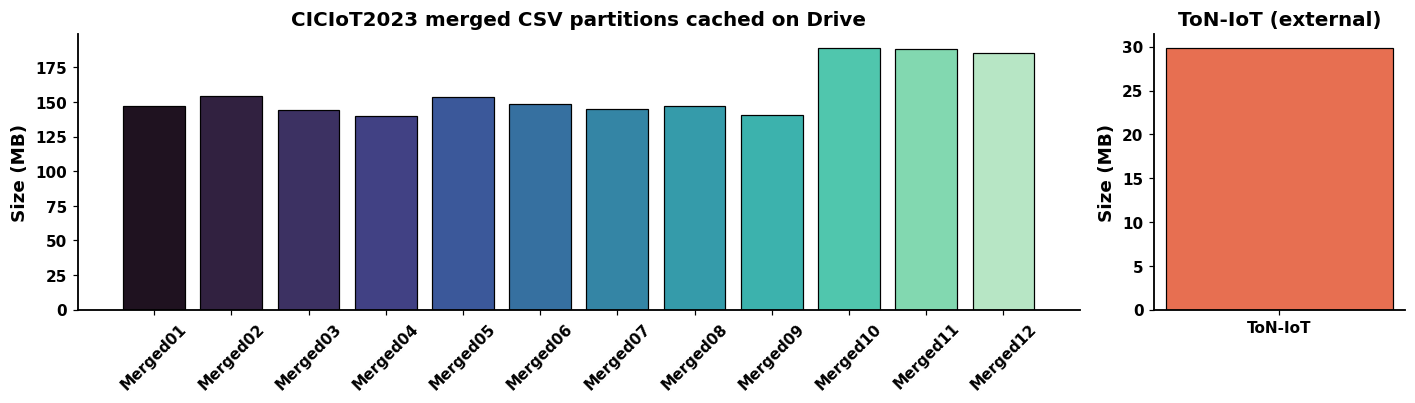

In [9]:
from huggingface_hub import hf_hub_download
HF_TMP = '/content/hf_tmp' if IN_COLAB else os.path.join(ROOT, '_hf_tmp')

def fetch(repo, files, name):
    out = os.path.join(D['raw'], name); os.makedirs(out, exist_ok=True)
    paths = []
    for f in files:
        dst = os.path.join(out, os.path.basename(f))
        if os.path.exists(dst) and os.path.getsize(dst) > 0:
            paths.append(dst); continue
        for attempt in range(6):
            try:
                p = hf_hub_download(repo_id=repo, filename=f, repo_type='dataset', local_dir=HF_TMP)
                shutil.copy(p, dst + '.part'); os.replace(dst + '.part', dst)
                try: os.remove(p)
                except OSError: pass
                print('downloaded', dst); break
            except Exception as e:
                print('retry', f, attempt, repr(e)[:120]); time.sleep(15 * (attempt + 1))
        if os.path.exists(dst): paths.append(dst)
    return paths

RAW = {'CICIoT2023': fetch(CFG['cic_repo'], CFG['cic_files'], 'CICIoT2023'),
       'ToN-IoT': fetch(CFG['ton_repo'], CFG['ton_files'], 'ToN-IoT')}
for k, v in RAW.items(): print(k, len(v), 'files,', round(sum(os.path.getsize(p) for p in v) / 1e6, 1), 'MB')

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [4, 1]})
sz = [os.path.getsize(p) / 1e6 for p in RAW['CICIoT2023']]
axes[0].bar(range(len(sz)), sz, color=sns.color_palette('mako', len(sz)), edgecolor='black', lw=0.8)
axes[0].set_xticks(range(len(sz))); axes[0].set_xticklabels([os.path.basename(p).replace('.csv', '') for p in RAW['CICIoT2023']], rotation=45)
axes[0].set_ylabel('Size (MB)'); axes[0].set_title('CICIoT2023 merged CSV partitions cached on Drive')
szt = [os.path.getsize(p) / 1e6 for p in RAW['ToN-IoT']]
axes[1].bar(['ToN-IoT'], szt, color='#e76f51', edgecolor='black', lw=0.8); axes[1].set_title('ToN-IoT (external)')
axes[1].set_ylabel('Size (MB)')
for ax in axes: bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F01_data_acquisition')

## Stage 2 · Loading, family mapping, cleaning, deduplication, capped sampling

In [5]:
def cic_family(lbl):
    s = str(lbl).upper().replace(' ', '')
    if s.startswith('BENIGN'): return 'Benign'
    if s.startswith('DDOS'): return 'DDoS'
    if s.startswith('DOS'): return 'DoS'
    if s.startswith('MIRAI'): return 'Mirai'
    if s.startswith('RECON') or any(w in s for w in ['VULNERABILITYSCAN', 'PORTSCAN', 'PINGSWEEP', 'HOSTDISCOVERY', 'OSSCAN']): return 'Recon'
    if 'SPOOF' in s or 'MITM' in s: return 'Spoofing'
    if 'BRUTE' in s or 'DICTIONARY' in s: return 'BruteForce'
    if any(w in s for w in ['SQL', 'XSS', 'COMMANDINJECTION', 'BACKDOOR', 'BROWSERHIJACK', 'UPLOAD']): return 'Web'
    return None

TON_DROP = ['src_ip', 'dst_ip', 'src_port', 'dst_port', 'dns_query', 'ssl_subject', 'ssl_issuer', 'http_uri',
            'http_user_agent', 'label', 'type', 'ts']
TON_CAT = ['proto', 'service', 'conn_state', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher',
           'ssl_resumed', 'ssl_established', 'http_method', 'http_version', 'http_orig_mime_types',
           'http_resp_mime_types', 'weird_name', 'weird_addl', 'weird_notice']

def finalize(df, feats, name, raw_counts):
    rng = np.random.default_rng(0)
    df[feats] = df[feats].apply(pd.to_numeric, errors='coerce').astype('float32')
    df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=feats)
    n0 = len(df)
    df = df.sort_values('order').drop_duplicates(subset=feats, keep='first')
    dup = n0 - len(df)
    keep = []
    for fam, g in df.groupby('family'):
        idx = g.index.values
        if len(idx) > CFG['cap_per_class']: idx = rng.choice(idx, CFG['cap_per_class'], replace=False)
        keep.append(idx)
    df = df.loc[np.concatenate(keep)]
    vc = df['family'].value_counts()
    df = df[df['family'].isin(vc[vc >= CFG['min_class']].index)]
    df = df.sort_values('order').reset_index(drop=True)
    const = [c for c in feats if df[c].nunique() <= 1]
    feats = [c for c in feats if c not in const]
    df = df[feats + ['family', 'fine', 'order']]
    df.to_parquet(os.path.join(D['interim'], name + '.parquet'), index=False)
    jdump({'features': feats, 'raw_counts': raw_counts, 'duplicates_removed': int(dup), 'constant_dropped': const},
          os.path.join(D['interim'], name + '_meta.json'))
    return df

def load_cic(paths, name='CICIoT2023'):
    cache = os.path.join(D['interim'], name + '.parquet')
    if os.path.exists(cache): return pd.read_parquet(cache)
    rng = np.random.default_rng(0); per_file = int(np.ceil(CFG['cap_per_class'] * 3 / len(paths)))
    parts, raw_counts, feats = [], {}, None
    for fi, p in enumerate(paths):
        df = pd.read_csv(p, low_memory=False)
        df.columns = [c.strip() for c in df.columns]
        lab = [c for c in df.columns if c.lower() == 'label'][0]
        df['order'] = fi * 10_000_000 + np.arange(len(df))
        df['fine'] = df[lab].astype(str).str.strip(); df = df.drop(columns=[lab])
        df['family'] = df['fine'].map(cic_family)
        for kk, vv in df['family'].fillna('Unmapped').value_counts().items(): raw_counts[kk] = raw_counts.get(kk, 0) + int(vv)
        df = df.dropna(subset=['family'])
        if feats is None: feats = [c for c in df.columns if c not in ['order', 'fine', 'family'] + CFG['drop_cic']]
        keep = []
        for fam, g in df.groupby('family'):
            idx = g.index.values
            if len(idx) > per_file: idx = rng.choice(idx, per_file, replace=False)
            keep.append(idx)
        parts.append(df.loc[np.sort(np.concatenate(keep)), feats + ['family', 'fine', 'order']])
        print(os.path.basename(p), len(df), '->', len(parts[-1])); del df; gc.collect()
    return finalize(pd.concat(parts, ignore_index=True), feats, name, raw_counts)

def load_ton(paths):
    cache = os.path.join(D['interim'], 'ToN-IoT.parquet')
    if os.path.exists(cache): return pd.read_parquet(cache)
    df = pd.concat([pd.read_csv(p, low_memory=False) for p in paths], ignore_index=True)
    df.columns = [c.strip() for c in df.columns]
    df['order'] = np.arange(len(df))
    df['family'] = df['type'].astype(str).str.strip().str.lower(); df['fine'] = df['family']
    raw_counts = {k: int(v) for k, v in df['family'].value_counts().items()}
    cats = [c for c in TON_CAT if c in df.columns]
    nums = [c for c in df.columns if c not in cats + TON_DROP + ['order', 'family', 'fine']]
    out = df[nums].apply(pd.to_numeric, errors='coerce').fillna(0).astype('float32')
    oh = []
    for c in cats:
        s = df[c].astype(str).str.strip()
        for v in s.value_counts().index[:6]:
            oh.append(pd.Series((s == v).astype('float32').values, name=f'{c}={v}'))
    out = pd.concat([out] + oh, axis=1)
    out.columns = [str(c).replace('[', '(').replace(']', ')') for c in out.columns]
    feats = list(out.columns)
    out['family'] = df['family'].values; out['fine'] = df['fine'].values; out['order'] = df['order'].values
    return finalize(out, feats, 'ToN-IoT', raw_counts)

DATA = {'CICIoT2023': load_cic(RAW['CICIoT2023']), 'ToN-IoT': load_ton(RAW['ToN-IoT'])}
META = {ds: jload(os.path.join(D['interim'], ds + '_meta.json')) for ds in DATA}
FEATS = {ds: META[ds]['features'] for ds in DATA}
FAMS = {ds: list(DATA[ds]['family'].value_counts().index) for ds in DATA}
for ds in DATA:
    print(ds, DATA[ds].shape, '| features:', len(FEATS[ds]), '| duplicates removed:', META[ds]['duplicates_removed'])
    print(DATA[ds]['family'].value_counts().to_dict())

CICIoT2023 (157359, 41) | features: 38 | duplicates removed: 52039
{'Spoofing': 25000, 'Recon': 25000, 'DDoS': 25000, 'Benign': 25000, 'DoS': 25000, 'Mirai': 25000, 'Web': 4796, 'BruteForce': 2563}
ToN-IoT (93199, 86) | features: 83 | duplicates removed: 117594
{'normal': 23659, 'injection': 19779, 'password': 15245, 'ddos': 11945, 'xss': 8649, 'dos': 6444, 'scanning': 4476, 'backdoor': 1966, 'mitm': 1036}


## Stage 3 · Exploratory analysis

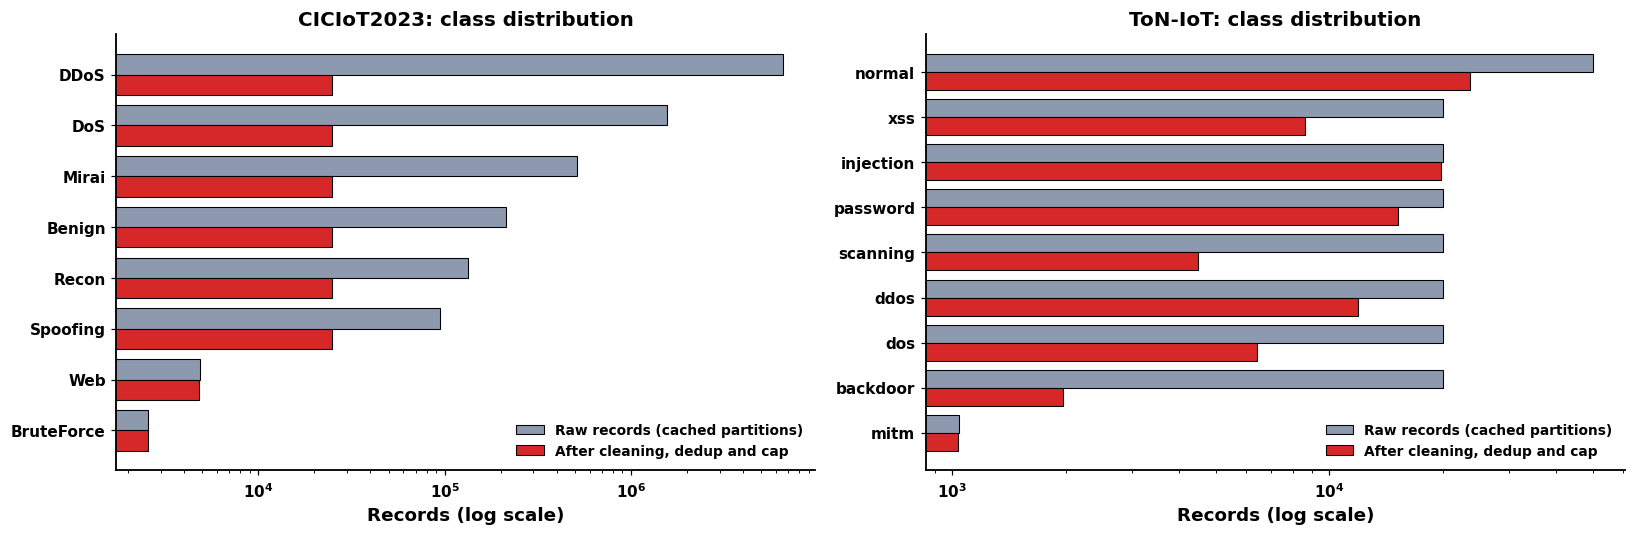

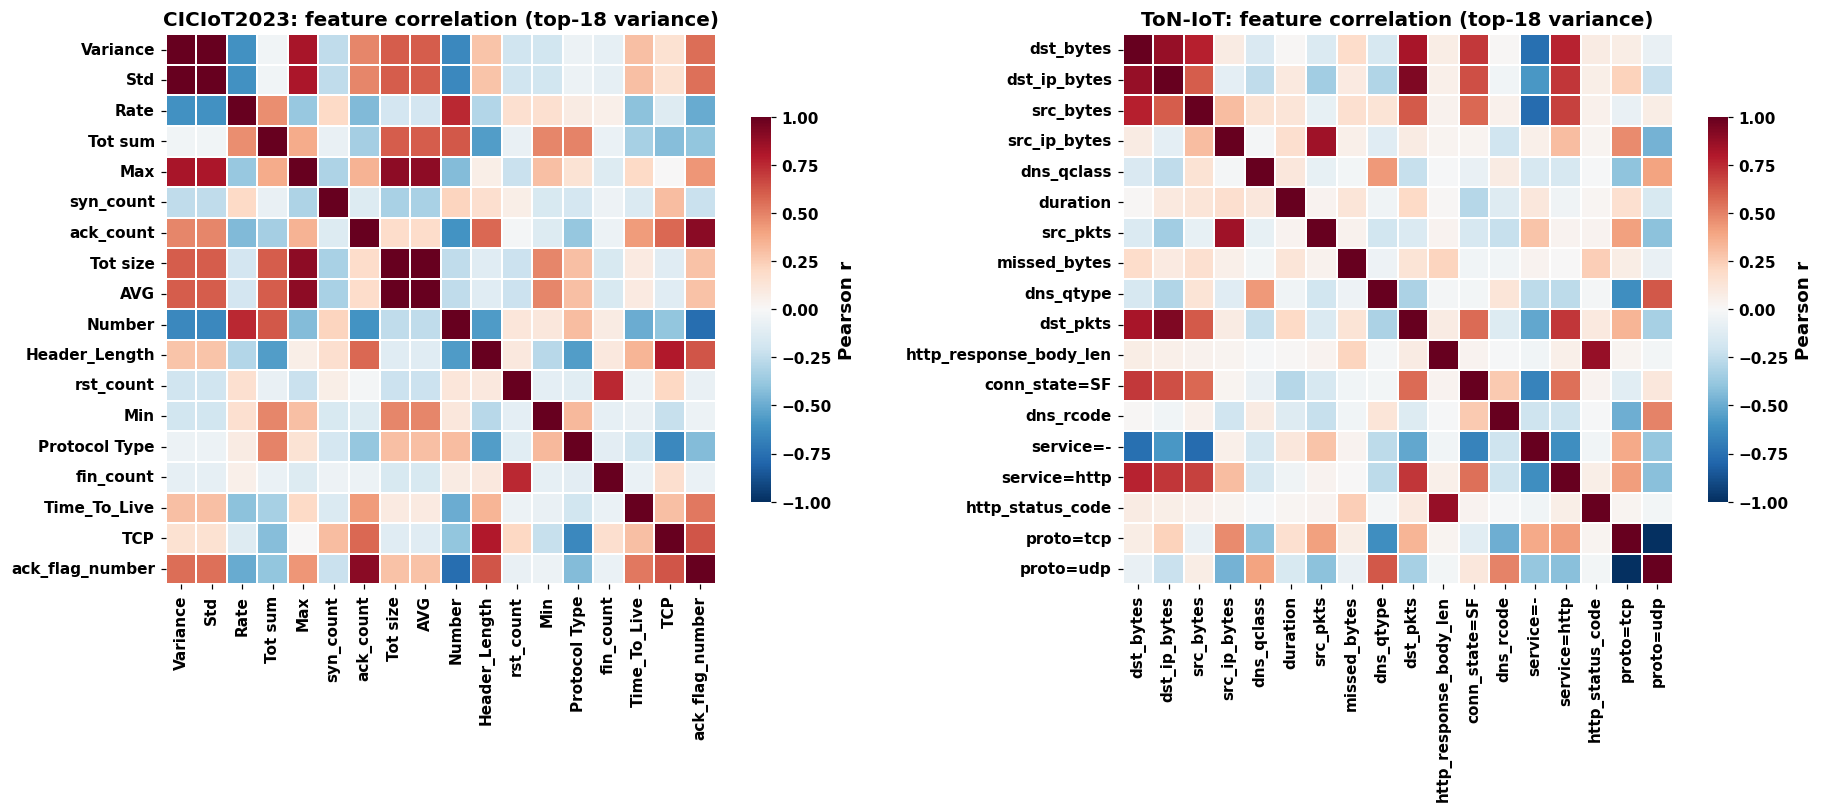

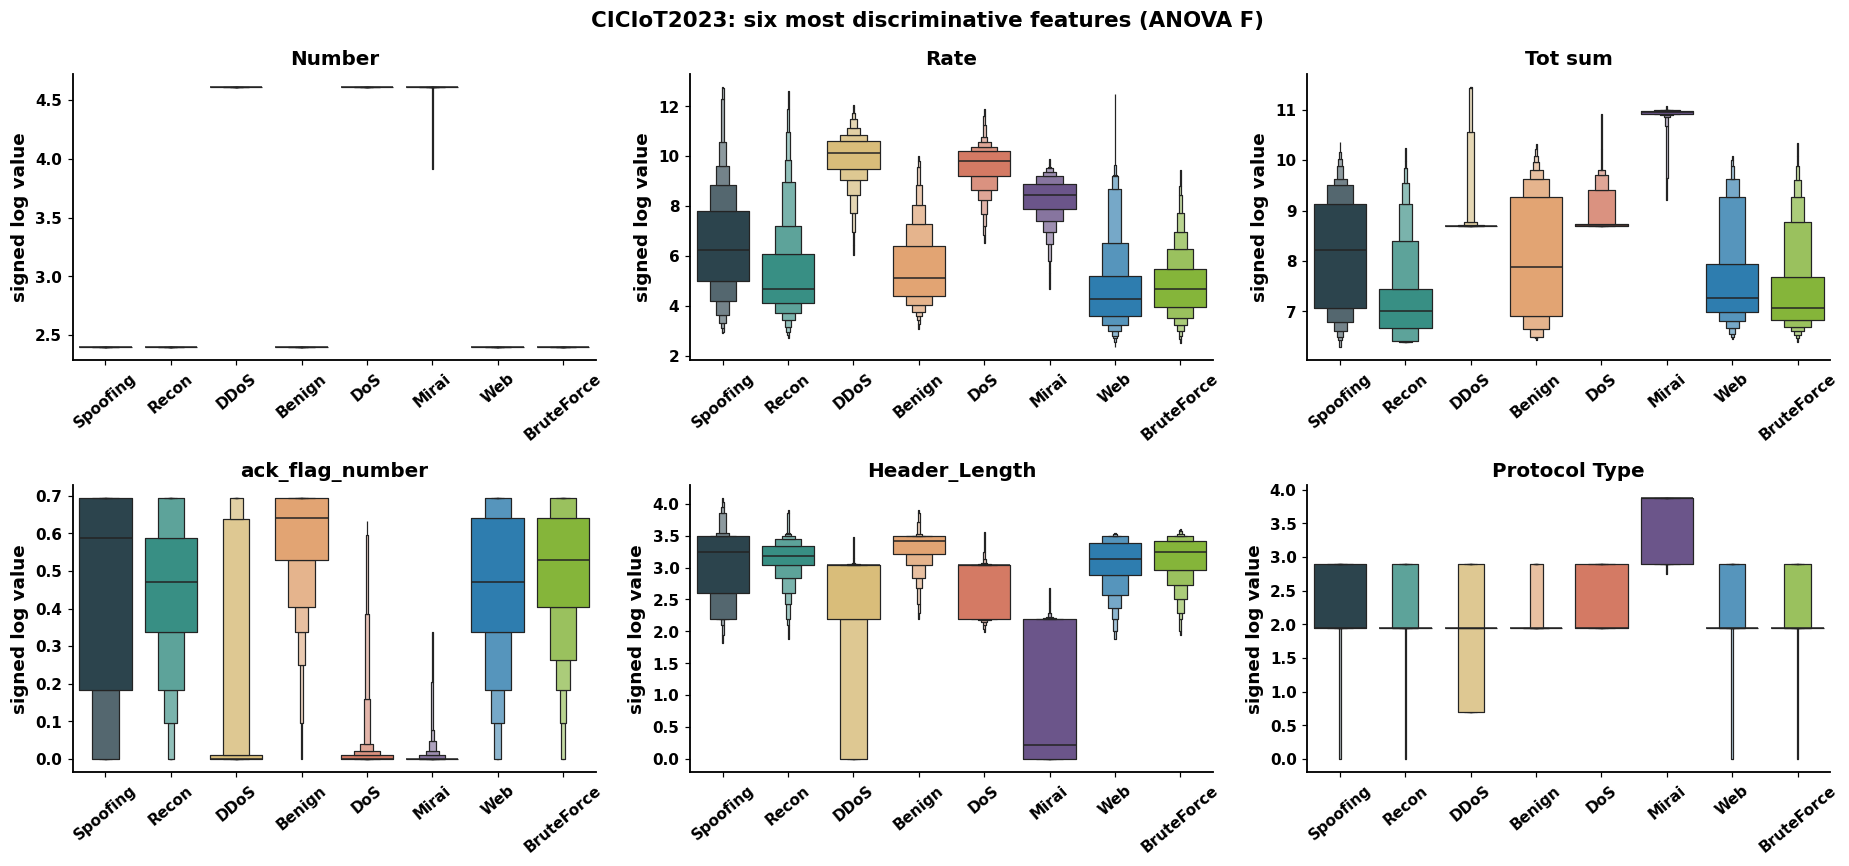

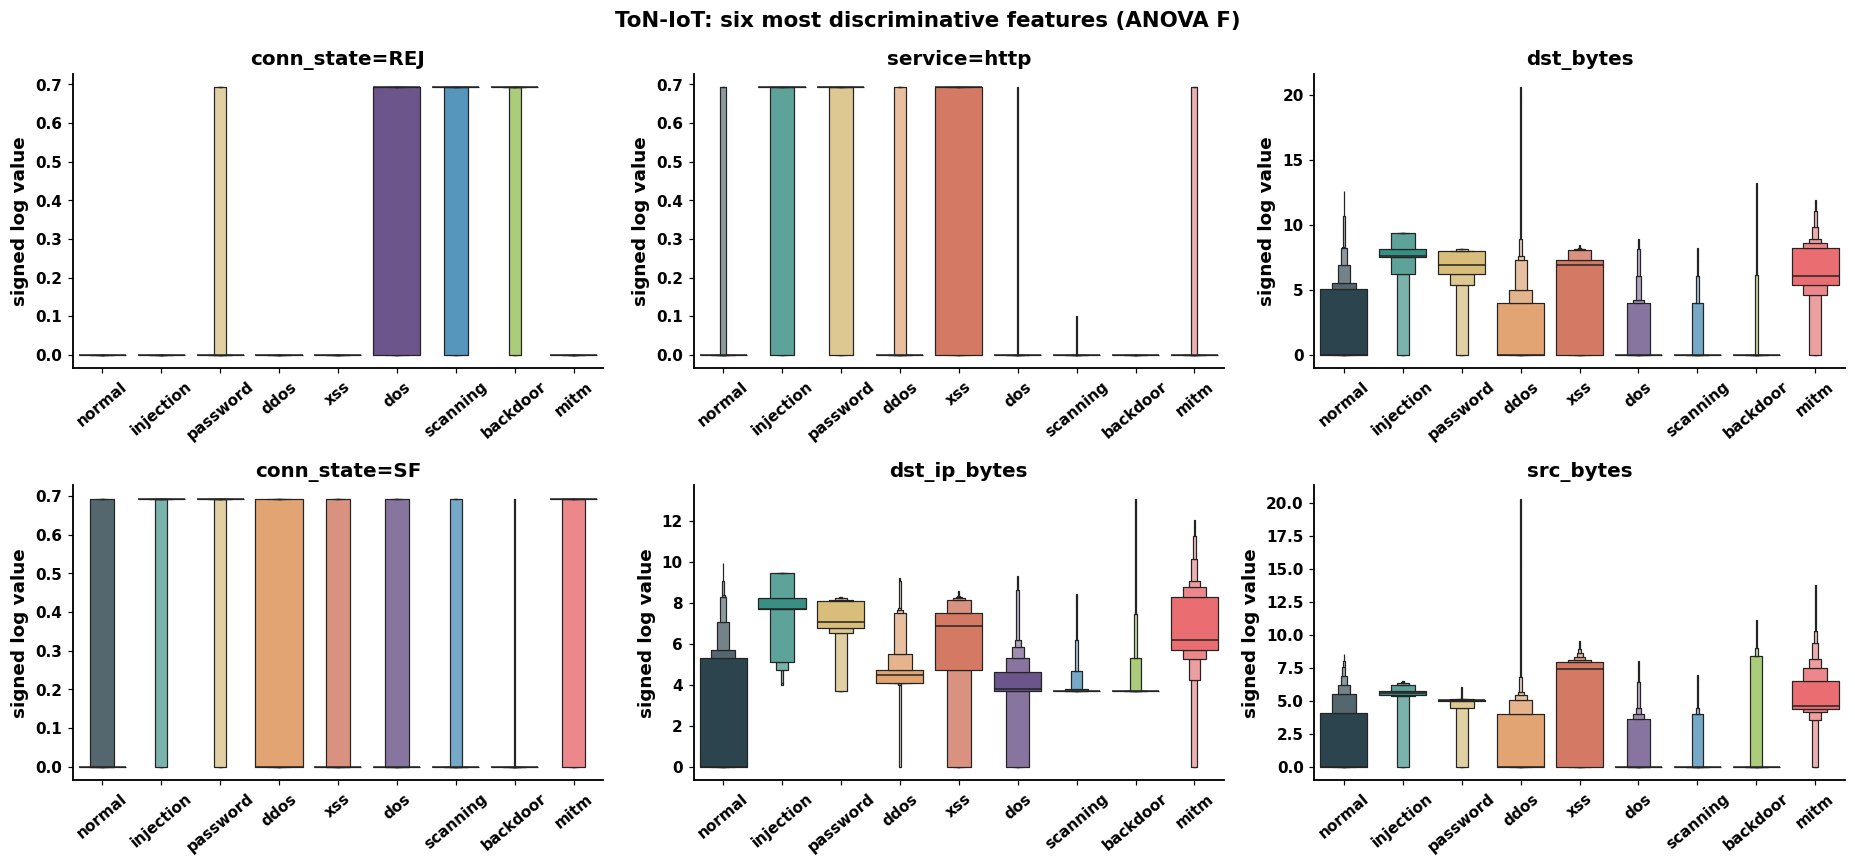

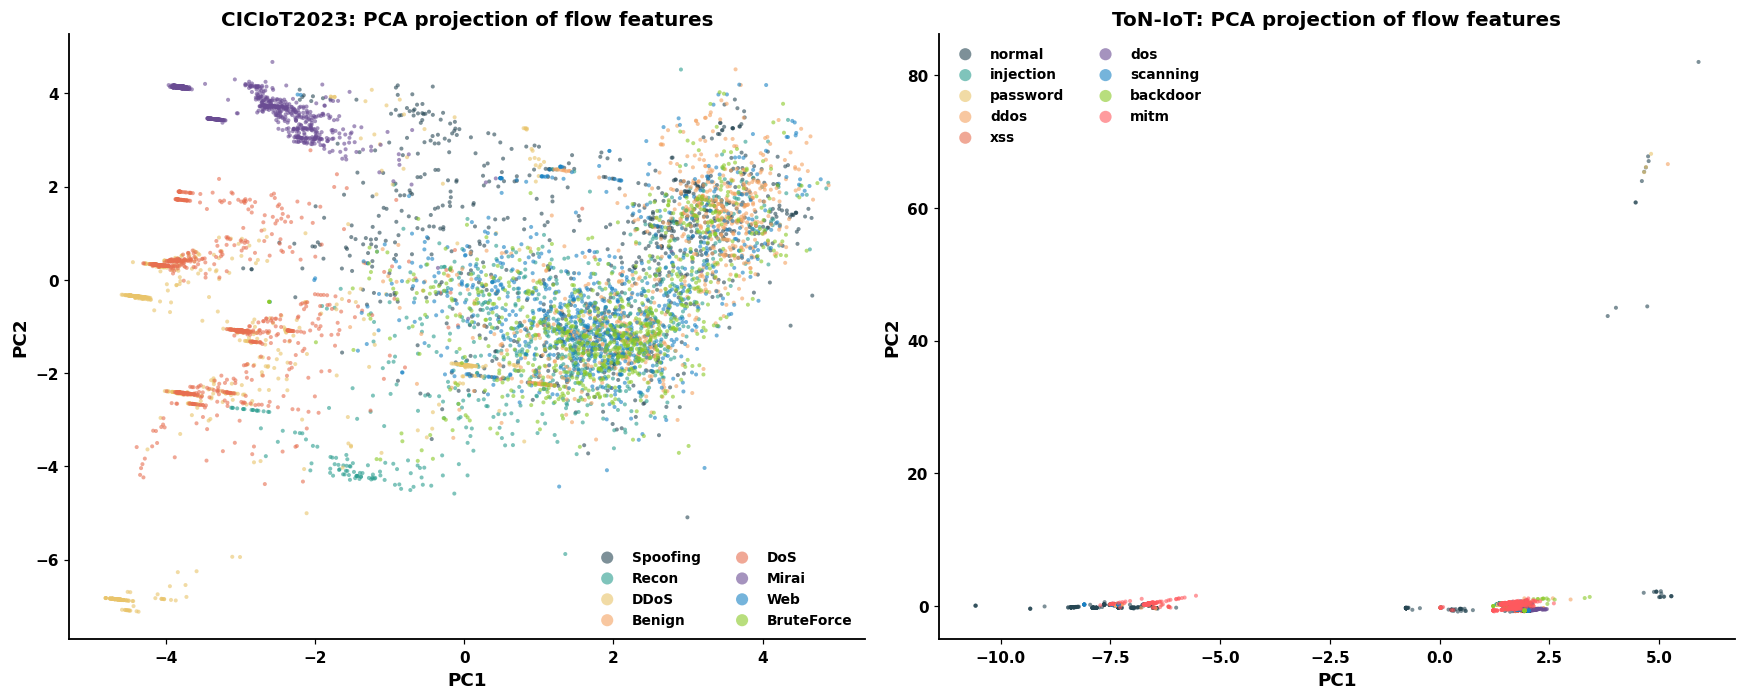

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, ds in zip(axes, DATA):
    raw = pd.Series(META[ds]['raw_counts']).drop('Unmapped', errors='ignore')
    smp = DATA[ds]['family'].value_counts()
    fams = [f for f in raw.sort_values(ascending=True).index if f in smp.index]
    y = np.arange(len(fams))
    ax.barh(y + 0.2, raw[fams].values, 0.4, color='#8d99ae', edgecolor='black', lw=0.7, label='Raw records (cached partitions)')
    ax.barh(y - 0.2, smp[fams].values, 0.4, color='#d62828', edgecolor='black', lw=0.7, label='After cleaning, dedup and cap')
    ax.set_xscale('log'); ax.set_yticks(y); ax.set_yticklabels(fams); ax.set_xlabel('Records (log scale)')
    ax.set_title(f'{ds}: class distribution'); ax.legend(loc='lower right'); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F02_class_distribution')

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, ds in zip(axes, DATA):
    df = DATA[ds].sample(min(30000, len(DATA[ds])), random_state=0)
    X = np.sign(df[FEATS[ds]]) * np.log1p(np.abs(df[FEATS[ds]]))
    top = X.var().sort_values(ascending=False).index[:18]
    sns.heatmap(X[top].corr(), ax=ax, cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True,
                cbar_kws={'shrink': 0.7, 'label': 'Pearson r'}, linewidths=0.3, linecolor='white')
    ax.set_title(f'{ds}: feature correlation (top-18 variance)'); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F03_feature_correlation')

for ds in DATA:
    df = strat_sample(DATA[ds], 1500, 0)
    X = np.sign(df[FEATS[ds]]) * np.log1p(np.abs(df[FEATS[ds]]))
    Fv, _ = f_classif(X.fillna(0), df['family']); Fv = np.nan_to_num(Fv)
    top = [FEATS[ds][i] for i in np.argsort(-Fv)[:6]]
    fc = fam_colors(FAMS[ds])
    fig, axes = plt.subplots(2, 3, figsize=(17, 8))
    for ax, f in zip(axes.ravel(), top):
        sns.boxenplot(data=pd.DataFrame({'v': X[f].values, 'family': df['family'].values}), x='family', y='v',
                      order=FAMS[ds], palette=fc, ax=ax, linewidth=0.8, showfliers=False)
        ax.set_title(f[:34]); ax.set_xlabel(''); ax.set_ylabel('signed log value'); ax.tick_params(axis='x', rotation=40); bold_ticks(ax)
    fig.suptitle(f'{ds}: six most discriminative features (ANOVA F)', fontweight='bold', fontsize=14)
    plt.tight_layout(); savefig(fig, f'F04_top_features_{ds}')

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, ds in zip(axes, DATA):
    df = strat_sample(DATA[ds], 800, 1)
    X = np.sign(df[FEATS[ds]]) * np.log1p(np.abs(df[FEATS[ds]])); X = (X - X.mean()) / (X.std() + 1e-6)
    Z = PCA(2, random_state=0).fit_transform(X.fillna(0))
    fc = fam_colors(FAMS[ds])
    for f in FAMS[ds]:
        m = (df['family'] == f).values
        ax.scatter(Z[m, 0], Z[m, 1], s=7, alpha=0.6, color=fc[f], label=f, edgecolors='none')
    ax.set_title(f'{ds}: PCA projection of flow features'); ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
    ax.legend(markerscale=3, ncol=2, loc='best'); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F05_pca_projection')

## Stage 4 · Temporal stratified split, transformation, open-set protocols

CICIoT2023 open-set protocols: ['S1', 'S2', 'S3']
ToN-IoT open-set protocols: ['T2', 'T3']


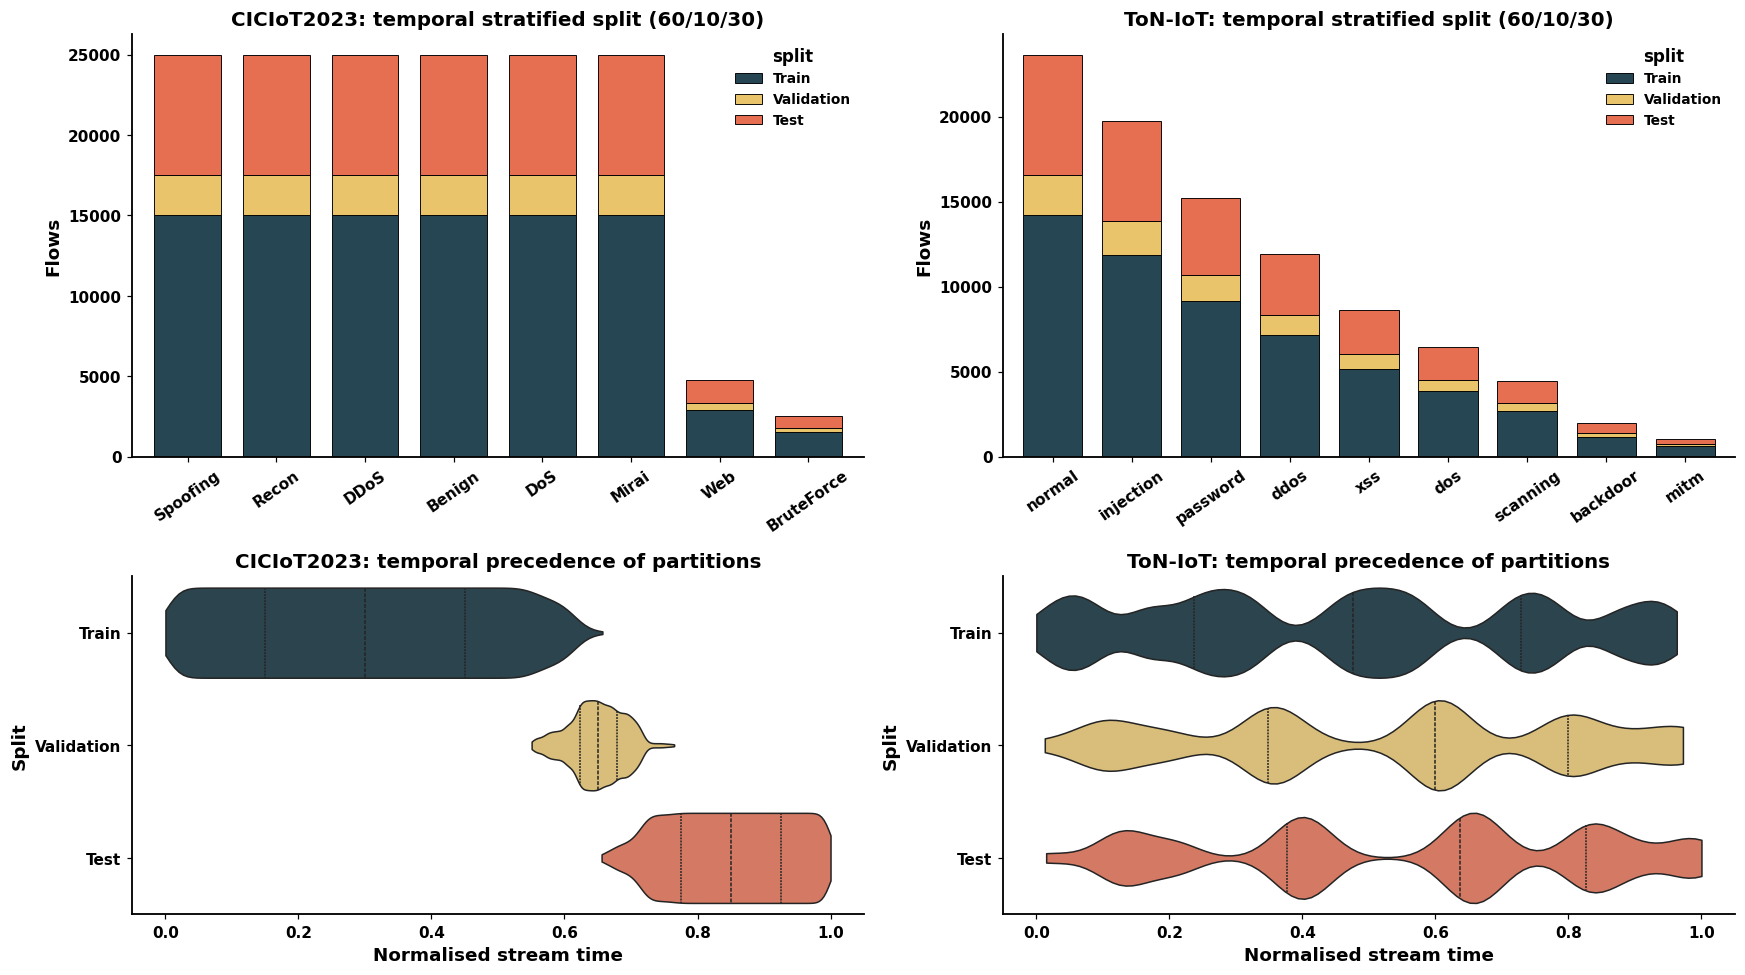

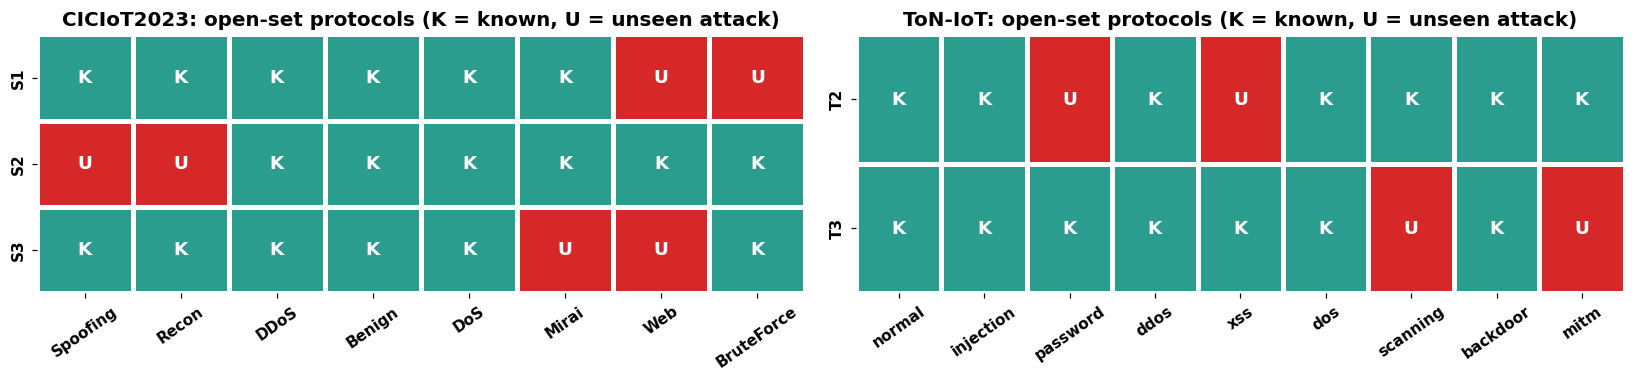

In [11]:
def build_proc(ds):
    px, pm = os.path.join(D['proc'], ds + '_X.npy'), os.path.join(D['proc'], ds + '_meta.parquet')
    if os.path.exists(px) and os.path.exists(pm): return np.load(px), pd.read_parquet(pm)
    df = DATA[ds].reset_index(drop=True)
    split = np.zeros(len(df), dtype=np.int8)
    a, b = CFG['split_frac'][0], CFG['split_frac'][0] + CFG['split_frac'][1]
    for fam, g in df.groupby('family'):
        idx = g.sort_values('order').index.values; n = len(idx)
        split[idx[int(n * a):int(n * b)]] = 1; split[idx[int(n * b):]] = 2
    X = df[FEATS[ds]].values.astype(np.float32)
    X = np.sign(X) * np.log1p(np.abs(X))
    meta = pd.DataFrame({'family': df['family'].values, 'order': df['order'].values, 'split': split,
                         't': (rankdata(df['order'].values) - 1) / max(len(df) - 1, 1)})
    np.save(px, X.astype(np.float32)); meta.to_parquet(pm, index=False)
    return X, meta

PROC = {ds: build_proc(ds) for ds in DATA}

VALID_SPLITS = {}
for ds in DATA:
    VALID_SPLITS[ds] = [sp for sp, unk in CFG['open_splits'][ds].items() if all(u in FAMS[ds] for u in unk)]
    print(ds, 'open-set protocols:', VALID_SPLITS[ds])

def feature_groups(feats):
    proto = {'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Protocol Type'}
    size = {'Header_Length', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'Variance', 'Number'}
    rules = [('Flags', lambda f: 'flag' in f.lower() or f.lower() in ('ack_count', 'syn_count', 'fin_count', 'rst_count')),
             ('Protocol', lambda f: f in proto or f.startswith(('proto=', 'service='))),
             ('Size', lambda f: f in size or any(k in f for k in ('bytes', 'pkts', 'body_len'))),
             ('Rate/Time', lambda f: f in ('Rate', 'Time_To_Live', 'IAT', 'duration')),
             ('Connection', lambda f: f.startswith(('conn_state', 'missed', 'weird'))),
             ('DNS', lambda f: f.startswith('dns')), ('TLS', lambda f: f.startswith('ssl')), ('HTTP', lambda f: f.startswith('http'))]
    groups = {}
    for i, f in enumerate(feats):
        g = next((n for n, r in rules if r(f)), 'Other'); groups.setdefault(g, []).append(i)
    return groups

CUR_GROUPS = {}
_BCACHE = {}
def get_bundle(ds, sp):
    key = (ds, sp)
    if key in _BCACHE: return _BCACHE[key]
    _BCACHE.clear(); gc.collect()
    X, meta = PROC[ds]
    unk = CFG['open_splits'][ds][sp]; known = [f for f in FAMS[ds] if f not in unk]
    cmap = {f: i for i, f in enumerate(known)}; C = len(known)
    y = meta['family'].map(lambda f: cmap.get(f, C)).values.astype(np.int64)
    s = meta['split'].values
    idx = {'tr': np.where((s == 0) & (y < C))[0], 'va': np.where((s == 1) & (y < C))[0], 'te': np.where(s == 2)[0]}
    idx['te'] = idx['te'][np.argsort(meta['t'].values[idx['te']], kind='stable')]
    mu = X[idx['tr']].mean(0); sd = X[idx['tr']].std(0); sd[sd < 1e-6] = 1.0
    Xs = np.clip((X - mu) / sd, -10, 10).astype(np.float32)
    B = dict(ds=ds, sp=sp, known=known, unknown=unk, C=C, y=y, idx=idx, Xnp=Xs, t=meta['t'].values.astype(np.float32),
             fam=np.asarray(meta['family'].astype(str).tolist(), dtype=object), X=torch.tensor(Xs, device=DEVICE), nF=Xs.shape[1])
    counts = np.bincount(y[idx['tr']], minlength=C).astype(np.float64)
    w = counts ** -0.5; B['w'] = torch.tensor(w / w.mean() * 1.0, dtype=torch.float32, device=DEVICE)
    B['groups'] = feature_groups(FEATS[ds]); CUR_GROUPS.clear(); CUR_GROUPS.update(B['groups'])
    _BCACHE[key] = B
    return B

fig, axes = plt.subplots(2, 2, figsize=(16, 9), gridspec_kw={'height_ratios': [1.25, 1]})
for j, ds in enumerate(DATA):
    X, meta = PROC[ds]
    ct = pd.crosstab(meta['family'], meta['split']).reindex(FAMS[ds]).rename(columns={0: 'Train', 1: 'Validation', 2: 'Test'})
    ct.plot(kind='bar', stacked=True, ax=axes[0, j], color=['#264653', '#e9c46a', '#e76f51'], edgecolor='black', lw=0.6, width=0.75)
    axes[0, j].set_title(f'{ds}: temporal stratified split (60/10/30)'); axes[0, j].set_ylabel('Flows'); axes[0, j].set_xlabel('')
    axes[0, j].tick_params(axis='x', rotation=35); bold_ticks(axes[0, j])
    sns.violinplot(data=meta.assign(Split=meta['split'].map({0: 'Train', 1: 'Validation', 2: 'Test'})), x='t', y='Split',
                   ax=axes[1, j], palette=['#264653', '#e9c46a', '#e76f51'], cut=0, inner='quartile', linewidth=1)
    axes[1, j].set_xlabel('Normalised stream time'); axes[1, j].set_title(f'{ds}: temporal precedence of partitions'); bold_ticks(axes[1, j])
plt.tight_layout(); savefig(fig, 'F06_temporal_split')

fig, axes = plt.subplots(1, 2, figsize=(15, 3.6))
for ax, ds in zip(axes, DATA):
    M = pd.DataFrame([[1 if f in CFG['open_splits'][ds][sp] else 0 for f in FAMS[ds]] for sp in VALID_SPLITS[ds]],
                     index=VALID_SPLITS[ds], columns=FAMS[ds])
    sns.heatmap(M, ax=ax, cmap=sns.color_palette(['#2a9d8f', '#d62828']), cbar=False, linewidths=2, linecolor='white',
                annot=M.replace({0: 'K', 1: 'U'}).values, fmt='', annot_kws={'weight': 'bold', 'color': 'white', 'size': 12})
    ax.set_title(f'{ds}: open-set protocols (K = known, U = unseen attack)'); ax.tick_params(axis='x', rotation=35); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F07_open_set_protocols')

## Stage 5 · Temporal flow graph construction

In [12]:
@torch.no_grad()
def knn_torch(Q, Bk, k, self_pos=None, chunk=1024):
    bn = (Bk ** 2).sum(1)
    I, Dd = [], []
    for s in range(0, len(Q), chunk):
        q = Q[s:s + chunk]
        d = ((q ** 2).sum(1, keepdim=True) + bn[None] - 2 * q @ Bk.T).clamp_(min=0)
        if self_pos is not None:
            d[torch.arange(len(q), device=q.device), self_pos[s:s + chunk]] = float('inf')
        dd, ii = torch.topk(d, k, largest=False)
        I.append(ii.cpu()); Dd.append(dd.sqrt().cpu())
    return torch.cat(I).numpy().astype(np.int32), torch.cat(Dd).numpy().astype(np.float32)

def build_graph(ds, sp):
    p = os.path.join(D['graph'], f'{ds}_{sp}.npz')
    if os.path.exists(p): return dict(np.load(p))
    B = get_bundle(ds, sp); X = B['X']; tr = B['idx']['tr']
    bank = X[torch.tensor(tr, device=DEVICE)]
    out = {}
    for part in ['tr', 'va', 'te']:
        ids = B['idx'][part]; Q = X[torch.tensor(ids, device=DEVICE)]
        sp_ = torch.arange(len(ids), device=DEVICE) if part == 'tr' else None
        I, Dd = knn_torch(Q, bank, CFG['k_max'], self_pos=sp_)
        out[f'{part}_nidx'] = I; out[f'{part}_nd'] = Dd
        out[f'{part}_ndt'] = (B['t'][ids][:, None] - B['t'][tr][I]).astype(np.float32)
    out['dscale'] = np.array(np.median(out['tr_nd'][:, :CFG['k']]) + 1e-6, dtype=np.float32)
    np.savez_compressed(p, **out)
    return out

GRAPHS = {}
for ds in DATA:
    for sp in VALID_SPLITS[ds]:
        t0 = time.time(); g = build_graph(ds, sp); GRAPHS[(ds, sp)] = p = os.path.join(D['graph'], f'{ds}_{sp}.npz')
        print(ds, sp, 'graph ready', {k: v.shape for k, v in g.items() if k.endswith('nidx')}, f'{time.time() - t0:.1f}s')

def graph_tensors(ds, sp, k):
    g = dict(np.load(GRAPHS[(ds, sp)])); ds_ = float(g['dscale']); out = {}
    for part in ['tr', 'va', 'te']:
        out[part] = dict(nidx=torch.tensor(g[f'{part}_nidx'][:, :k].astype(np.int64), device=DEVICE),
                         nd=torch.tensor(np.log1p(g[f'{part}_nd'][:, :k] / ds_), device=DEVICE),
                         ndt=torch.tensor(g[f'{part}_ndt'][:, :k], device=DEVICE))
    return out

CICIoT2023 S1 graph ready {'tr_nidx': (90000, 20), 'va_nidx': (15000, 20), 'te_nidx': (47208, 20)} 2.8s
CICIoT2023 S2 graph ready {'tr_nidx': (64414, 20), 'va_nidx': (10737, 20), 'te_nidx': (47208, 20)} 1.8s
CICIoT2023 S3 graph ready {'tr_nidx': (76537, 20), 'va_nidx': (12757, 20), 'te_nidx': (47208, 20)} 2.1s
ToN-IoT T2 graph ready {'tr_nidx': (41580, 20), 'va_nidx': (6931, 20), 'te_nidx': (27963, 20)} 1.0s
ToN-IoT T3 graph ready {'tr_nidx': (52610, 20), 'va_nidx': (8768, 20), 'te_nidx': (27963, 20)} 1.7s


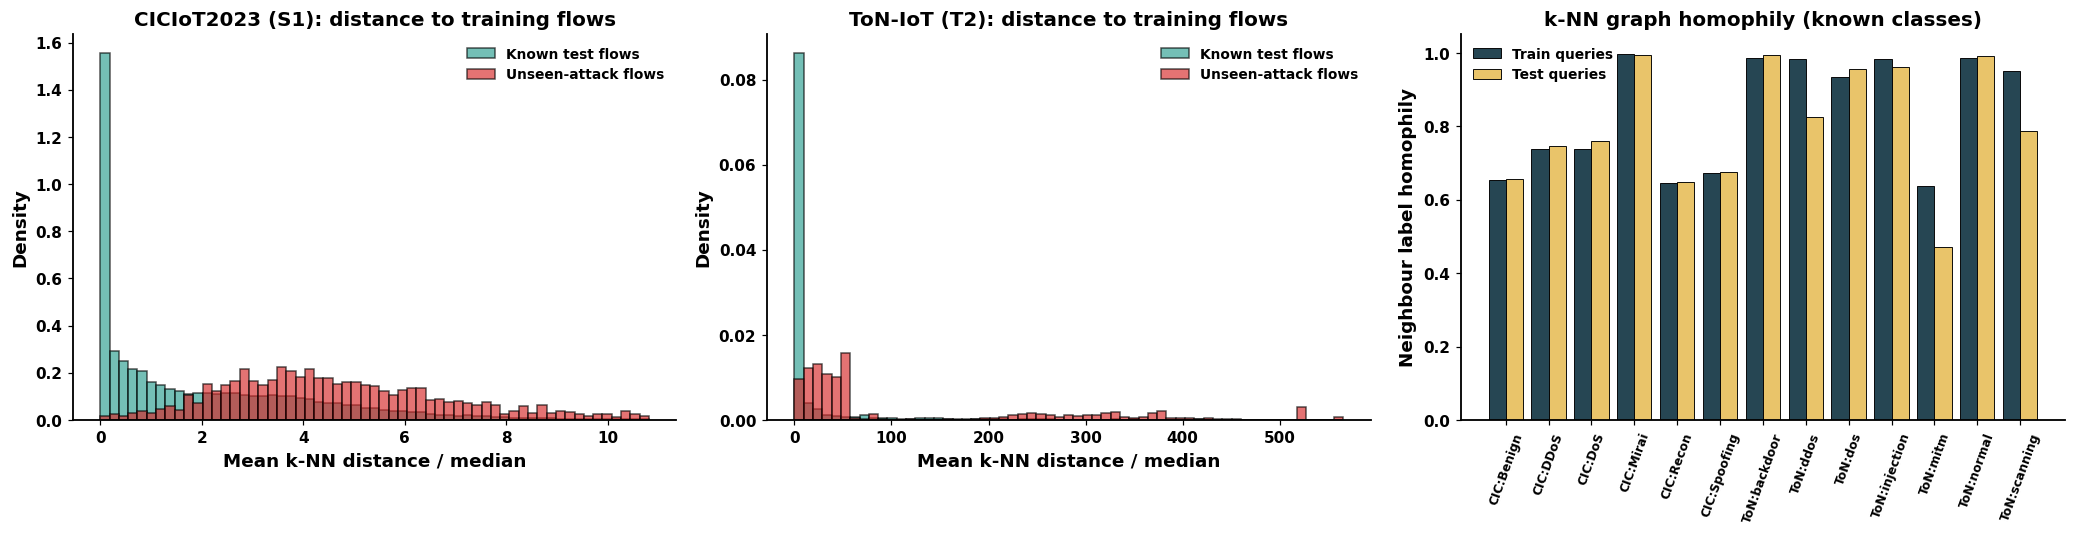

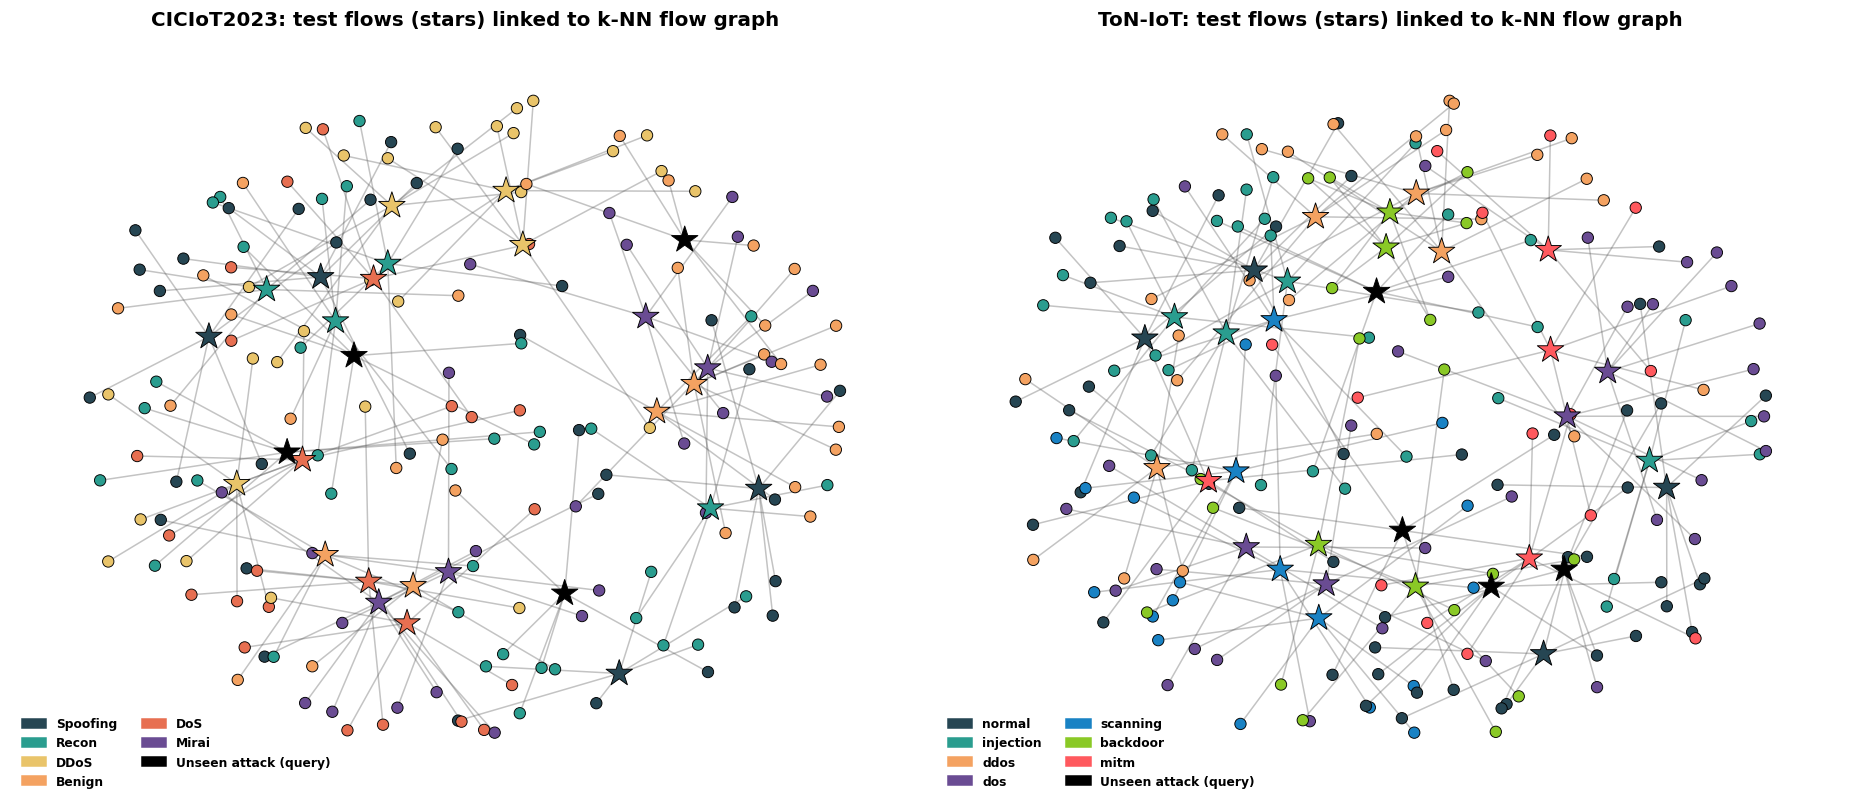

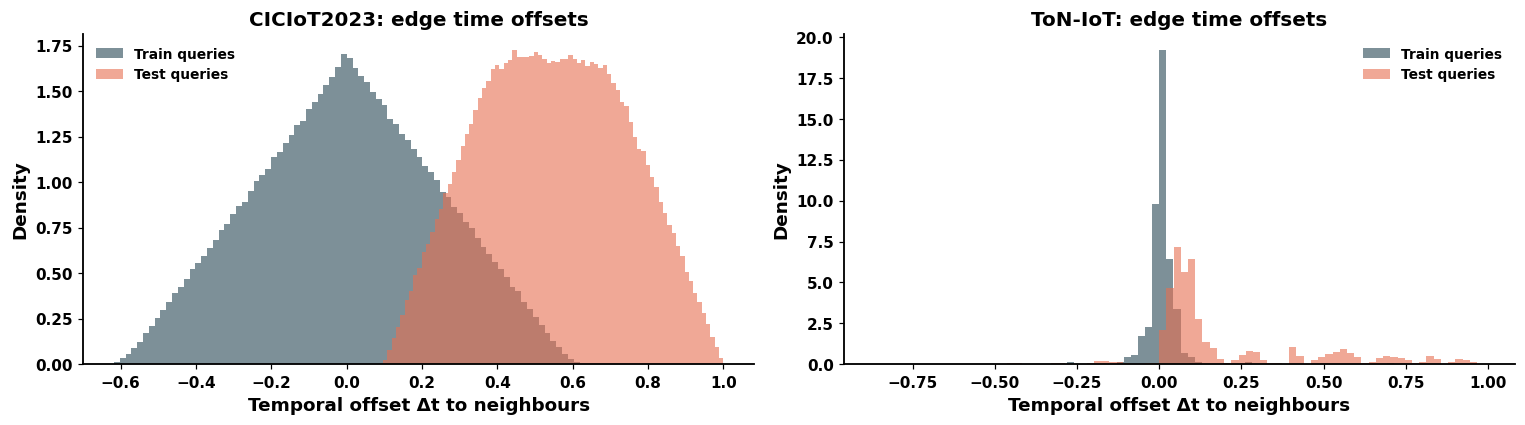

In [13]:
import networkx as nx
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
rows = []
for j, ds in enumerate(DATA):
    sp = VALID_SPLITS[ds][0]; B = get_bundle(ds, sp); g = dict(np.load(GRAPHS[(ds, sp)]))
    md_ = g['te_nd'][:, :CFG['k']].mean(1) / g['dscale']; unk = B['y'][B['idx']['te']] == B['C']
    ax = axes[j]
    bins = np.linspace(0, np.quantile(md_, 0.99), 60)
    ax.hist(md_[~unk], bins=bins, density=True, alpha=0.65, color='#2a9d8f', edgecolor='black', lw=0.3, label='Known test flows')
    ax.hist(md_[unk], bins=bins, density=True, alpha=0.65, color='#d62828', edgecolor='black', lw=0.3, label='Unseen-attack flows')
    ax.set_title(f'{ds} ({sp}): distance to training flows'); ax.set_xlabel('Mean k-NN distance / median'); ax.set_ylabel('Density')
    ax.legend(); bold_ticks(ax)
    trf = B['fam'][B['idx']['tr']]
    for part in ['tr', 'te']:
        qf = B['fam'][B['idx'][part]]; nf = trf[g[f'{part}_nidx'][:, :CFG['k']]]
        h = (nf == qf[:, None]).mean(1)
        for f in FAMS[ds]:
            m = qf == f
            if m.any() and f in B['known']: rows.append(dict(dataset=ds, family=f, part={'tr': 'Train', 'te': 'Test'}[part], homophily=h[m].mean()))
H = pd.DataFrame(rows)
Hp = H.pivot_table(index=['dataset', 'family'], columns='part', values='homophily').reset_index()
Hp['lab'] = Hp['dataset'].str[:3] + ':' + Hp['family']
x = np.arange(len(Hp))
axes[2].bar(x - 0.2, Hp['Train'], 0.4, color='#264653', edgecolor='black', lw=0.6, label='Train queries')
axes[2].bar(x + 0.2, Hp['Test'], 0.4, color='#e9c46a', edgecolor='black', lw=0.6, label='Test queries')
axes[2].set_xticks(x); axes[2].set_xticklabels(Hp['lab'], rotation=70, fontsize=8); axes[2].set_ylim(0, 1.05)
axes[2].set_ylabel('Neighbour label homophily'); axes[2].set_title('k-NN graph homophily (known classes)'); axes[2].legend(); bold_ticks(axes[2])
plt.tight_layout(); savefig(fig, 'F08_graph_distance_homophily')

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
for ax, ds in zip(axes, DATA):
    sp = VALID_SPLITS[ds][0]; B = get_bundle(ds, sp); g = dict(np.load(GRAPHS[(ds, sp)]))
    rng = np.random.default_rng(3); te = B['idx']['te']; y = B['y'][te]
    pick = np.concatenate([rng.choice(np.where(y == c)[0], min(4, (y == c).sum()), replace=False) for c in np.unique(y)])
    G = nx.Graph(); trf = B['fam'][B['idx']['tr']]
    for q in pick:
        qn = f'q{q}'; G.add_node(qn, fam=B['fam'][te[q]], kind='query')
        for n, dd in zip(g['te_nidx'][q, :6], g['te_nd'][q, :6]):
            G.add_node(f'b{n}', fam=trf[n], kind='bank'); G.add_edge(qn, f'b{n}', w=float(dd))
    pos = nx.spring_layout(G, seed=4, k=0.35)
    fc = fam_colors(FAMS[ds])
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, width=1.0, edge_color='#555555')
    for kind, shape, size in [('bank', 'o', 55), ('query', '*', 330)]:
        nodes = [n for n, a in G.nodes(data=True) if a['kind'] == kind]
        cols = ['#000000' if (kind == 'query' and G.nodes[n]['fam'] in B['unknown']) else fc[G.nodes[n]['fam']] for n in nodes]
        nx.draw_networkx_nodes(G, pos, nodelist=nodes, node_color=cols, node_shape=shape, node_size=size, ax=ax, edgecolors='black', linewidths=0.6)
    hand = [mpatches.Patch(color=fc[f], label=f) for f in B['known']] + [mpatches.Patch(color='black', label='Unseen attack (query)')]
    ax.legend(handles=hand, loc='lower left', fontsize=8, ncol=2); ax.set_title(f'{ds}: test flows (stars) linked to k-NN flow graph'); ax.axis('off')
plt.tight_layout(); savefig(fig, 'F09_temporal_flow_graph')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, ds in zip(axes, DATA):
    g = dict(np.load(GRAPHS[(ds, VALID_SPLITS[ds][0])]))
    for part, c, lab in [('tr', '#264653', 'Train queries'), ('te', '#e76f51', 'Test queries')]:
        ax.hist(g[f'{part}_ndt'][:, :CFG['k']].ravel(), bins=80, density=True, alpha=0.6, color=c, label=lab)
    ax.set_xlabel('Temporal offset Δt to neighbours'); ax.set_ylabel('Density'); ax.set_title(f'{ds}: edge time offsets'); ax.legend(); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F10_edge_time_offsets')

## Stage 6 · Model definitions (TokenGauss-Former and deep baselines)

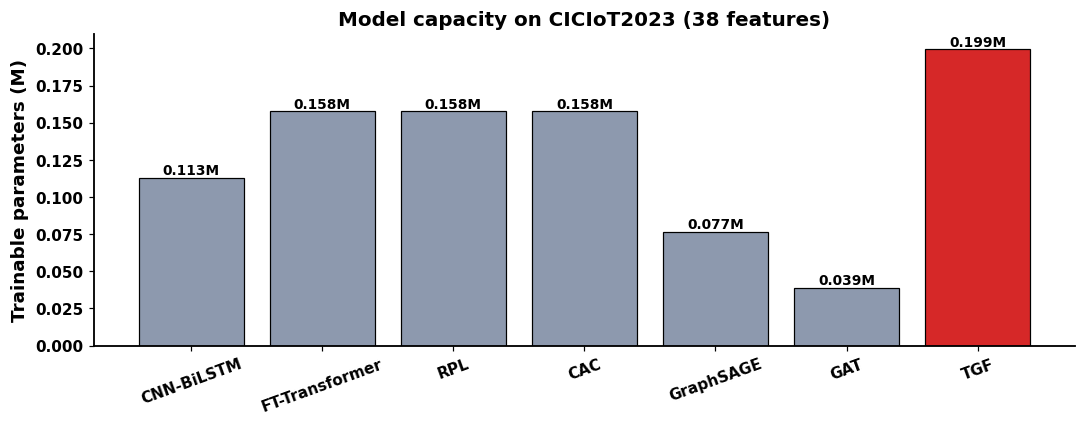

In [14]:
class FeatureTokenizer(nn.Module):
    def __init__(s, nF, d):
        super().__init__()
        s.W = nn.Parameter(torch.randn(nF, d) * 0.02); s.b = nn.Parameter(torch.zeros(nF, d))
        s.cls = nn.Parameter(torch.randn(1, 1, d) * 0.02)
    def forward(s, x):
        return torch.cat([s.cls.expand(x.size(0), -1, -1), x.unsqueeze(-1) * s.W + s.b], 1)

class FTEncoder(nn.Module):
    def __init__(s, nF, d, heads, layers, drop):
        super().__init__()
        s.tok = FeatureTokenizer(nF, d)
        L = nn.TransformerEncoderLayer(d, heads, d * 2, drop, activation='gelu', batch_first=True, norm_first=True)
        s.tf = nn.TransformerEncoder(L, layers, enable_nested_tensor=False); s.norm = nn.LayerNorm(d)
    def forward(s, x): return s.norm(s.tf(s.tok(x))[:, 0])

def mahal_t(Z, mu, prec):
    ZP = Z @ prec
    return ((ZP * Z).sum(1, keepdim=True) - 2 * ZP @ mu.T + ((mu @ prec) * mu).sum(1)[None]).clamp(min=0)

def strat_idx(y, n, seed=0):
    rng = np.random.default_rng(seed); cls = np.unique(y); per = max(1, n // len(cls)); out = []
    for c in cls:
        ids = np.where(y == c)[0]; out.append(rng.choice(ids, min(per, len(ids)), replace=False))
    return np.sort(np.concatenate(out))

def fit_mixture(Z, y, C, M, seed=0):
    from sklearn.cluster import KMeans
    from sklearn.covariance import LedoitWolf
    mus, cls, res = [], [], []
    for c in range(C):
        Zc = Z[y == c]
        if len(Zc) == 0: continue
        Mc = int(min(M, max(1, len(Zc) // 50)))
        if Mc == 1: cent = Zc.mean(0, keepdims=True); a = np.zeros(len(Zc), dtype=int)
        else:
            km = KMeans(Mc, n_init=3, random_state=seed).fit(Zc); cent, a = km.cluster_centers_, km.labels_
        mus.append(cent); cls += [c] * len(cent); res.append(Zc - cent[a])
    lw = LedoitWolf().fit(np.concatenate(res))
    return dict(mu=np.vstack(mus).astype(np.float32), cls=np.array(cls), cov=lw.covariance_.astype(np.float32),
                prec=lw.precision_.astype(np.float32))

@torch.no_grad()
def mix_score(Z, mx, bs=16384):
    mu = torch.tensor(mx['mu'], device=DEVICE); prec = torch.tensor(mx['prec'], device=DEVICE)
    s, comp = [], []
    for i in range(0, len(Z), bs):
        d2 = mahal_t(torch.tensor(Z[i:i + bs], dtype=torch.float32, device=DEVICE), mu, prec)
        v, a = d2.min(1); s.append(v.cpu()); comp.append(a.cpu())
    s, comp = torch.cat(s).numpy(), torch.cat(comp).numpy()
    return s, mx['cls'][comp]

def conformal_thresholds(val_score, val_pred, C, alpha):
    glob_ = conf_q(val_score, alpha); tau = np.full(C, glob_)
    for c in range(C):
        sc = val_score[val_pred == c]
        if len(sc) >= 30: tau[c] = conf_q(sc, alpha)
    return tau

def conf_q(s, alpha):
    n = len(s); lvl = min(1.0, math.ceil((n + 1) * (1 - alpha)) / n)
    return float(np.quantile(s, lvl, method='higher'))


class CNNBiLSTM(nn.Module):
    needs_bank_emb = False
    def __init__(s, nF, C, cfg):
        super().__init__()
        s.conv = nn.Sequential(nn.Conv1d(1, 64, 3, padding=1), nn.BatchNorm1d(64), nn.ReLU(),
                               nn.Conv1d(64, 64, 3, padding=1), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2, ceil_mode=True))
        s.lstm = nn.LSTM(64, 64, batch_first=True, bidirectional=True)
        s.fc = nn.Sequential(nn.Linear(256, 128), nn.ReLU(), nn.Dropout(cfg['drop'])); s.out = nn.Linear(128, C)
    def forward(s, x, **kw):
        h, _ = s.lstm(s.conv(x.unsqueeze(1)).transpose(1, 2))
        z = s.fc(torch.cat([h.mean(1), h.max(1).values], -1)).float()
        return dict(z=z, logits=s.out(z))
    def loss(s, out, y, w): return F.cross_entropy(out['logits'], y, weight=w)

class FTTransformer(nn.Module):
    needs_bank_emb = False
    def __init__(s, nF, C, cfg):
        super().__init__()
        s.enc = FTEncoder(nF, cfg['d'], cfg['heads'], cfg['layers'], cfg['drop']); s.out = nn.Linear(cfg['d'], C)
    def forward(s, x, **kw):
        z = s.enc(x).float(); return dict(z=z, logits=s.out(z))
    def loss(s, out, y, w): return F.cross_entropy(out['logits'], y, weight=w)

class RPLNet(nn.Module):
    needs_bank_emb = False
    def __init__(s, nF, C, cfg):
        super().__init__()
        s.enc = FTEncoder(nF, cfg['d'], cfg['heads'], cfg['layers'], cfg['drop'])
        s.P = nn.Parameter(0.1 * torch.randn(C, cfg['d'])); s.R = nn.Parameter(torch.zeros(1))
    def forward(s, x, **kw):
        z = s.enc(x).float(); d = z.size(1)
        de = ((z[:, None, :] - s.P[None]) ** 2).mean(-1) - (z @ s.P.T) / d
        return dict(z=z, logits=de)
    def loss(s, out, y, w):
        return F.cross_entropy(out['logits'], y, weight=w) + 0.1 * ((out['logits'].gather(1, y[:, None]).squeeze(1) - s.R) ** 2).mean()

class CACNet(nn.Module):
    needs_bank_emb = False
    def __init__(s, nF, C, cfg):
        super().__init__()
        s.enc = FTEncoder(nF, cfg['d'], cfg['heads'], cfg['layers'], cfg['drop']); s.proj = nn.Linear(cfg['d'], C)
        s.register_buffer('anchors', 10.0 * torch.eye(C))
    def forward(s, x, **kw):
        z = s.proj(s.enc(x)).float(); dist = torch.cdist(z, s.anchors)
        return dict(z=z, logits=-dist, dist=dist)
    def loss(s, out, y, w):
        d = out['dist']; dy = d.gather(1, y[:, None])
        mask = 1 - F.one_hot(y, d.size(1)).float()
        tup = torch.log1p((torch.exp((dy - d).clamp(max=50)) * mask).sum(1)).mean()
        return tup + 0.1 * dy.mean()

def mlp(i, o, drop): return nn.Sequential(nn.Linear(i, 128), nn.ReLU(), nn.Dropout(drop), nn.Linear(128, o), nn.ReLU())

class GraphSAGENet(nn.Module):
    needs_bank_emb = False
    def __init__(s, nF, C, cfg):
        super().__init__()
        s.self_ = mlp(nF, 128, cfg['drop']); s.nb = mlp(nF, 128, cfg['drop'])
        s.fc = nn.Sequential(nn.Linear(256, 128), nn.ReLU()); s.out = nn.Linear(128, C); s.bank_x = None
    def forward(s, x, nidx=None, **kw):
        hn = s.nb(s.bank_x[nidx].reshape(-1, x.size(1))).view(x.size(0), nidx.size(1), -1).mean(1)
        z = s.fc(torch.cat([s.self_(x), hn], -1)).float(); return dict(z=z, logits=s.out(z))
    def loss(s, out, y, w): return F.cross_entropy(out['logits'], y, weight=w)

class GATNet(nn.Module):
    needs_bank_emb = False
    def __init__(s, nF, C, cfg, heads=4):
        super().__init__()
        s.h = heads; s.W = nn.Linear(nF, 128); s.a_s = nn.Parameter(torch.randn(heads, 32) * 0.1)
        s.a_n = nn.Parameter(torch.randn(heads, 32) * 0.1); s.fc = nn.Sequential(nn.Linear(256, 128), nn.ELU())
        s.out = nn.Linear(128, C); s.bank_x = None; s.drop = nn.Dropout(cfg['drop'])
    def forward(s, x, nidx=None, **kw):
        B, K = nidx.shape
        hs = s.W(x).view(B, s.h, 32); hn = s.W(s.bank_x[nidx].reshape(B * K, -1)).view(B, K, s.h, 32)
        e = F.leaky_relu((hs * s.a_s).sum(-1)[:, None] + (hn * s.a_n).sum(-1), 0.2)
        a = s.drop(e.softmax(1))
        m = F.elu((a.unsqueeze(-1) * hn).sum(1).reshape(B, 128))
        z = s.fc(torch.cat([F.elu(hs.reshape(B, 128)), m], -1)).float(); return dict(z=z, logits=s.out(z))
    def loss(s, out, y, w): return F.cross_entropy(out['logits'], y, weight=w)

class GroupTokenizer(nn.Module):
    def __init__(s, nF, d, groups):
        super().__init__()
        s.ft = FeatureTokenizer(nF, d); s.ng = len(groups)
        for k, g in enumerate(groups): s.register_buffer(f'gi{k}', torch.tensor(g, dtype=torch.long))
        s.proj = nn.ModuleList([nn.Sequential(nn.Linear(len(g), d), nn.GELU(), nn.Linear(d, d)) for g in groups])
        s.gemb = nn.Parameter(torch.randn(len(groups), d) * 0.02)
    def forward(s, x):
        g = torch.stack([p(x[:, getattr(s, f'gi{k}')]) for k, p in enumerate(s.proj)], 1) + s.gemb
        return torch.cat([s.ft(x), g], 1)

class TokenGaussFormer(nn.Module):
    needs_bank_emb = False
    def __init__(s, nF, C, cfg, groups, use_group=True, use_tg=True, lam=None):
        super().__init__()
        d = cfg['d']; s.C, s.use_tg = C, use_tg; s.lam = cfg['lam_tg'] if lam is None else lam
        s.enc = FTEncoder(nF, d, cfg['heads'], cfg['layers'], cfg['drop'])
        if use_group: s.enc.tok = GroupTokenizer(nF, d, groups)
        s.out = nn.Linear(d, C); T = nF + (len(groups) if use_group else 0)
        s.register_buffer('mu', torch.zeros(C, T, d)); s.register_buffer('mu_seen', torch.zeros(C))
    def forward(s, x, **kw):
        h = s.enc.tf(s.enc.tok(x)); z = s.enc.norm(h[:, 0]).float()
        out = dict(z=z, logits=s.out(z))
        if s.training and s.use_tg: out['tok'] = h[:, 1:]
        return out
    def loss(s, out, y, w):
        L = F.cross_entropy(out['logits'], y, weight=w)
        if 'tok' in out:
            H = F.normalize(out['tok'].float(), dim=-1)
            with torch.no_grad():
                for c in y.unique():
                    bm = H[y == c].mean(0)
                    if s.mu_seen[c] == 0: s.mu[c] = bm; s.mu_seen[c] = 1
                    else: s.mu[c] = 0.99 * s.mu[c] + 0.01 * bm
            L = L + s.lam * (1 - (H * F.normalize(s.mu[y], dim=-1)).sum(-1)).mean()
        return L

MODEL_ZOO = {'CNN-BiLSTM': CNNBiLSTM, 'FT-Transformer': FTTransformer,
             'RPL': RPLNet, 'CAC': CACNet, 'GraphSAGE': GraphSAGENet, 'GAT': GATNet, 'TGF': TokenGaussFormer}
GRAPH_MODELS = {'GraphSAGE', 'GAT'}
TGF_VARIANTS = {'full': {}, 'noGroup': dict(use_group=False), 'noTG': dict(use_tg=False), 'lam0.01': dict(lam=0.01), 'lam0.2': dict(lam=0.2), 'noGroupP': dict(use_group=False, use_tg=False)}

def build_model(method, nF, C, variant='full'):
    if method == 'TGF': m = TokenGaussFormer(nF, C, CFG, list(CUR_GROUPS.values()), **TGF_VARIANTS[variant])
    else: m = MODEL_ZOO[method](nF, C, CFG)
    return m.to(DEVICE)

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

ds0 = CFG['datasets'][0]; Bx = get_bundle(ds0, VALID_SPLITS[ds0][0])
pc = {k: n_params(build_model(k, Bx['nF'], Bx['C'])) / 1e6 for k in MODEL_ZOO}
fig, ax = plt.subplots(figsize=(10, 4))
names = list(pc); vals = [pc[k] for k in names]
cols = ['#d62828' if k == 'TGF' else '#8d99ae' for k in names]
ax.bar(names, vals, color=cols, edgecolor='black', lw=0.8)
for i, v in enumerate(vals): ax.text(i, v, f'{v:.3f}M', ha='center', va='bottom', fontweight='bold', fontsize=9)
ax.set_ylabel('Trainable parameters (M)'); ax.set_title(f'Model capacity on {ds0} ({Bx["nF"]} features)'); ax.tick_params(axis='x', rotation=20); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F11_model_capacity')

## Stage 7 · Training engine with resumable checkpoints, open-set scoring and metrics

In [15]:
def batch_kwargs(G, part, sl):
    if G is None: return {}
    g = G[part]; return dict(nidx=g['nidx'][sl], nd=g['nd'][sl], ndt=g['ndt'][sl])

@torch.no_grad()
def infer(model, B, G, part, bs=2048, sub=None):
    model.eval()
    ids = B['idx'][part]; pos = np.arange(len(ids)) if sub is None else sub
    Z, L, CLS = [], [], []
    for s in range(0, len(pos), bs):
        p = torch.tensor(pos[s:s + bs], device=DEVICE)
        x = B['X'][torch.tensor(ids[pos[s:s + bs]], device=DEVICE)]
        kw = {} if G is None else dict(nidx=G[part]['nidx'][p], nd=G[part]['nd'][p], ndt=G[part]['ndt'][p])
        with torch.autocast('cuda', dtype=torch.float16, enabled=AMP):
            o = model(x, **kw)
        Z.append(o['z'].float().cpu()); L.append(o['logits'].float().cpu())
        if 'cls' in o: CLS.append(o['cls'].float().cpu())
    out = dict(z=torch.cat(Z).numpy(), logits=torch.cat(L).numpy())
    if CLS: out['cls'] = torch.cat(CLS).numpy()
    return out

def train_model(run_id, model, B, G, seed):
    ck, bp = os.path.join(D['ckpt'], run_id + '.pt'), os.path.join(D['ckpt'], run_id + '_best.pt')
    set_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['wd'])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG['lr'], total_steps=CFG['epochs'] * math.ceil(len(B['idx']['tr']) / CFG['bs']), pct_start=0.05)
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)
    start, hist, best, bad, done = 0, [], -1.0, 0, False
    if os.path.exists(ck):
        st = torch.load(ck, map_location=DEVICE, weights_only=False)
        model.load_state_dict(st['model']); opt.load_state_dict(st['opt']); sched.load_state_dict(st['sched'])
        start, hist, best, bad, done = st['epoch'] + 1, st['hist'], st['best'], st['bad'], st['done']
        print(f'  resumed {run_id} at epoch {start}')
    ids = B['idx']['tr']; ytr = torch.tensor(B['y'][ids], device=DEVICE); yva = B['y'][B['idx']['va']]
    Xtr = B['X'][torch.tensor(ids, device=DEVICE)]
    for ep in range(start, CFG['epochs']):
        if done: break
        t0 = time.time(); model.train()
        if hasattr(model, 'epoch_hook'): model.epoch_hook(ep, B)
        perm = torch.randperm(len(ids), device=DEVICE); tl, nb = 0.0, 0
        for s in range(0, len(ids), CFG['bs']):
            p = perm[s:s + CFG['bs']]
            if len(p) < 2: continue
            kw = {} if G is None else dict(nidx=G['tr']['nidx'][p], nd=G['tr']['nd'][p], ndt=G['tr']['ndt'][p])
            with torch.autocast('cuda', dtype=torch.float16, enabled=AMP):
                out = model(Xtr[p], **kw)
            out = {k_: (v.float() if torch.is_tensor(v) and v.is_floating_point() else v) for k_, v in out.items()}
            loss = model.loss(out, ytr[p], B['w'])
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            if hasattr(model, 'momentum_update'): model.momentum_update()
            if sched.last_epoch < sched.total_steps - 1: sched.step()
            tl += loss.item(); nb += 1
        if getattr(model, 'needs_bank_emb', False): model.refresh_bank()
        ov = infer(model, B, G, 'va'); pv = ov['logits'].argmax(1)
        f1 = f1_score(yva, pv, average='macro'); acc = accuracy_score(yva, pv)
        vl = F.cross_entropy(torch.tensor(ov['logits']), torch.tensor(yva)).item()
        hist.append(dict(epoch=ep, train_loss=tl / max(nb, 1), val_loss=vl, val_f1=f1, val_acc=acc, sec=time.time() - t0))
        if f1 > best: best, bad = f1, 0; torch.save(model.state_dict(), bp)
        else: bad += 1
        done = (bad >= CFG['patience'] and ep + 1 >= CFG['min_epochs']) or ep == CFG['epochs'] - 1
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), epoch=ep, hist=hist,
                        best=best, bad=bad, done=done), ck + '.tmp')
        os.replace(ck + '.tmp', ck)
        print(f'  ep{ep:02d} loss {tl / max(nb, 1):.4f} | val F1 {f1:.4f} acc {acc:.4f} | {time.time() - t0:.1f}s')
    model.load_state_dict(torch.load(bp, map_location=DEVICE))
    if getattr(model, 'needs_bank_emb', False): model.refresh_bank()
    return hist

def lse(a, axis=1):
    m = a.max(axis, keepdims=True); return (m + np.log(np.exp(a - m).sum(axis, keepdims=True))).squeeze(axis)

def softmax_np(a):
    e = np.exp(a - a.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

def energy(logits, T=1.0): return -T * lse(logits / T)

def openmax_fit(L, y, C, tail=20):
    pr = L.argmax(1); mav, prm = [], []
    for c in range(C):
        Lc = L[(y == c) & (pr == c)]
        if len(Lc) < 5: Lc = L[y == c]
        m = Lc.mean(0); d = np.sort(np.linalg.norm(Lc - m, axis=1))[-tail:]
        try: prm.append(weibull_min.fit(d + 1e-6, floc=0))
        except Exception: prm.append((1.0, 0.0, float(d.mean() + 1e-6)))
        mav.append(m)
    return np.stack(mav), prm

def openmax_score(L, mav, prm, alpha=3):
    C = L.shape[1]; alpha = min(alpha, C); rk = np.argsort(-L, 1); w = np.ones_like(L)
    for r in range(alpha):
        for c in range(C):
            rows = np.where(rk[:, r] == c)[0]
            if len(rows) == 0: continue
            d = np.linalg.norm(L[rows] - mav[c], axis=1)
            w[rows, c] = 1 - weibull_min.cdf(d, *prm[c]) * (alpha - r) / alpha
    v = L * w; unk = (L * (1 - w)).sum(1, keepdims=True)
    return softmax_np(np.concatenate([v, unk], 1))[:, -1]

def maha_fit(z, y, C):
    mu = np.stack([z[y == c].mean(0) for c in range(C)]); Xc = z - mu[y]
    cov = Xc.T @ Xc / len(z) + 1e-3 * np.eye(z.shape[1]); return mu, np.linalg.pinv(cov)

def maha_score(z, mu, prec):
    return np.stack([np.einsum('ij,jk,ik->i', z - m, prec, z - m) for m in mu], 1).min(1)

def cac_score(logits):
    d = -logits; return (d * (1 - softmax_np(-d))).min(1)

def cls_max(cls): return cls.max(1)

def open_metrics(y, pc, sc, thr, C):
    unk = y == C; kn = ~unk; o = {}
    o['Closed-Acc'] = accuracy_score(y[kn], pc[kn]) * 100
    o['Closed-MacroF1'] = f1_score(y[kn], pc[kn], average='macro') * 100
    if unk.any():
        o['AUROC'] = roc_auc_score(unk, sc) * 100; o['AUPR-Out'] = average_precision_score(unk, sc) * 100
        o['FPR95'] = float(np.mean(sc[kn] >= np.quantile(sc[unk], 0.05)) * 100)
    po = np.where(sc > thr, C, pc)
    o['Open-MacroF1'] = f1_score(y, po, average='macro', labels=np.arange(C + 1)) * 100
    o['Open-Acc'] = accuracy_score(y, po) * 100
    o['Unknown-Recall'] = float(np.mean(po[unk] == C) * 100) if unk.any() else float('nan')
    o['Known-FRR'] = float(np.mean(po[kn] == C) * 100)
    return {k: float(v) for k, v in o.items()}, po

In [16]:
def score_bank(method, variant, model, B, G, tpr=None):
    tpr = CFG['tpr'] if tpr is None else tpr
    ov, ot = infer(model, B, G, 'va'), infer(model, B, G, 'te')
    C = B['C']; res = {}
    def add(name, sv, st, pred=None):
        res[name] = dict(val=sv, test=st, pred=ot['logits'].argmax(1) if pred is None else pred, thr=float(np.quantile(sv, tpr)))
    if method == 'none': pass
    elif method == 'CNN-BiLSTM':
        add('CNN-BiLSTM-Energy', energy(ov['logits']), energy(ot['logits']))
        sub = np.random.default_rng(0).choice(len(B['idx']['tr']), min(40000, len(B['idx']['tr'])), replace=False)
        otr = infer(model, B, G, 'tr', sub=sub); mav, prm = openmax_fit(otr['logits'], B['y'][B['idx']['tr'][sub]], C)
        add('CNN-BiLSTM-OpenMax', openmax_score(ov['logits'], mav, prm), openmax_score(ot['logits'], mav, prm))
    elif method == 'FT-Transformer':
        add('FT-Transformer-Energy', energy(ov['logits']), energy(ot['logits']))
        sub = np.random.default_rng(0).choice(len(B['idx']['tr']), min(40000, len(B['idx']['tr'])), replace=False)
        otr = infer(model, B, G, 'tr', sub=sub); mu, prec = maha_fit(otr['z'], B['y'][B['idx']['tr'][sub]], C)
        add('FT-Transformer-Mahalanobis', maha_score(ov['z'], mu, prec), maha_score(ot['z'], mu, prec))
    elif method == 'RPL': add('RPL', -ov['logits'].max(1), -ot['logits'].max(1))
    elif method == 'CAC': add('CAC', cac_score(ov['logits']), cac_score(ot['logits']))
    elif method == 'GraphSAGE': add('GraphSAGE-Energy', energy(ov['logits']), energy(ot['logits']))
    elif method == 'GAT': add('GAT-Energy', energy(ov['logits']), energy(ot['logits']))
    return res

def posthoc_unified(ds, sp, seed, method, k=None):
    k = CFG['k'] if k is None else k
    src = f"{CFG['tag']}_{ds}_{sp}_{method}_full_k{k}_s{seed}"
    run_id = f"{CFG['tag']}_{ds}_{sp}_{method}_posthoc_k{k}_s{seed}"
    rp = os.path.join(D['runs'], run_id + '.json')
    if os.path.exists(rp): return jload(rp)
    bp = os.path.join(D['ckpt'], src + '_best.pt')
    if not os.path.exists(bp): print('missing checkpoint', src); return None
    B = get_bundle(ds, sp); G = graph_tensors(ds, sp, k) if method in GRAPH_MODELS else None
    model = build_model(method, B['nF'], B['C'])
    if hasattr(model, 'bank_x'): model.bank_x = B['X'][torch.tensor(B['idx']['tr'], device=DEVICE)]
    model.load_state_dict(torch.load(bp, map_location=DEVICE)); C = B['C']
    sub = strat_idx(B['y'][B['idx']['tr']], 40000)
    otr, ov, ot = infer(model, B, G, 'tr', sub=sub), infer(model, B, G, 'va'), infer(model, B, G, 'te')
    mx = fit_mixture(otr['z'], B['y'][B['idx']['tr'][sub]], C, CFG['M'])
    sv, _ = mix_score(ov['z'], mx); st, _ = mix_score(ot['z'], mx)
    pv, pt = ov['logits'].argmax(1), ot['logits'].argmax(1); tau = conformal_thresholds(sv, pv, C, CFG['alpha'])
    y = B['y'][B['idx']['te']]; lab = f'{method} + MixMaha-CP'
    m, po = open_metrics(y, pt, st, tau[pt], C)
    np.savez_compressed(os.path.join(D['runs'], run_id + '.npz'), y=y.astype(np.int16), **{f'{akey(lab)}__score': st.astype(np.float32),
                        f'{akey(lab)}__open': po.astype(np.int16), f'{akey(lab)}__pred': pt.astype(np.int16)})
    out = dict(run_id=run_id, dataset=ds, split=sp, seed=seed, method=method, variant='posthoc', k=k, metrics={lab: m})
    jdump(out, rp); print(f'   {lab:36s} AUROC {m.get("AUROC", float("nan")):6.2f} | Open-F1 {m["Open-MacroF1"]:6.2f}')
    del model; gc.collect(); torch.cuda.empty_cache() if torch.cuda.is_available() else None
    return out

def run_one(ds, sp, seed, method, variant='full', k=None):
    k = CFG['k'] if k is None else k
    run_id = f"{CFG['tag']}_{ds}_{sp}_{method}_{variant}_k{k}_s{seed}"
    rp = os.path.join(D['runs'], run_id + '.json')
    if os.path.exists(rp): return jload(rp)
    print(f'>> {run_id}')
    B = get_bundle(ds, sp); G = graph_tensors(ds, sp, k) if method in GRAPH_MODELS and variant != 'noGraph' else None
    set_seed(seed); model = build_model(method, B['nF'], B['C'], variant)
    if hasattr(model, 'bank_x'): model.bank_x = B['X'][torch.tensor(B['idx']['tr'], device=DEVICE)]
    t0 = time.time(); hist = train_model(run_id, model, B, G, seed); ttrain = time.time() - t0
    res = score_bank(method, variant, model, B, G)
    y = B['y'][B['idx']['te']]; metrics, arrs = {}, {'y': y.astype(np.int16), 't': B['t'][B['idx']['te']]}
    for name, r in res.items():
        if name.startswith('_'): continue
        m, po = open_metrics(y, r['pred'], r['test'], r['thr'], B['C']); metrics[name] = m
        key = name.replace('/', '_').replace(' ', '_')
        arrs[f'{key}__score'] = r['test'].astype(np.float32); arrs[f'{key}__pred'] = r['pred'].astype(np.int16)
        arrs[f'{key}__open'] = po.astype(np.int16); arrs[f'{key}__val'] = r['val'].astype(np.float32)
        arrs[f'{key}__thr'] = np.asarray(r['thr'], dtype=np.float32)
    if '_z' in res and variant == 'full':
        arrs['z'] = res['_z'].astype(np.float16); arrs['mix_mu'] = res['_mix']['mu']; arrs['mix_cls'] = res['_mix']['cls']
    np.savez_compressed(os.path.join(D['runs'], run_id + '.npz'), **arrs)
    out = dict(run_id=run_id, dataset=ds, split=sp, seed=seed, method=method, variant=variant, k=k, known=B['known'],
               unknown=B['unknown'], params=n_params(model), train_sec=ttrain, hist=hist, metrics=metrics)
    jdump(out, rp)
    for n, m in metrics.items(): print(f'   {n:32s} AUROC {m.get("AUROC", float("nan")):6.2f} | Open-F1 {m["Open-MacroF1"]:6.2f} | Closed-Acc {m["Closed-Acc"]:6.2f}')
    del model; gc.collect(); torch.cuda.empty_cache() if torch.cuda.is_available() else None
    return out

def load_runs():
    rows = []
    for p in glob.glob(os.path.join(D['runs'], '*.json')):
        if os.path.basename(p).startswith('SENS_'): continue
        r = jload(p)
        if not isinstance(r, dict) or 'metrics' not in r or not r['run_id'].startswith(CFG['tag'] + '_'): continue
        meth = str(r.get('method', ''))
        if meth.startswith(('TM-', 'TokenMaha')) or meth in ('TMS-TGF-noTG', 'TMS-TGF-noGroup'): continue
        mets = r['metrics']
        if meth == 'TMS-TGF': mets = {REG_LAB: mets[PROPOSED]} if PROPOSED in mets else {}
        for name, m in mets.items():
            rows.append(dict(dataset=r['dataset'], split=r['split'], seed=r['seed'], method=r['method'], variant=r['variant'],
                             k=r['k'], label=name, run_id=r['run_id'], **m))
    return pd.DataFrame(rows)

def load_arr(run_id): return dict(np.load(os.path.join(D['runs'], run_id + '.npz')))
def akey(label): return label.replace('/', '_').replace(' ', '_')

## Stage 8 · Deep baselines (same protocols, seeds and thresholding rule)

                                    AUROC  Open-MacroF1  Closed-Acc
dataset      label                                                 
CIC-DIAD2024 CAC                    64.84         52.06       62.47
             CNN-BiLSTM-Energy      64.21         47.05       59.45
             CNN-BiLSTM-OpenMax     65.19         46.45       59.45
             FT-Transformer-Energy  65.02         49.67       63.64
             GAT-Energy             63.38         45.25       53.58
             GraphSAGE-Energy       63.94         46.88       56.48
             RPL                    64.13         49.71       60.14
CICIoT2023   CAC                    61.62         63.23       83.77
             CNN-BiLSTM-Energy      77.31         65.05       82.45
             CNN-BiLSTM-OpenMax     75.99         63.02       82.45
             FT-Transformer-Energy  78.42         66.37       83.53
             GAT-Energy             62.25         60.71       80.56
             GraphSAGE-Energy       67.02       

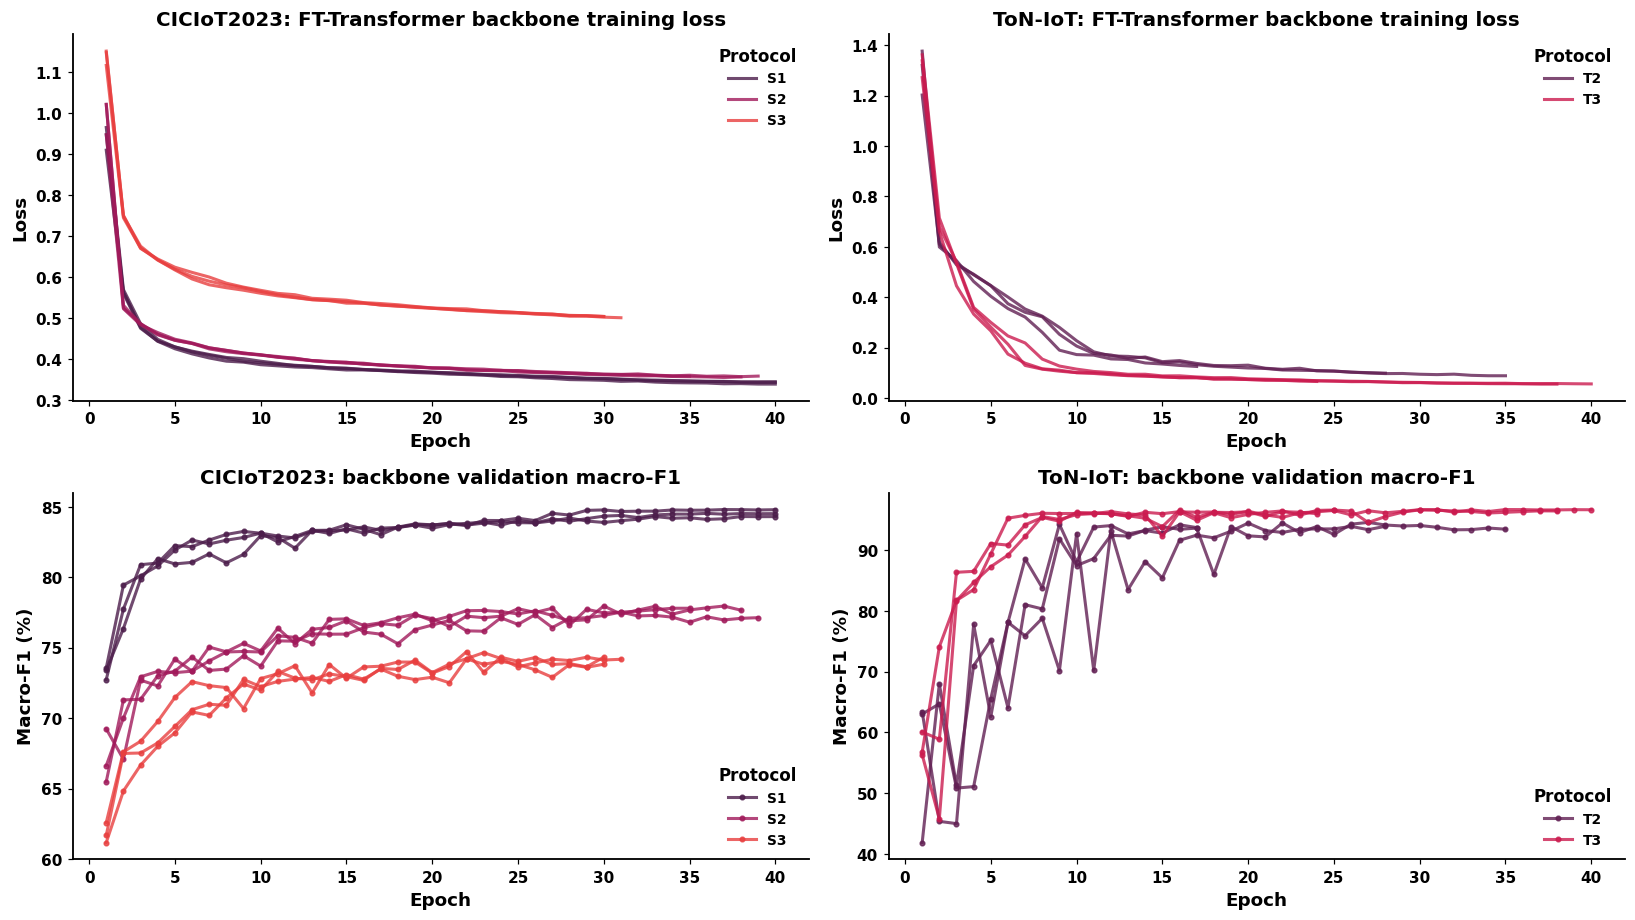

In [17]:
BASELINES = ['CNN-BiLSTM', 'FT-Transformer', 'RPL', 'CAC', 'GraphSAGE', 'GAT']
for ds in CFG['datasets']:
    for sp in VALID_SPLITS[ds]:
        for seed in CFG['seeds']:
            for m in BASELINES:
                run_one(ds, sp, seed, m)
R = load_runs()
print(R[R['label'].isin(MAIN_METHODS[:-1])].groupby(['dataset', 'label'])[['AUROC', 'Open-MacroF1', 'Closed-Acc']].mean().round(2))

fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))
for j, ds in enumerate(CFG['datasets']):
    for i, sp in enumerate(VALID_SPLITS[ds]):
        c = sns.color_palette('rocket', len(VALID_SPLITS[ds]) + 1)[i]
        for seed in CFG['seeds']:
            r = jload(os.path.join(D['runs'], f'{CFG["tag"]}_{ds}_{sp}_FT-Transformer_full_k{CFG["k"]}_s{seed}.json'))
            h = pd.DataFrame(r['hist'])
            axes[0, j].plot(h['epoch'] + 1, h['train_loss'], color=c, lw=2, alpha=0.8, label=sp if seed == CFG['seeds'][0] else None)
            axes[1, j].plot(h['epoch'] + 1, h['val_f1'] * 100, color=c, lw=2, alpha=0.8, marker='o', ms=3, label=sp if seed == CFG['seeds'][0] else None)
    axes[0, j].set_title(f'{ds}: FT-Transformer backbone training loss'); axes[0, j].set_ylabel('Loss'); axes[0, j].legend(title='Protocol')
    axes[1, j].set_title(f'{ds}: backbone validation macro-F1'); axes[1, j].set_ylabel('Macro-F1 (%)'); axes[1, j].legend(title='Protocol')
    for a in axes[:, j]: a.set_xlabel('Epoch'); bold_ticks(a)
plt.tight_layout(); savefig(fig, 'F12_backbone_training')

## Stage 9 · TokenGauss-Former: training and relative token-Mahalanobis scoring with conformal thresholds

                                    AUROC  Open-MacroF1  Closed-Acc
dataset      label                                                 
CIC-DIAD2024 CAC                    64.84         52.06       62.47
             CNN-BiLSTM-Energy      64.21         47.05       59.45
             CNN-BiLSTM-OpenMax     65.19         46.45       59.45
             FT-Transformer-Energy  65.02         49.67       63.64
             GAT-Energy             63.38         45.25       53.58
             GraphSAGE-Energy       63.94         46.88       56.48
             RPL                    64.13         49.71       60.14
CICIoT2023   CAC                    61.62         63.23       83.77
             CNN-BiLSTM-Energy      77.31         65.05       82.45
             CNN-BiLSTM-OpenMax     75.99         63.02       82.45
             FT-Transformer-Energy  78.42         66.37       83.53
             GAT-Energy             62.25         60.71       80.56
             GraphSAGE-Energy       67.02       

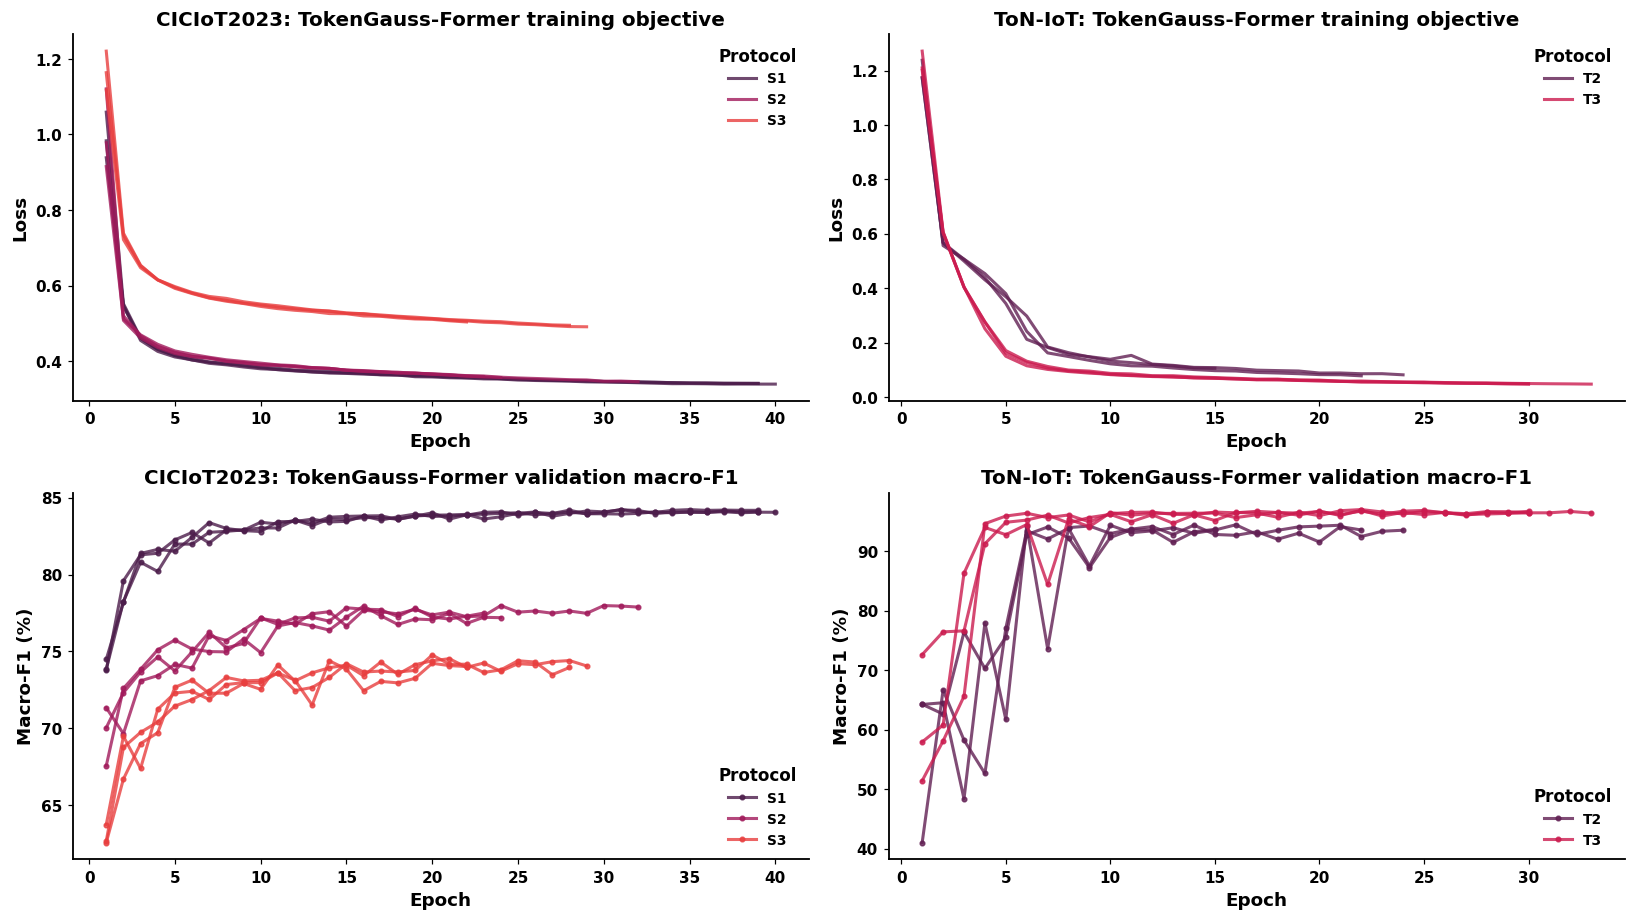

In [18]:
def rid(ds, sp, method, seed, variant='full', k=None): return f'{CFG["tag"]}_{ds}_{sp}_{method}_{variant}_k{CFG["k"] if k is None else k}_s{seed}'

TM = dict(gamma=0.1, q=0.25, w_tok=0.5, backbone='FT-Transformer')

def load_backbone(ds, sp, seed, method='TGF', variant=None):
    if variant is None: variant = PROP_VAR if method == 'TGF' else 'full'
    B = get_bundle(ds, sp); model = build_model(method, B['nF'], B['C'], variant)
    model.load_state_dict(torch.load(os.path.join(D['ckpt'], rid(ds, sp, method, seed, variant) + '_best.pt'), map_location=DEVICE))
    return B, model.eval()

def token_names(ds, with_groups=True):
    return list(FEATS[ds]) + ([f'<{g}>' for g in feature_groups(FEATS[ds])] if with_groups else [])

VAR_LABEL = {'noGroupP': 'w/o group tokens', 'full': REG_LAB, 'lam0.01': 'lambda=0.01', 'lam0.2': 'lambda=0.2'}

@torch.no_grad()
def token_states(enc, x):
    h = enc.tok(x); hs = [h[:, 1:]]
    for layer in enc.tf.layers:
        h = layer(h); hs.append(h[:, 1:])
    return torch.stack(hs, 1).float(), enc.norm(h[:, 0]).float()

def _shrink(S, g):
    d = S.shape[-1]; tr = torch.diagonal(S, dim1=-2, dim2=-1).sum(-1) / d
    return (1 - g) * S + g * tr[..., None, None] * torch.eye(d, dtype=S.dtype, device=S.device)

@torch.no_grad()
def tm_fit(enc, X, y, C, gamma, bs=1024):
    S1 = S2 = S1c = S2c = None; n = torch.zeros(C, dtype=torch.float64, device=DEVICE)
    for i in range(0, len(X), bs):
        H, Z = token_states(enc, X[i:i + bs]); yy = y[i:i + bs]
        H, Z = H.double(), Z.double(); Lh, Fh, d = H.shape[1:]
        if S1 is None:
            S1 = torch.zeros(C, Lh, Fh, d, dtype=torch.float64, device=DEVICE); S2 = torch.zeros(Lh, Fh, d, d, dtype=torch.float64, device=DEVICE)
            S1c = torch.zeros(C, Z.shape[1], dtype=torch.float64, device=DEVICE); S2c = torch.zeros(Z.shape[1], Z.shape[1], dtype=torch.float64, device=DEVICE)
        S1.index_add_(0, yy, H); S1c.index_add_(0, yy, Z); n += torch.bincount(yy, minlength=C).double()
        S2 += torch.einsum('blfi,blfj->lfij', H, H); S2c += Z.T @ Z
    N = n.sum(); k = n.clamp(min=1)
    mu = S1 / k[:, None, None, None]; mu0 = S1.sum(0) / N
    Sw = (S2 - torch.einsum('c,clfi,clfj->lfij', n, mu, mu)) / N; St = S2 / N - torch.einsum('lfi,lfj->lfij', mu0, mu0)
    muc = S1c / k[:, None]; mu0c = S1c.sum(0) / N
    Swc = (S2c - torch.einsum('c,ci,cj->ij', n, muc, muc)) / N; Stc = S2c / N - torch.outer(mu0c, mu0c)
    inv = lambda S: torch.linalg.inv(_shrink(S, gamma).cpu()).float().to(DEVICE)
    return dict(mu=mu.float(), mu0=mu0.float(), P=inv(Sw), P0=inv(St), muc=muc.float(), mu0c=mu0c.float(), Pc=inv(Swc), P0c=inv(Stc), C=C)

def _md_tok(H, mu, P):
    d = H - mu[None]; return torch.einsum('blfi,lfij,blfj->blf', d, P, d)

@torch.no_grad()
def tm_raw(enc, X, st, bs=1024, relative=True):
    T, Cl, Tp, Cp = [], [], [], []
    for i in range(0, len(X), bs):
        H, Z = token_states(enc, X[i:i + bs])
        mt = torch.stack([_md_tok(H, st['mu'][c], st['P']) for c in range(st['C'])], 0).min(0).values
        dz = Z[:, None, :] - st['muc'][None]; mc = torch.einsum('bci,ij,bcj->bc', dz, st['Pc'], dz).min(1).values
        if relative:
            mt = mt - _md_tok(H, st['mu0'], st['P0']); d0 = Z - st['mu0c']; mc = mc - torch.einsum('bi,ij,bj->b', d0, st['P0c'], d0)
        T.append(mt.cpu()); Cl.append(mc.cpu())
    return torch.cat(T).numpy(), torch.cat(Cl).numpy()

def tm_aggregate(Tv, Cv, Tt, Ct, q=None, w_tok=None, layers=None, mode='topq'):
    q = TM['q'] if q is None else q; w_tok = TM['w_tok'] if w_tok is None else w_tok
    if layers is not None: Tv, Tt = Tv[:, layers], Tt[:, layers]
    med = np.median(Tv, 0); iqr = np.subtract(*np.percentile(Tv, [75, 25], 0))
    sc_ = np.maximum(iqr, 0.1 * Tv.std(0)) + 1e-3
    Av, At = np.clip((Tv - med) / sc_, -50, 50).mean(1), np.clip((Tt - med) / sc_, -50, 50).mean(1)
    def agg(A):
        if mode == 'mean': return A.mean(1)
        k = max(1, int(math.ceil(q * A.shape[1]))); return np.sort(A, 1)[:, -k:].mean(1)
    tv, tt = agg(Av), agg(At); cm, cs = Cv.mean(), Cv.std() + 1e-8; tm_, ts_ = tv.mean(), tv.std() + 1e-8
    fuse = lambda t, c: w_tok * (t - tm_) / ts_ + (1 - w_tok) * (c - cm) / cs
    return fuse(tv, Cv), fuse(tt, Ct), At

def tokenmaha_run(ds, sp, seed, backbone='TGF', variant=None):
    if variant is None: variant = PROP_VAR if backbone == 'TGF' else 'full'
    main = backbone == 'TGF' and variant == PROP_VAR
    tagm = PROP_TMS if main else f'TMS-{backbone}' + ('' if variant == 'full' else f'-{variant}')
    run_id = f"{CFG['tag']}_{ds}_{sp}_{tagm}_full_k{CFG['k']}_s{seed}"; rp = os.path.join(D['runs'], run_id + '.json')
    if os.path.exists(rp): return jload(rp)
    print('>>', run_id); t0 = time.time()
    B, model = load_backbone(ds, sp, seed, backbone, variant); enc = model.enc; C = B['C']
    sub = strat_idx(B['y'][B['idx']['tr']], 40000); itr = B['idx']['tr'][sub]
    Xtr = B['X'][torch.tensor(itr, device=DEVICE)]; ytr = torch.tensor(B['y'][itr], device=DEVICE)
    st = tm_fit(enc, Xtr, ytr, C, TM['gamma'])
    Xv = B['X'][torch.tensor(B['idx']['va'], device=DEVICE)]; Xt = B['X'][torch.tensor(B['idx']['te'], device=DEVICE)]
    Tv, Cv = tm_raw(enc, Xv, st); Tt, Ct = tm_raw(enc, Xt, st)
    Tvp, Cvp = tm_raw(enc, Xv, st, relative=False); Ttp, Ctp = tm_raw(enc, Xt, st, relative=False)
    ov, ot = infer(model, B, None, 'va'), infer(model, B, None, 'te'); pv, pt = ov['logits'].argmax(1), ot['logits'].argmax(1)
    y = B['y'][B['idx']['te']]; Lh = Tv.shape[1]
    variants = {}
    lab0 = PROPOSED if main else (VAR_LABEL[variant] if backbone == 'TGF' else f'TokenMaha ({backbone} encoder)')
    sv, s_t, expl = tm_aggregate(Tv, Cv, Tt, Ct); variants[lab0] = (sv, s_t)
    if main:
        variants['global threshold (no conformal)'] = (sv, s_t)
        variants['CLS only (relative)'] = (Cv, Ct)
        variants['CLS only (plain Mahalanobis)'] = (Cvp, Ctp)
        a, b, _ = tm_aggregate(Tv, Cv, Tt, Ct, w_tok=1.0); variants['tokens only'] = (a, b)
        a, b, _ = tm_aggregate(Tvp, Cvp, Ttp, Ctp); variants['w/o relative correction'] = (a, b)
        a, b, _ = tm_aggregate(Tv, Cv, Tt, Ct, layers=[Lh - 1]); variants['last layer tokens only'] = (a, b)
        a, b, _ = tm_aggregate(Tv, Cv, Tt, Ct, mode='mean'); variants['mean over all tokens'] = (a, b)
        nF = B['nF']
        if Tv.shape[2] > nF:
            a, b, _ = tm_aggregate(Tv[:, :, :nF], Cv, Tt[:, :, :nF], Ct); variants['feature tokens only (no group tokens at scoring)'] = (a, b)
    metrics, arrs = {}, {'y': y.astype(np.int16), 't': B['t'][B['idx']['te']]}
    for lab, (sv_, st_) in variants.items():
        thr = conf_q(sv_, 1 - CFG['tpr']) * np.ones(len(st_)) if lab == 'global threshold (no conformal)' else conformal_thresholds(sv_, pv, C, CFG['alpha'])[pt]
        m, po = open_metrics(y, pt, st_, thr, C); metrics[lab] = m; k_ = akey(lab)
        arrs[f'{k_}__score'] = st_.astype(np.float32); arrs[f'{k_}__pred'] = pt.astype(np.int16); arrs[f'{k_}__open'] = po.astype(np.int16)
        arrs[f'{k_}__val'] = sv_.astype(np.float32); arrs[f'{k_}__thr'] = np.asarray(thr, dtype=np.float32)
    if main or backbone == 'FT-Transformer':
        arrs['expl'] = expl.astype(np.float16); arrs['z'] = ot['z'].astype(np.float16)
        arrs['mix_mu'] = st['muc'].cpu().numpy(); arrs['mix_cls'] = np.arange(C)
    np.savez_compressed(os.path.join(D['runs'], run_id + '.npz'), **arrs)
    out = dict(run_id=run_id, dataset=ds, split=sp, seed=seed, method=tagm, variant='full', k=CFG['k'], known=B['known'],
               unknown=B['unknown'], params=n_params(model), train_sec=time.time() - t0, hist=[], metrics=metrics)
    jdump(out, rp)
    for n_, m in metrics.items(): print(f'   {n_:34s} AUROC {m.get("AUROC", float("nan")):6.2f} | Open-F1 {m["Open-MacroF1"]:6.2f} | Known-FRR {m["Known-FRR"]:5.2f}')
    del model; gc.collect(); torch.cuda.empty_cache() if torch.cuda.is_available() else None
    return out

for ds in CFG['datasets']:
    for sp in VALID_SPLITS[ds]:
        for seed in CFG['seeds']:
            run_one(ds, sp, seed, 'TGF', variant=PROP_VAR)
            tokenmaha_run(ds, sp, seed, 'TGF', PROP_VAR)
            tokenmaha_run(ds, sp, seed, 'FT-Transformer')
R = load_runs()
print(R[R['label'].isin(MAIN_METHODS)].groupby(['dataset', 'label'])[['AUROC', 'Open-MacroF1', 'Closed-Acc']].mean().round(2))

fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))
for j, ds in enumerate(CFG['datasets']):
    for i, sp in enumerate(VALID_SPLITS[ds]):
        c = sns.color_palette('rocket', len(VALID_SPLITS[ds]) + 1)[i]
        for seed in CFG['seeds']:
            h = pd.DataFrame(jload(os.path.join(D['runs'], f'{CFG["tag"]}_{ds}_{sp}_TGF_{PROP_VAR}_k{CFG["k"]}_s{seed}.json'))['hist'])
            axes[0, j].plot(h['epoch'] + 1, h['train_loss'], color=c, lw=2, alpha=0.8, label=sp if seed == CFG['seeds'][0] else None)
            axes[1, j].plot(h['epoch'] + 1, h['val_f1'] * 100, color=c, lw=2, alpha=0.8, marker='o', ms=3, label=sp if seed == CFG['seeds'][0] else None)
    axes[0, j].set_title(f'{ds}: TokenGauss-Former training objective'); axes[0, j].set_ylabel('Loss'); axes[0, j].legend(title='Protocol')
    axes[1, j].set_title(f'{ds}: TokenGauss-Former validation macro-F1'); axes[1, j].set_ylabel('Macro-F1 (%)'); axes[1, j].legend(title='Protocol')
    for a_ in axes[:, j]: a_.set_xlabel('Epoch'); bold_ticks(a_)
plt.tight_layout(); savefig(fig, 'F12b_tgf_training')

## Stage 9b · Unified post-hoc protocol: Mixture-Mahalanobis + conformal thresholds on every backbone


===== CICIoT2023: identical post-hoc scoring and thresholding =====
                               Closed-Acc          AUROC       AUPR-Out         FPR95  Open-MacroF1 Unknown-Recall    Known-FRR
label                                                                                                                          
CNN-BiLSTM + MixMaha-CP      82.45 ± 2.84   83.26 ± 9.21  51.93 ± 32.59  47.34 ± 7.48  65.58 ± 6.65  36.70 ± 33.03  5.09 ± 0.13
FT-Transformer + MixMaha-CP  83.53 ± 2.91   87.04 ± 6.66  57.06 ± 31.87  38.92 ± 6.65  67.26 ± 6.84  39.69 ± 32.14  5.12 ± 0.14
RPL + MixMaha-CP             83.52 ± 2.88   87.51 ± 4.78  52.11 ± 28.72  35.08 ± 8.03  67.85 ± 6.74  40.49 ± 32.34  5.14 ± 0.09
CAC + MixMaha-CP             83.77 ± 2.69   82.07 ± 7.04  50.08 ± 29.50  51.68 ± 7.87  66.01 ± 6.85  30.71 ± 28.26  5.05 ± 0.15
GraphSAGE + MixMaha-CP       82.09 ± 3.01  80.04 ± 10.39  49.06 ± 29.78  56.58 ± 9.70  64.82 ± 6.39  34.59 ± 27.03  5.34 ± 0.13
GAT + MixMaha-CP             80.56 

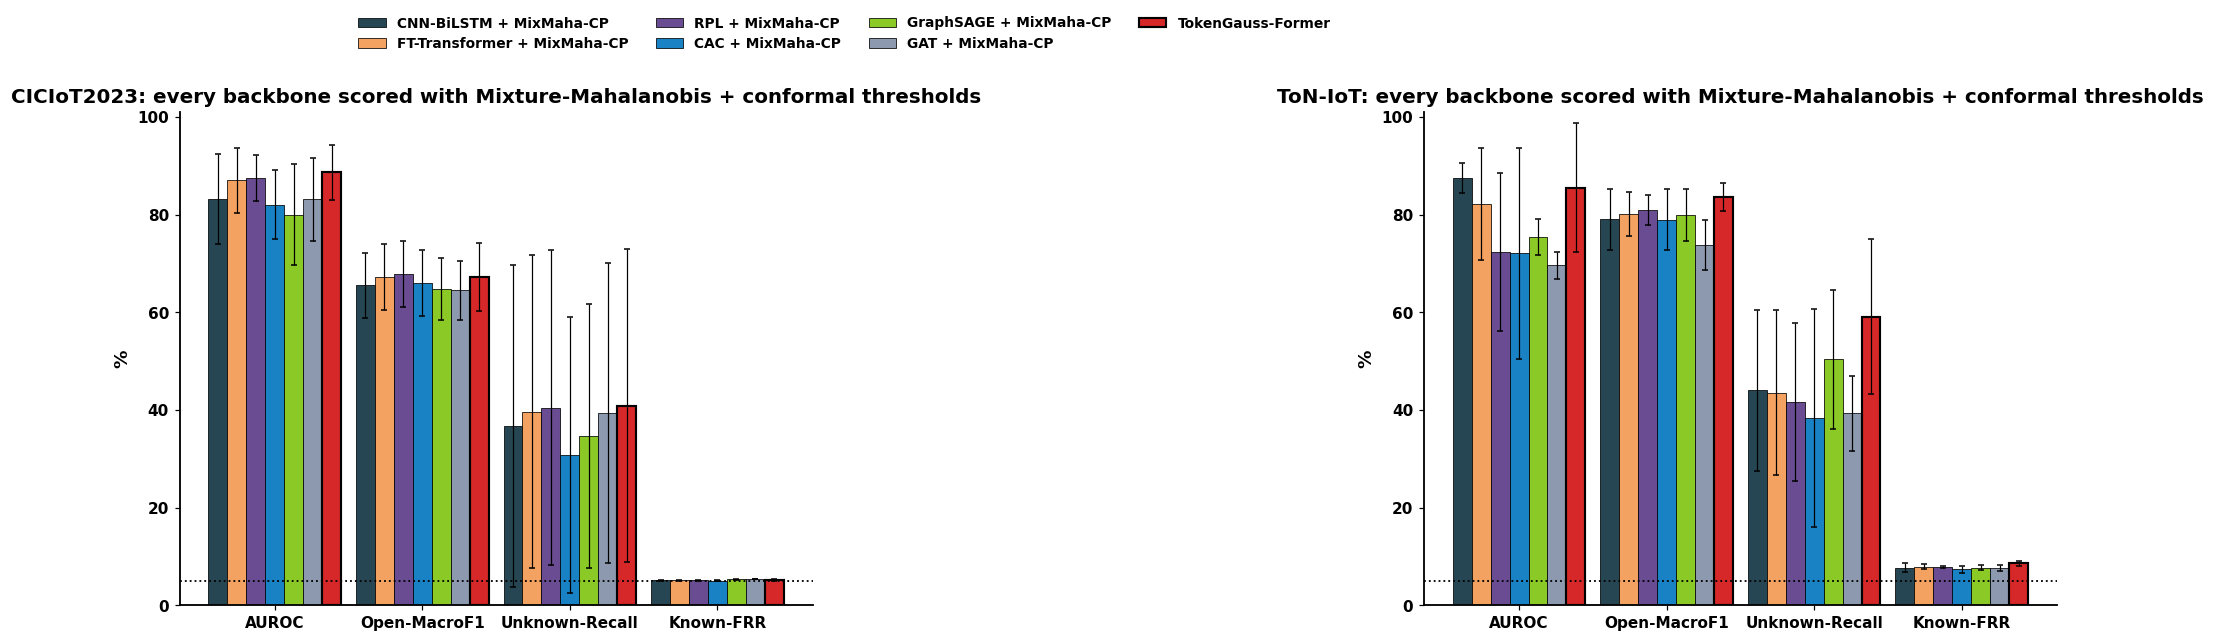

In [19]:
for ds in CFG['datasets']:
    for sp in VALID_SPLITS[ds]:
        for seed in CFG['seeds']:
            for m in BASELINES:
                posthoc_unified(ds, sp, seed, m)
UNI = [f'{m} + MixMaha-CP' for m in BASELINES] + [PROPOSED]
UCOL = {f'{m} + MixMaha-CP': MCOL[l] for m, l in zip(BASELINES, ['CNN-BiLSTM-Energy', 'FT-Transformer-Mahalanobis', 'RPL', 'CAC', 'GraphSAGE-Energy', 'GAT-Energy'])}
UCOL[PROPOSED] = MCOL[PROPOSED]
R = load_runs(); Ru = R[(R['k'] == CFG['k']) & R['dataset'].isin(CFG['datasets']) & R['label'].isin(UNI) & R['variant'].isin(['full', 'posthoc'])]
UM = ['Closed-Acc', 'AUROC', 'AUPR-Out', 'FPR95', 'Open-MacroF1', 'Unknown-Recall', 'Known-FRR']
for ds in CFG['datasets']:
    gm = Ru[Ru['dataset'] == ds].groupby('label')[UM].mean(); gs = Ru[Ru['dataset'] == ds].groupby('label')[UM].std(ddof=0).fillna(0)
    T = pd.DataFrame({m: gm[m].map('{:.2f}'.format) + ' ± ' + gs[m].map('{:.2f}'.format) for m in UM}).reindex(UNI)
    T.to_csv(os.path.join(D['tables'], f'T_unified_{ds}.csv')); print(f'\n===== {ds}: identical post-hoc scoring and thresholding ====='); print(T.to_string())
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
show = ['AUROC', 'Open-MacroF1', 'Unknown-Recall', 'Known-FRR']
for ax, ds in zip(axes, CFG['datasets']):
    g = Ru[Ru['dataset'] == ds].groupby('label')[show]; mu, sd = g.mean().reindex(UNI), g.std(ddof=0).reindex(UNI)
    w = 0.9 / len(UNI); x = np.arange(len(show))
    for i, m in enumerate(UNI):
        ax.bar(x + (i - len(UNI) / 2 + 0.5) * w, mu.loc[m], w, yerr=sd.loc[m], color=UCOL[m], edgecolor='black',
               lw=1.4 if m == PROPOSED else 0.5, label=m, capsize=2, error_kw={'lw': 0.8})
    ax.axhline(CFG['alpha'] * 100, color='black', ls=':', lw=1.2)
    ax.set_xticks(x); ax.set_xticklabels(show); ax.set_ylabel('%'); ax.set_ylim(0, 101)
    ax.set_title(f'{ds}: every backbone scored with Mixture-Mahalanobis + conformal thresholds'); bold_ticks(ax)
axes[0].legend(ncol=4, loc='upper center', bbox_to_anchor=(1.05, 1.22), fontsize=9)
plt.tight_layout(); savefig(fig, 'F13b_unified_protocol')

## Stage 10 · Main comparison


===== CICIoT2023 (mean ± std over protocols × seeds) =====
                         Closed-Acc Closed-MacroF1          AUROC  \
label                                                               
CNN-BiLSTM-Energy      82.45 ± 3.01   77.80 ± 4.44  77.31 ± 13.72   
CNN-BiLSTM-OpenMax     82.45 ± 3.01   77.80 ± 4.44  75.99 ± 15.87   
FT-Transformer-Energy  83.53 ± 3.09   79.46 ± 4.33  78.42 ± 16.64   
RPL                    83.52 ± 3.05   79.50 ± 4.15  54.13 ± 14.27   
CAC                    83.77 ± 2.85   79.60 ± 3.93  61.62 ± 16.55   
GraphSAGE-Energy       82.09 ± 3.19   77.67 ± 4.09  67.02 ± 23.86   
GAT-Energy             80.56 ± 3.70   75.78 ± 4.25  62.25 ± 25.73   
TokenGauss-Former      83.40 ± 2.92   79.18 ± 4.16   88.67 ± 6.06   

                            AUPR-Out          FPR95  Open-MacroF1  \
label                                                               
CNN-BiLSTM-Energy      43.30 ± 29.59  56.51 ± 22.17  65.05 ± 5.26   
CNN-BiLSTM-OpenMax     39.04 ± 27.46  48.1

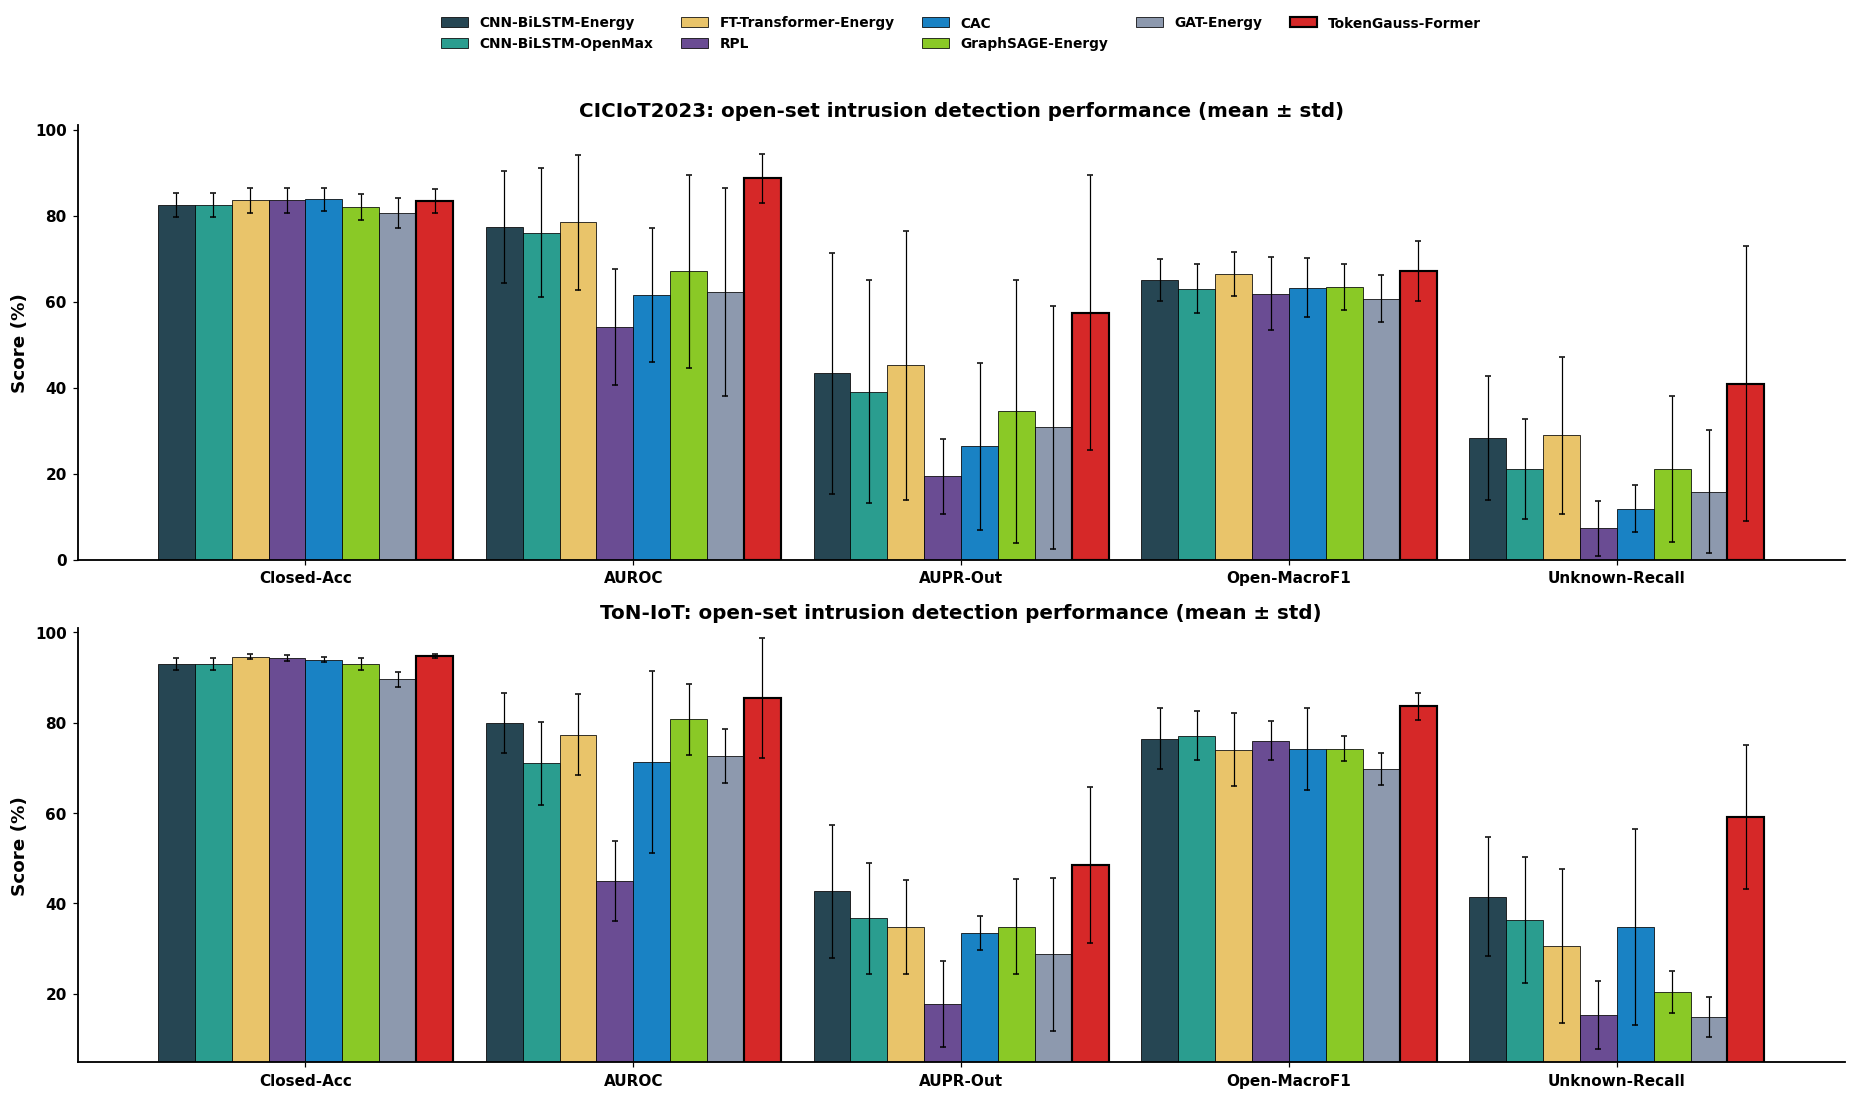

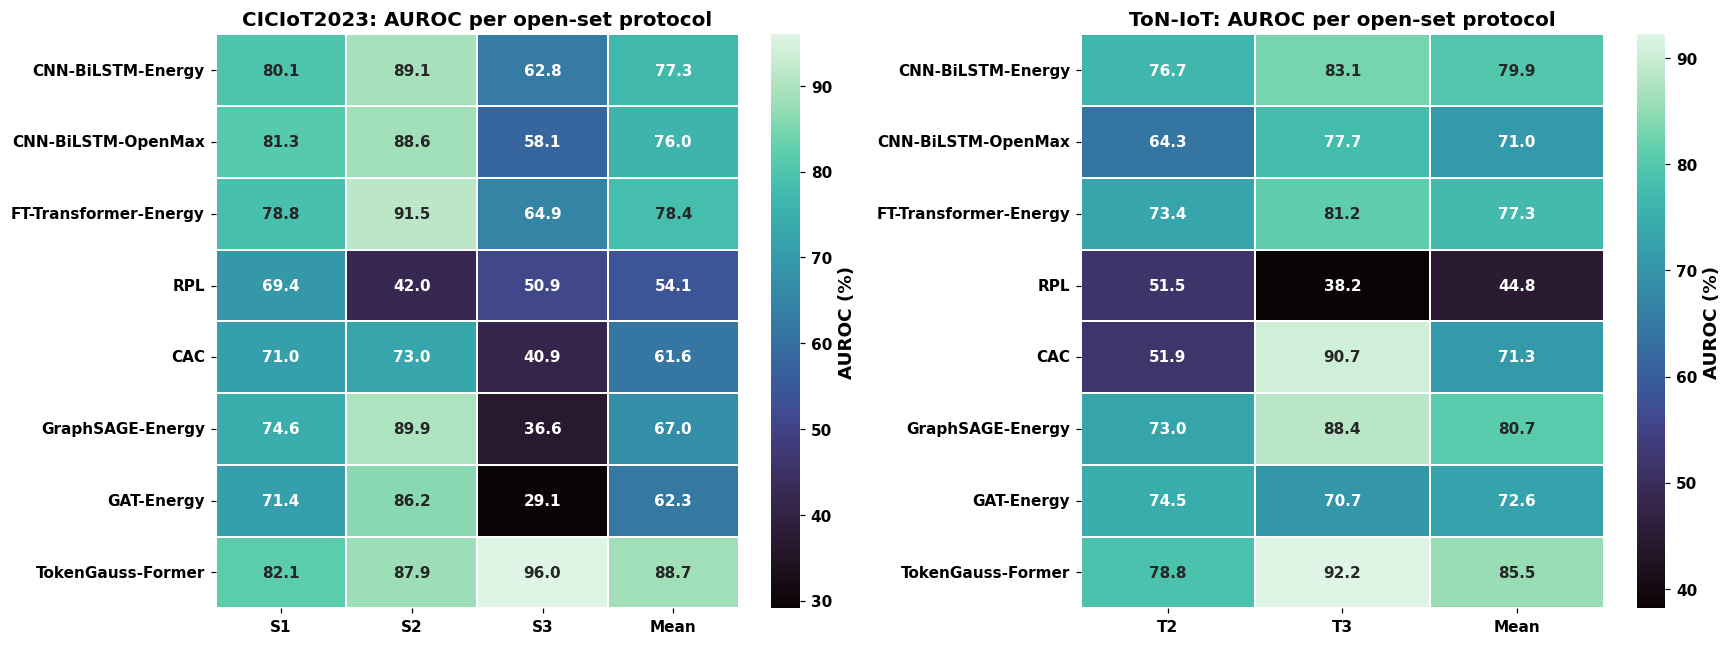

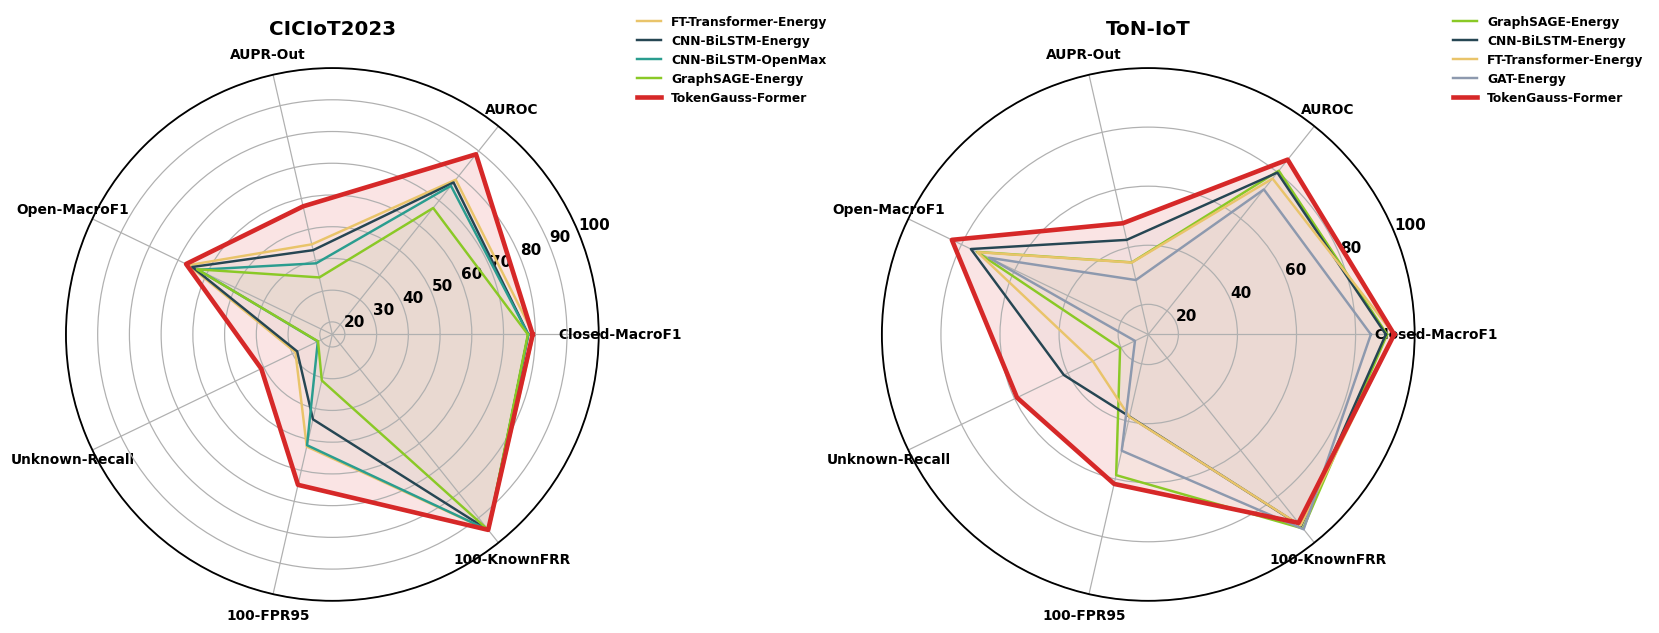

In [20]:
METRICS = ['Closed-Acc', 'Closed-MacroF1', 'AUROC', 'AUPR-Out', 'FPR95', 'Open-MacroF1', 'Open-Acc', 'Unknown-Recall', 'Known-FRR']
R = load_runs(); Rm = R[(R['variant'] == 'full') & (R['k'] == CFG['k']) & R['dataset'].isin(CFG['datasets']) & (R['label'].isin(MAIN_METHODS))]

def pm(g): return g.mean().map('{:.2f}'.format) + ' ± ' + g.std(ddof=0).map('{:.2f}'.format)
for ds in CFG['datasets']:
    T = Rm[Rm['dataset'] == ds].groupby('label')[METRICS].agg(['mean', 'std']).reindex(MAIN_METHODS)
    out = pd.DataFrame({m: T[m]['mean'].map('{:.2f}'.format) + ' ± ' + T[m]['std'].fillna(0).map('{:.2f}'.format) for m in METRICS})
    out.to_csv(os.path.join(D['tables'], f'T_main_{ds}.csv'))
    print(f'\n===== {ds} (mean ± std over protocols × seeds) ====='); display(out) if 'display' in globals() else print(out)
    Ts = Rm[Rm['dataset'] == ds].groupby(['split', 'label'])[['AUROC', 'Open-MacroF1', 'FPR95']].mean().round(2).unstack(0)
    Ts.to_csv(os.path.join(D['tables'], f'T_per_split_{ds}.csv'))

fig, axes = plt.subplots(2, 1, figsize=(17, 10))
show = ['Closed-Acc', 'AUROC', 'AUPR-Out', 'Open-MacroF1', 'Unknown-Recall']
for ax, ds in zip(axes, CFG['datasets']):
    g = Rm[Rm['dataset'] == ds].groupby('label')[show]; mu, sd = g.mean().reindex(MAIN_METHODS), g.std(ddof=0).reindex(MAIN_METHODS)
    w = 0.9 / len(MAIN_METHODS); x = np.arange(len(show))
    for i, m in enumerate(MAIN_METHODS):
        ax.bar(x + (i - len(MAIN_METHODS) / 2 + 0.5) * w, mu.loc[m], w, yerr=sd.loc[m], color=MCOL[m], edgecolor='black',
               lw=1.4 if m == PROPOSED else 0.5, label=m, capsize=2, error_kw={'lw': 0.8})
    ax.set_xticks(x); ax.set_xticklabels(show); ax.set_ylabel('Score (%)'); ax.set_ylim(max(0, np.nanmin(mu.values) - 10), 101)
    ax.set_title(f'{ds}: open-set intrusion detection performance (mean ± std)'); bold_ticks(ax)
axes[0].legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, 1.28))
plt.tight_layout(); savefig(fig, 'F13_main_comparison')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, ds in zip(axes, CFG['datasets']):
    H = Rm[Rm['dataset'] == ds].groupby(['label', 'split'])['AUROC'].mean().unstack().reindex(MAIN_METHODS)
    H['Mean'] = H.mean(1)
    sns.heatmap(H, annot=True, fmt='.1f', cmap='mako', ax=ax, linewidths=1, linecolor='white', cbar_kws={'label': 'AUROC (%)'},
                annot_kws={'weight': 'bold', 'size': 10})
    ax.set_title(f'{ds}: AUROC per open-set protocol'); ax.set_ylabel(''); ax.set_xlabel(''); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F14_auroc_heatmap')

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), subplot_kw=dict(polar=True))
rad = ['Closed-MacroF1', 'AUROC', 'AUPR-Out', 'Open-MacroF1', 'Unknown-Recall', '100-FPR95', '100-KnownFRR']
for ax, ds in zip(axes, CFG['datasets']):
    g = Rm[Rm['dataset'] == ds].groupby('label')[METRICS].mean()
    g['100-FPR95'] = 100 - g['FPR95']; g['100-KnownFRR'] = 100 - g['Known-FRR']
    top = [m for m in g['AUROC'].sort_values(ascending=False).index if m != PROPOSED][:4] + [PROPOSED]
    ang = np.linspace(0, 2 * np.pi, len(rad), endpoint=False).tolist(); ang += ang[:1]
    lo = max(0, g.loc[top, rad].values.min() - 5)
    for m in top:
        v = g.loc[m, rad].tolist(); v += v[:1]
        ax.plot(ang, v, color=MCOL[m], lw=3 if m == PROPOSED else 1.6, label=m); ax.fill(ang, v, color=MCOL[m], alpha=0.12 if m == PROPOSED else 0.03)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(rad, fontsize=9, fontweight='bold'); ax.set_ylim(lo, 100)
    ax.set_title(ds, pad=22); ax.legend(loc='upper right', bbox_to_anchor=(1.45, 1.12), fontsize=8)
plt.tight_layout(); savefig(fig, 'F15_radar')

## Stage 11 · Open-set behaviour analysis

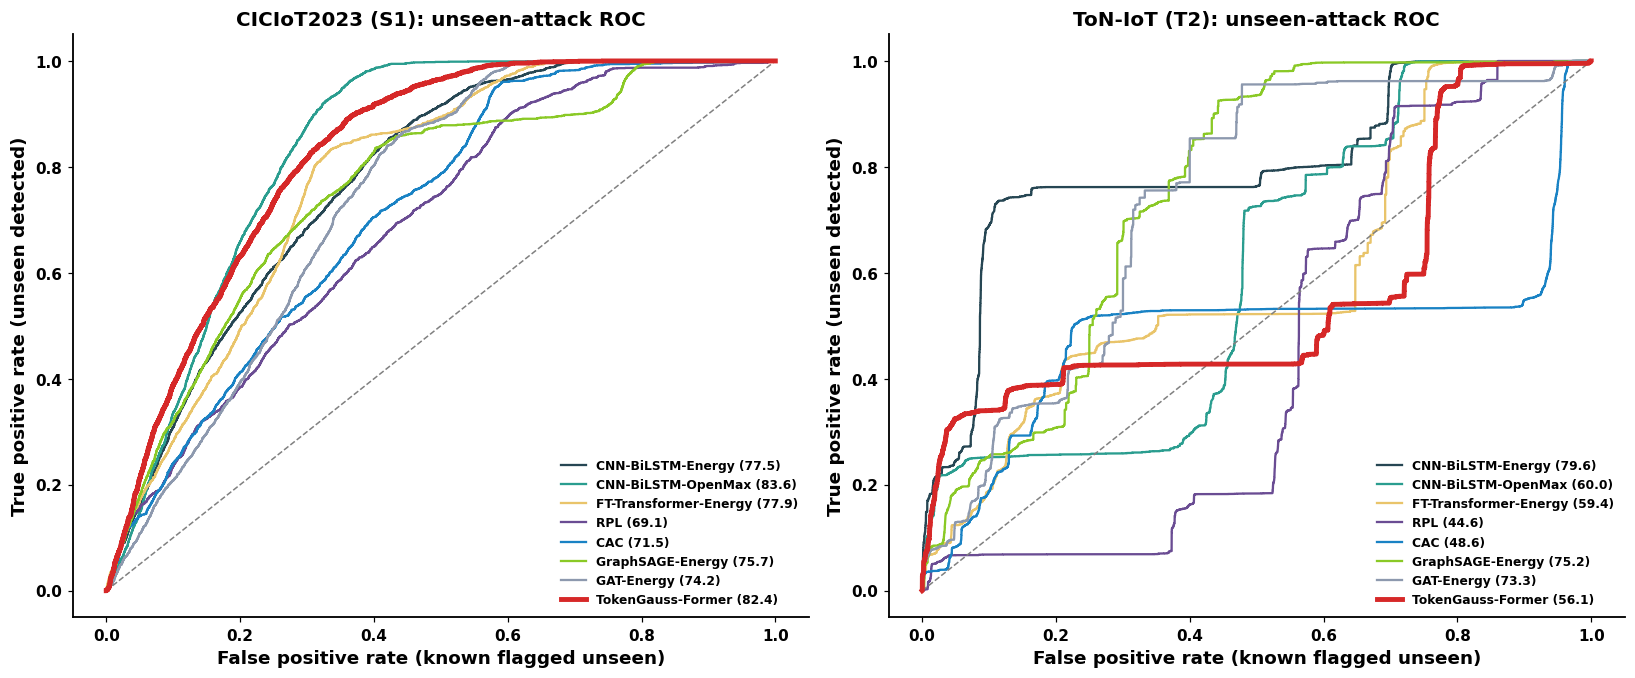

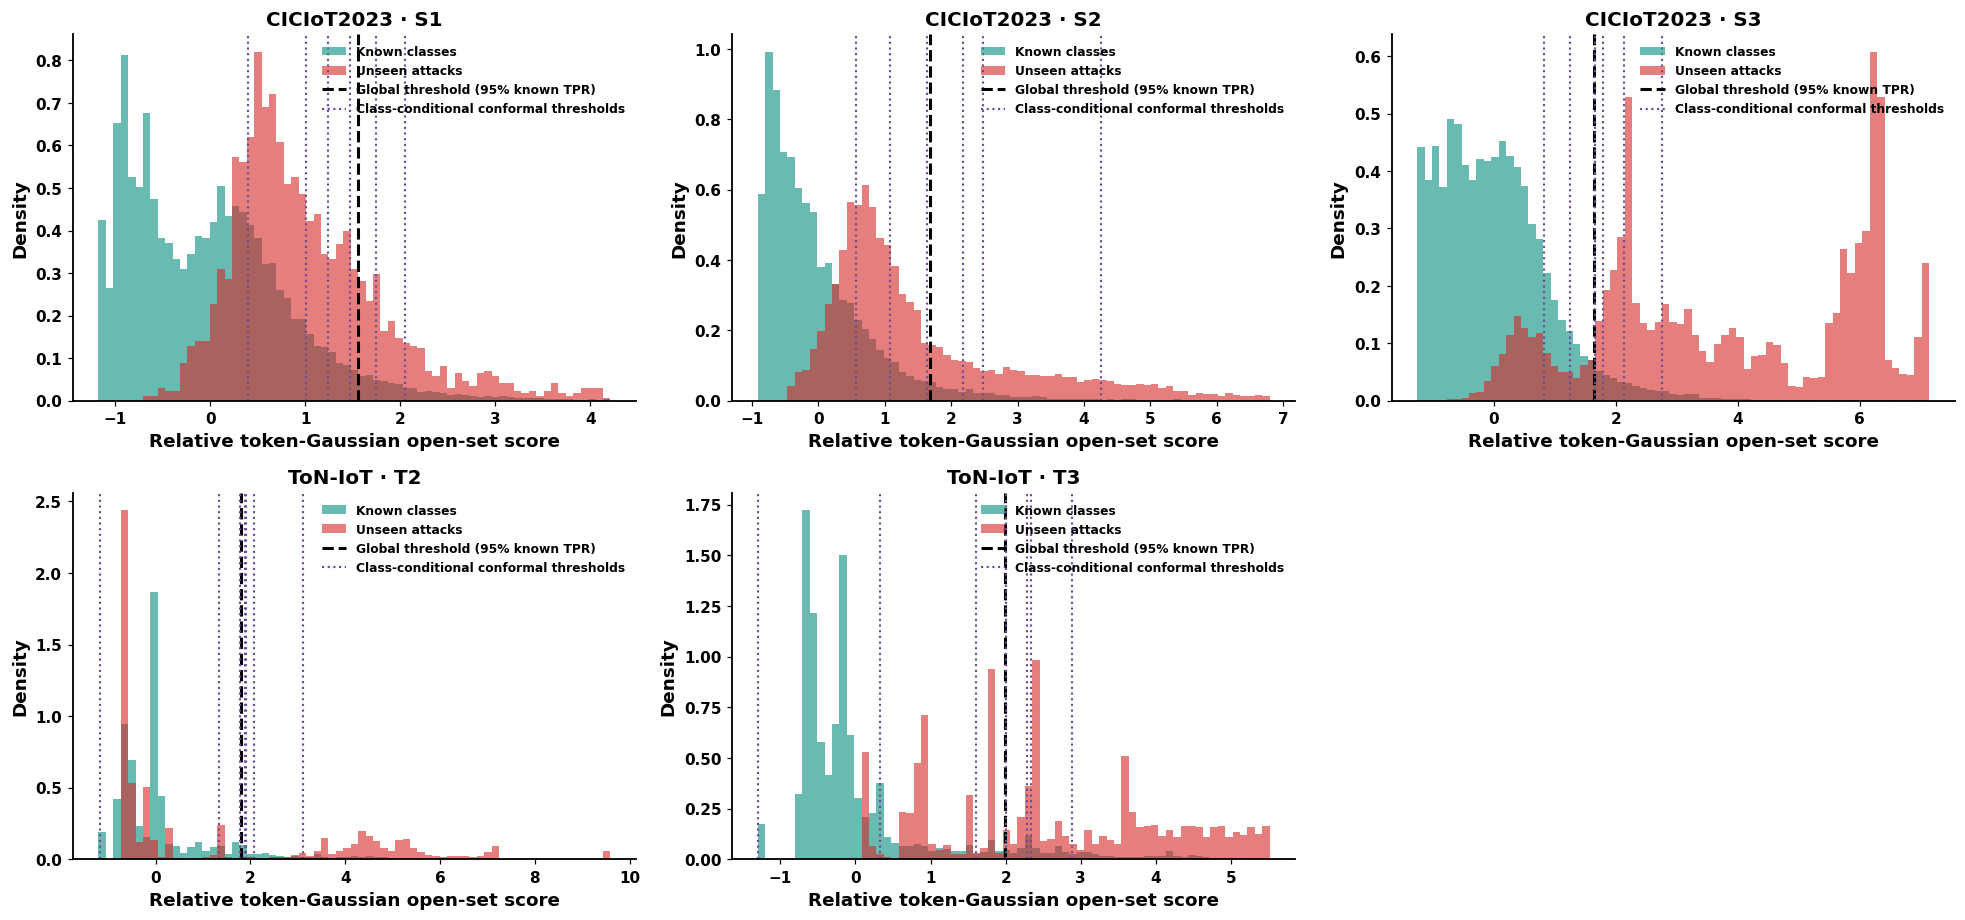

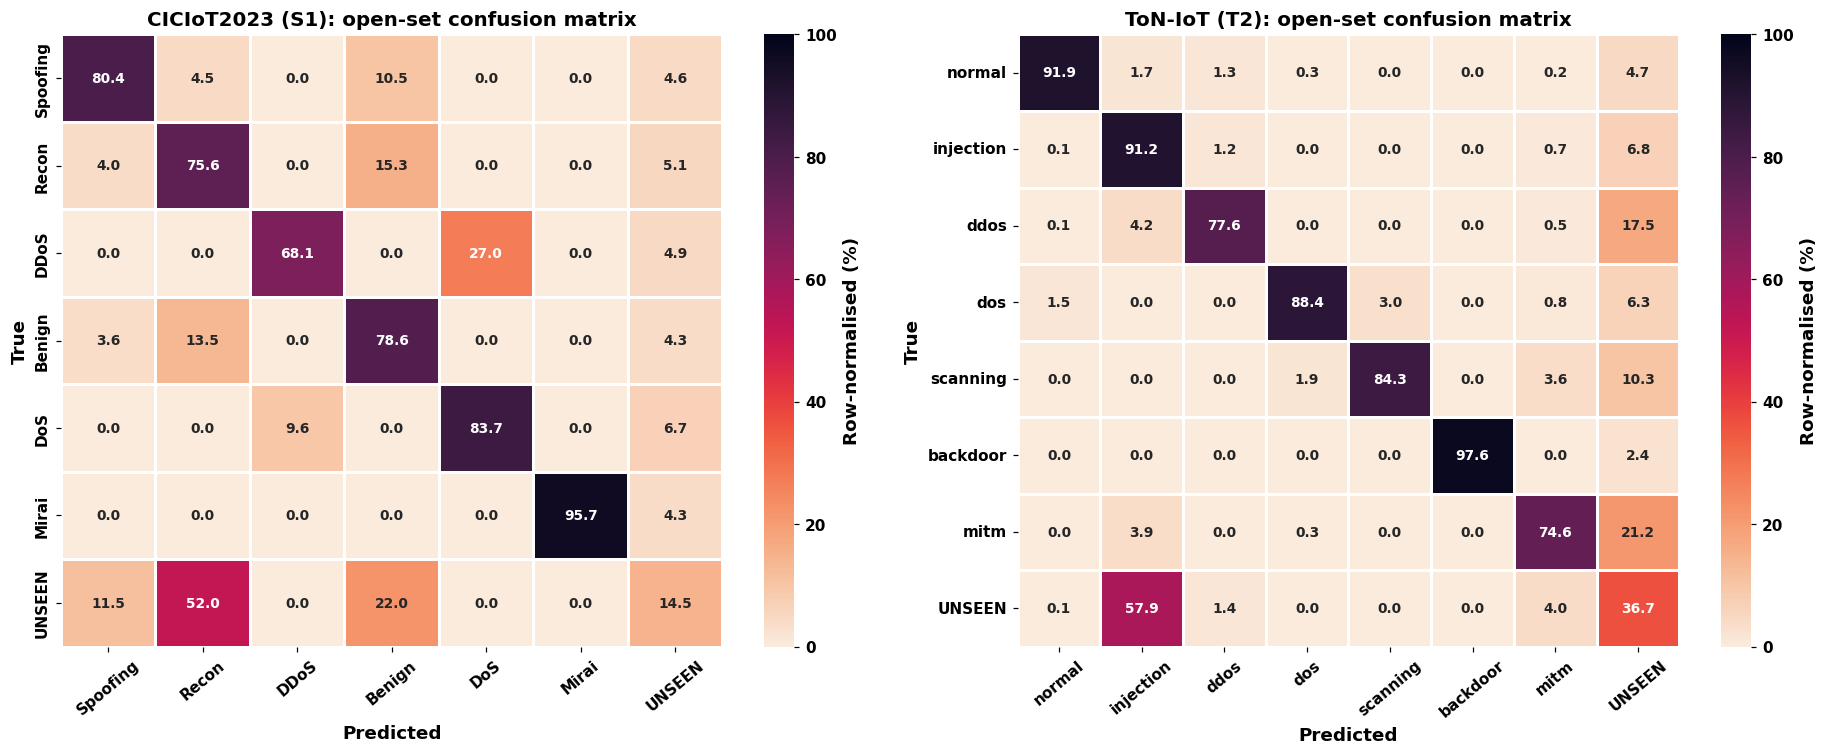

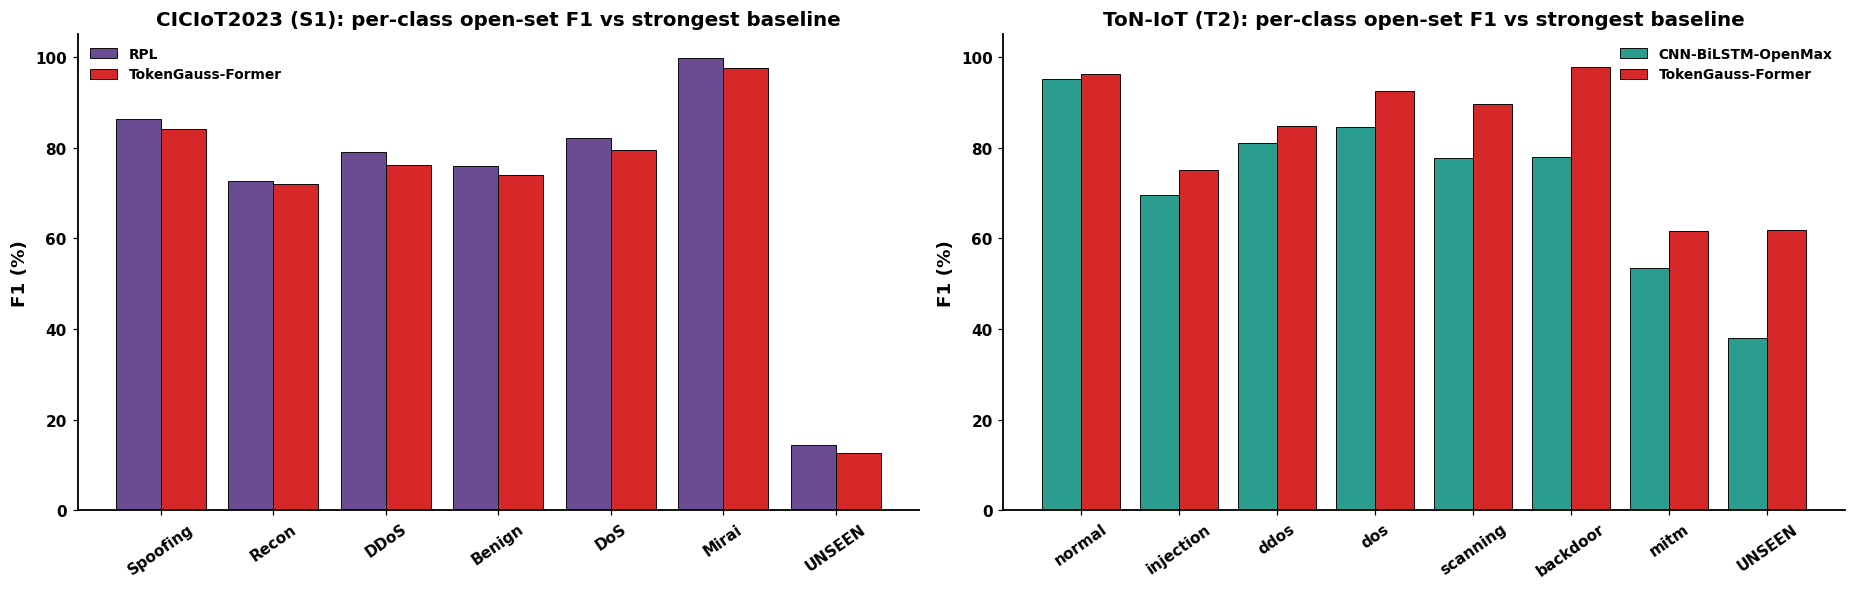

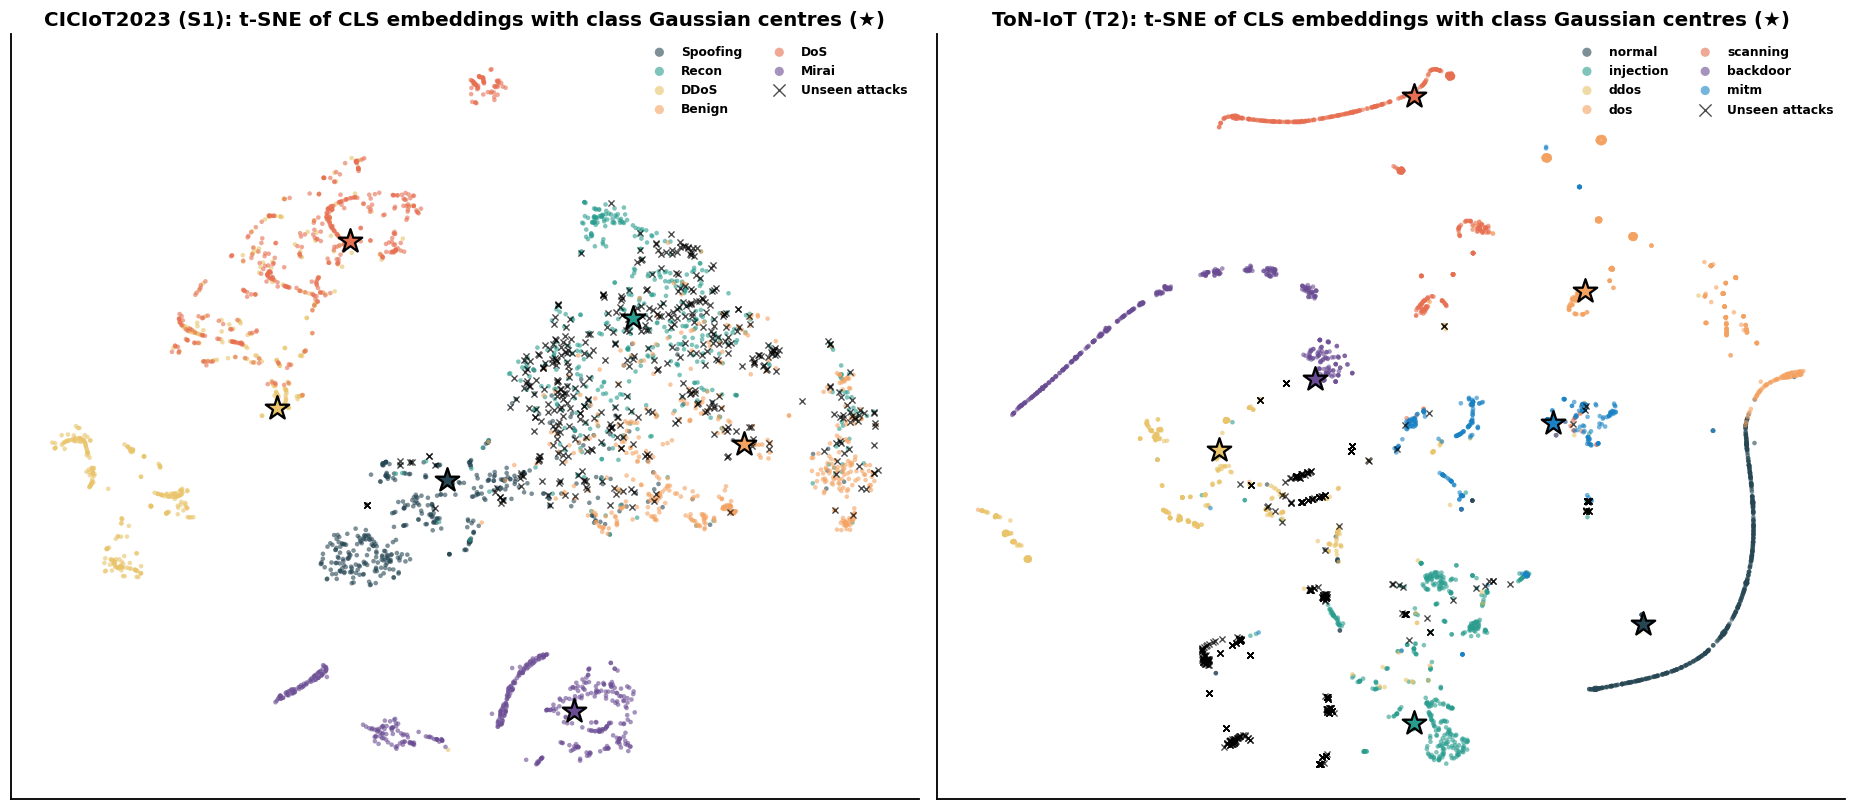

In [17]:
LAB2METHOD = {'CNN-BiLSTM-Energy': 'CNN-BiLSTM', 'CNN-BiLSTM-OpenMax': 'CNN-BiLSTM', 'FT-Transformer-Energy': 'FT-Transformer',
              'FT-Transformer-Mahalanobis': 'FT-Transformer', 'RPL': 'RPL', 'CAC': 'CAC', 'GraphSAGE-Energy': 'GraphSAGE',
              'GAT-Energy': 'GAT', TMFT: 'TMS-FT-Transformer', PROPOSED: PROP_TMS}
s0 = CFG['seeds'][0]

fig, axes = plt.subplots(1, 2, figsize=(15, 6.3))
for ax, ds in zip(axes, CFG['datasets']):
    sp = VALID_SPLITS[ds][0]
    for m in MAIN_METHODS:
        a = load_arr(rid(ds, sp, LAB2METHOD[m], s0)); y = a['y']; C = int(y.max())
        fpr, tpr_, _ = roc_curve(y == C, a[akey(m) + '__score']); au = roc_auc_score(y == C, a[akey(m) + '__score']) * 100
        ax.plot(fpr, tpr_, color=MCOL[m], lw=3.2 if m == PROPOSED else 1.5, label=f'{m} ({au:.1f})', zorder=5 if m == PROPOSED else 2)
    ax.plot([0, 1], [0, 1], ls='--', color='grey', lw=1)
    ax.set_xlabel('False positive rate (known flagged unseen)'); ax.set_ylabel('True positive rate (unseen detected)')
    ax.set_title(f'{ds} ({sp}): unseen-attack ROC'); ax.legend(loc='lower right', fontsize=8); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F16_roc_curves')

NCOL = max(len(VALID_SPLITS[d]) for d in CFG['datasets'])
fig, axes = plt.subplots(2, NCOL, figsize=(6 * NCOL, 8.5), squeeze=False)
for ax in axes.ravel(): ax.set_visible(False)
for i, ds in enumerate(CFG['datasets']):
    for j, sp in enumerate(VALID_SPLITS[ds][:axes.shape[1]]):
        a = load_arr(rid(ds, sp, PROP_TMS, s0)); y = a['y']; C = int(y.max()); sc = a[akey(PROPOSED) + '__score']
        thr = float(a[akey('global threshold (no conformal)') + '__thr'][0]); tau = np.unique(a[akey(PROPOSED) + '__thr'])
        ax = axes[i, j]; ax.set_visible(True); lo, hi = np.quantile(sc, [0.005, 0.995]); bins = np.linspace(lo, hi, 70)
        ax.hist(sc[y < C], bins=bins, density=True, color='#2a9d8f', alpha=0.7, label='Known classes')
        ax.hist(sc[y == C], bins=bins, density=True, color='#d62828', alpha=0.6, label='Unseen attacks')
        ax.axvline(thr, color='black', ls='--', lw=2, label='Global threshold (95% known TPR)')
        for i_, t_ in enumerate(tau): ax.axvline(t_, color='#6a4c93', ls=':', lw=1.4, label='Class-conditional conformal thresholds' if i_ == 0 else None)
        ax.set_title(f'{ds} · {sp}'); ax.set_xlabel('Relative token-Gaussian open-set score'); ax.set_ylabel('Density'); ax.legend(fontsize=8); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F17_score_distributions')

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, ds in zip(axes, CFG['datasets']):
    sp = VALID_SPLITS[ds][0]; B = get_bundle(ds, sp); a = load_arr(rid(ds, sp, PROP_TMS, s0)); C = B['C']
    cm = confusion_matrix(a['y'], a[akey(PROPOSED) + '__open'], labels=np.arange(C + 1)); cmn = cm / cm.sum(1, keepdims=True).clip(1)
    labs = B['known'] + ['UNSEEN']
    sns.heatmap(cmn * 100, annot=True, fmt='.1f', cmap='rocket_r', xticklabels=labs, yticklabels=labs, ax=ax, vmin=0, vmax=100,
                linewidths=0.8, linecolor='white', cbar_kws={'label': 'Row-normalised (%)'}, annot_kws={'size': 9, 'weight': 'bold'})
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(f'{ds} ({sp}): open-set confusion matrix'); ax.tick_params(axis='x', rotation=40); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F18_open_confusion')

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
for ax, ds in zip(axes, CFG['datasets']):
    sp = VALID_SPLITS[ds][0]; B = get_bundle(ds, sp); C = B['C']
    g = Rm[(Rm['dataset'] == ds) & (Rm['split'] == sp)].groupby('label')['Open-MacroF1'].mean().drop(PROPOSED)
    best = g.idxmax(); labs = B['known'] + ['UNSEEN']; x = np.arange(C + 1)
    for off, m, col in [(-0.2, best, MCOL[best]), (0.2, PROPOSED, MCOL[PROPOSED])]:
        f1s = np.mean([precision_recall_fscore_support(load_arr(rid(ds, sp, LAB2METHOD[m], s))['y'],
                      load_arr(rid(ds, sp, LAB2METHOD[m], s))[akey(m) + '__open'], labels=np.arange(C + 1), zero_division=0)[2]
                      for s in CFG['seeds']], 0) * 100
        ax.bar(x + off, f1s, 0.4, color=col, edgecolor='black', lw=0.6, label=m)
    ax.set_xticks(x); ax.set_xticklabels(labs, rotation=35); ax.set_ylabel('F1 (%)'); ax.set_ylim(0, 105)
    ax.set_title(f'{ds} ({sp}): per-class open-set F1 vs strongest baseline'); ax.legend(); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F19_per_class_f1')

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
for ax, ds in zip(axes, CFG['datasets']):
    sp = VALID_SPLITS[ds][0]; B = get_bundle(ds, sp); a = load_arr(rid(ds, sp, PROP_TMS, s0)); C = B['C']
    y = a['y']; z = a['z'].astype(np.float32); rng = np.random.default_rng(0)
    pick = np.concatenate([rng.choice(np.where(y == c)[0], min(450, (y == c).sum()), replace=False) for c in np.unique(y)])
    mu, mcls = a['mix_mu'], a['mix_cls']
    E = TSNE(2, init='pca', perplexity=35, random_state=0).fit_transform(np.vstack([z[pick], mu]))
    Ez, Ep = E[:len(pick)], E[len(pick):]; fc = fam_colors(B['known'])
    for c in range(C):
        m = y[pick] == c; ax.scatter(Ez[m, 0], Ez[m, 1], s=9, alpha=0.6, color=fc[B['known'][c]], label=B['known'][c], edgecolors='none')
    m = y[pick] == C; ax.scatter(Ez[m, 0], Ez[m, 1], s=16, marker='x', color='black', alpha=0.7, label='Unseen attacks', lw=0.9)
    for c in range(C):
        ax.scatter(Ep[mcls == c, 0], Ep[mcls == c, 1], s=260, marker='*', color=fc[B['known'][c]], edgecolors='black', linewidths=1.5, zorder=10)
    ax.set_title(f'{ds} ({sp}): t-SNE of CLS embeddings with class Gaussian centres (★)'); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(markerscale=2, fontsize=8, ncol=2, loc='best')
plt.tight_layout(); savefig(fig, 'F20_tsne_mixture')

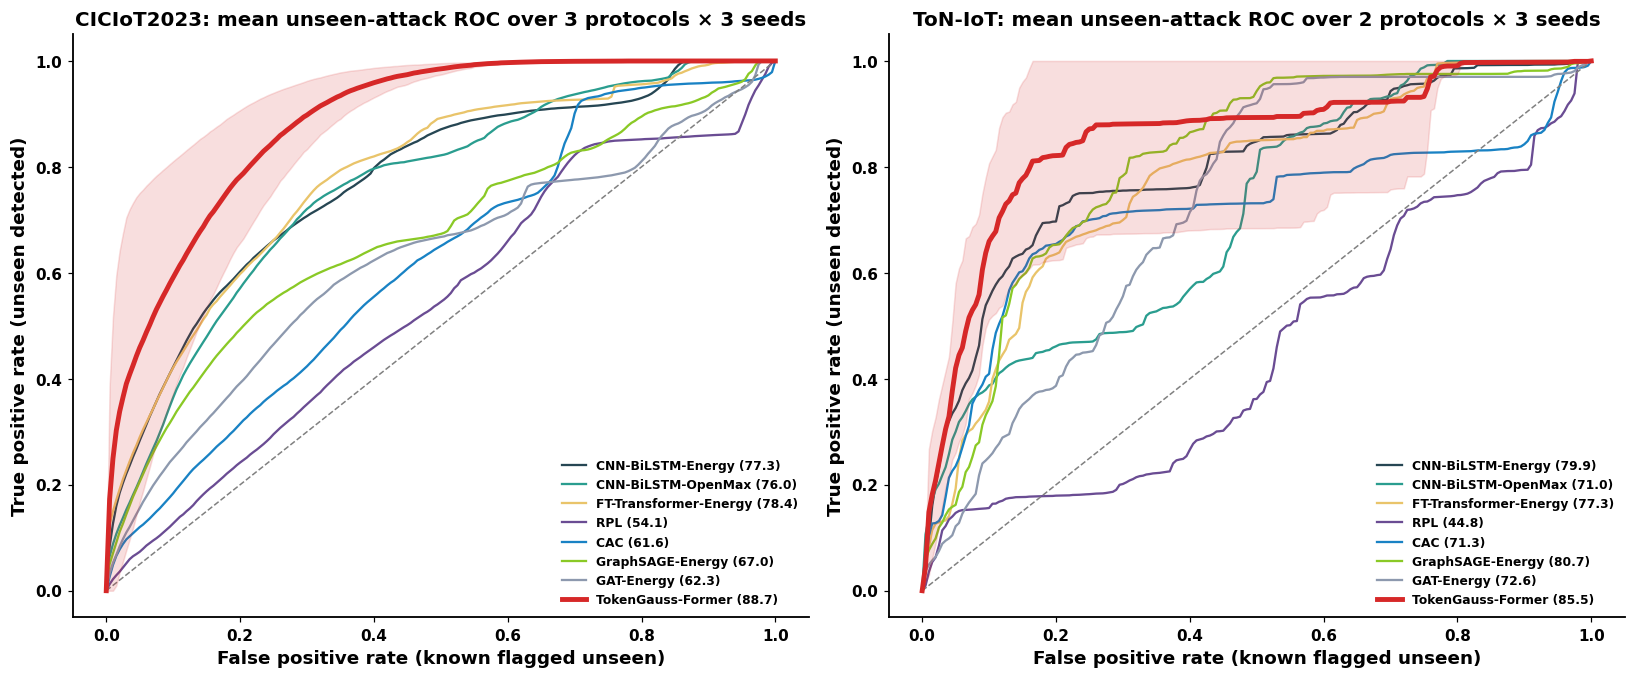

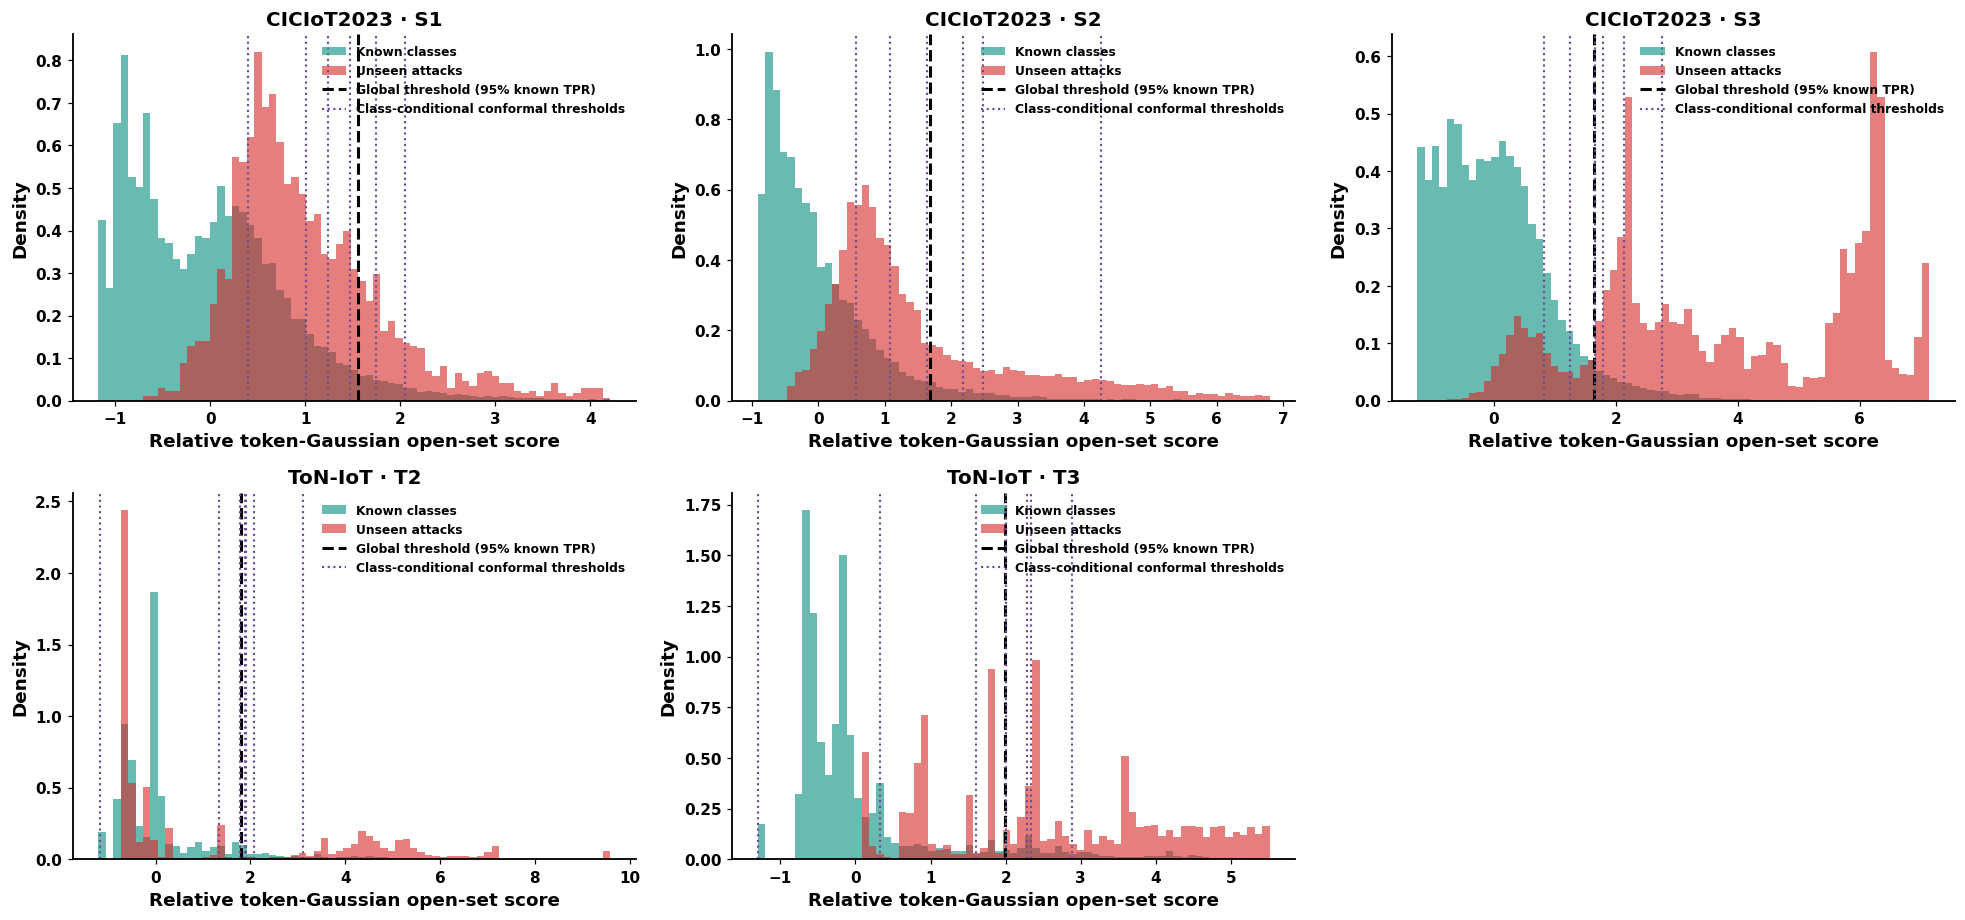

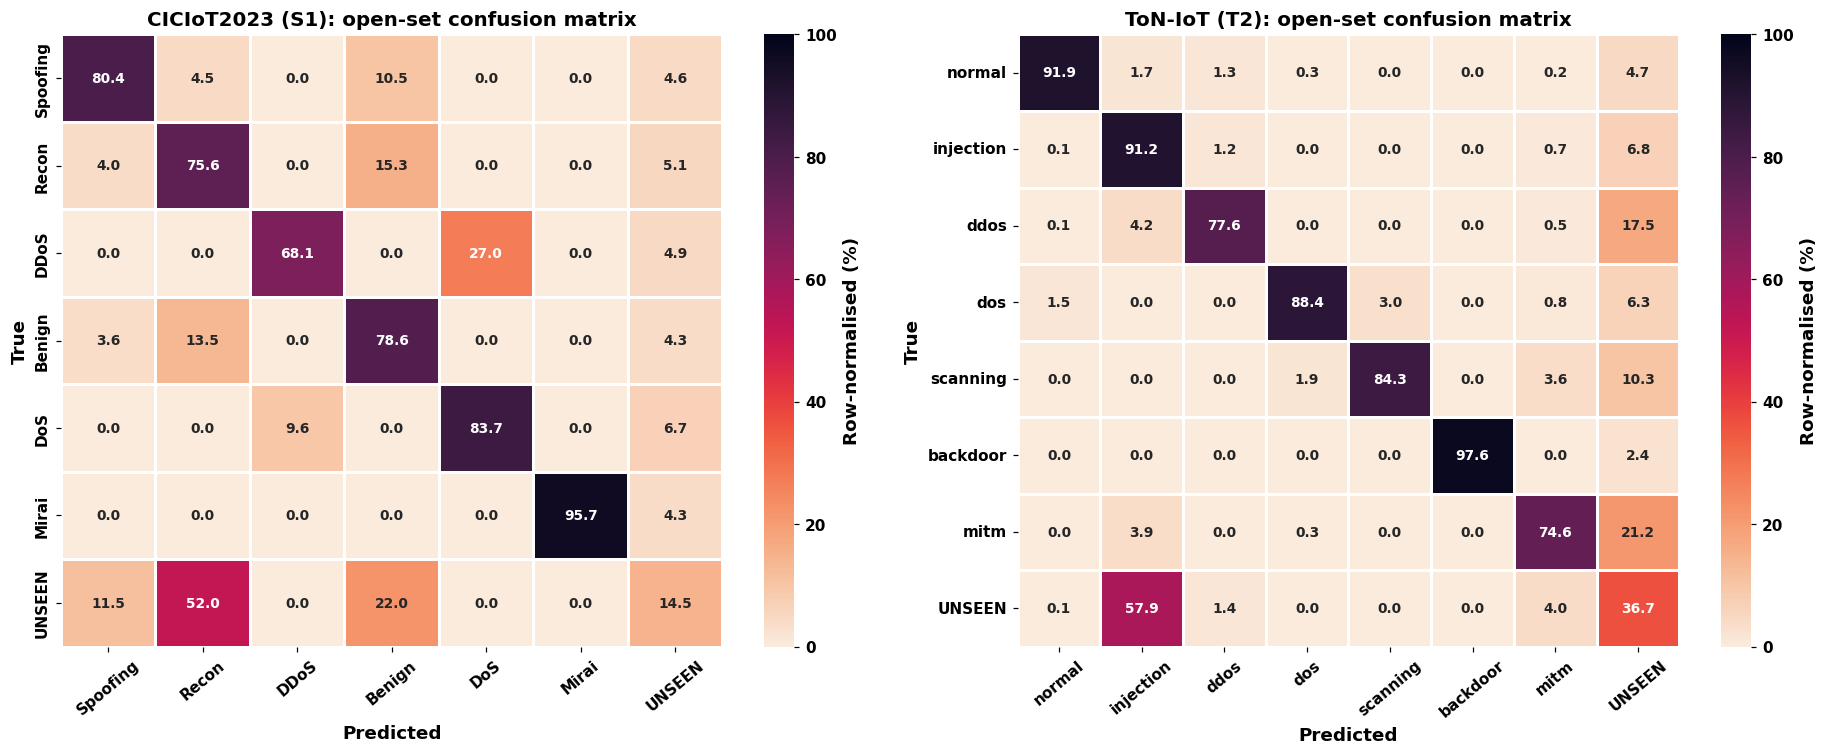

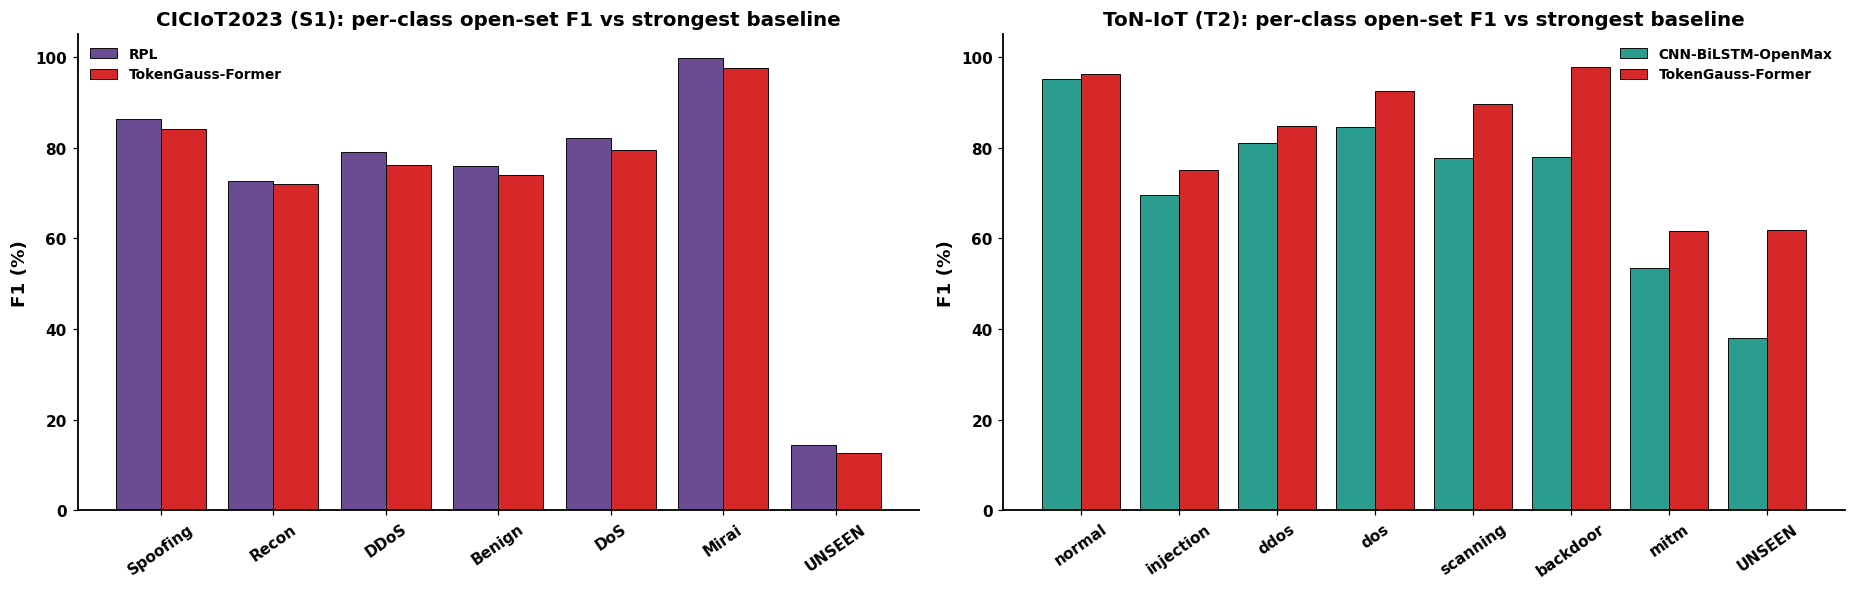

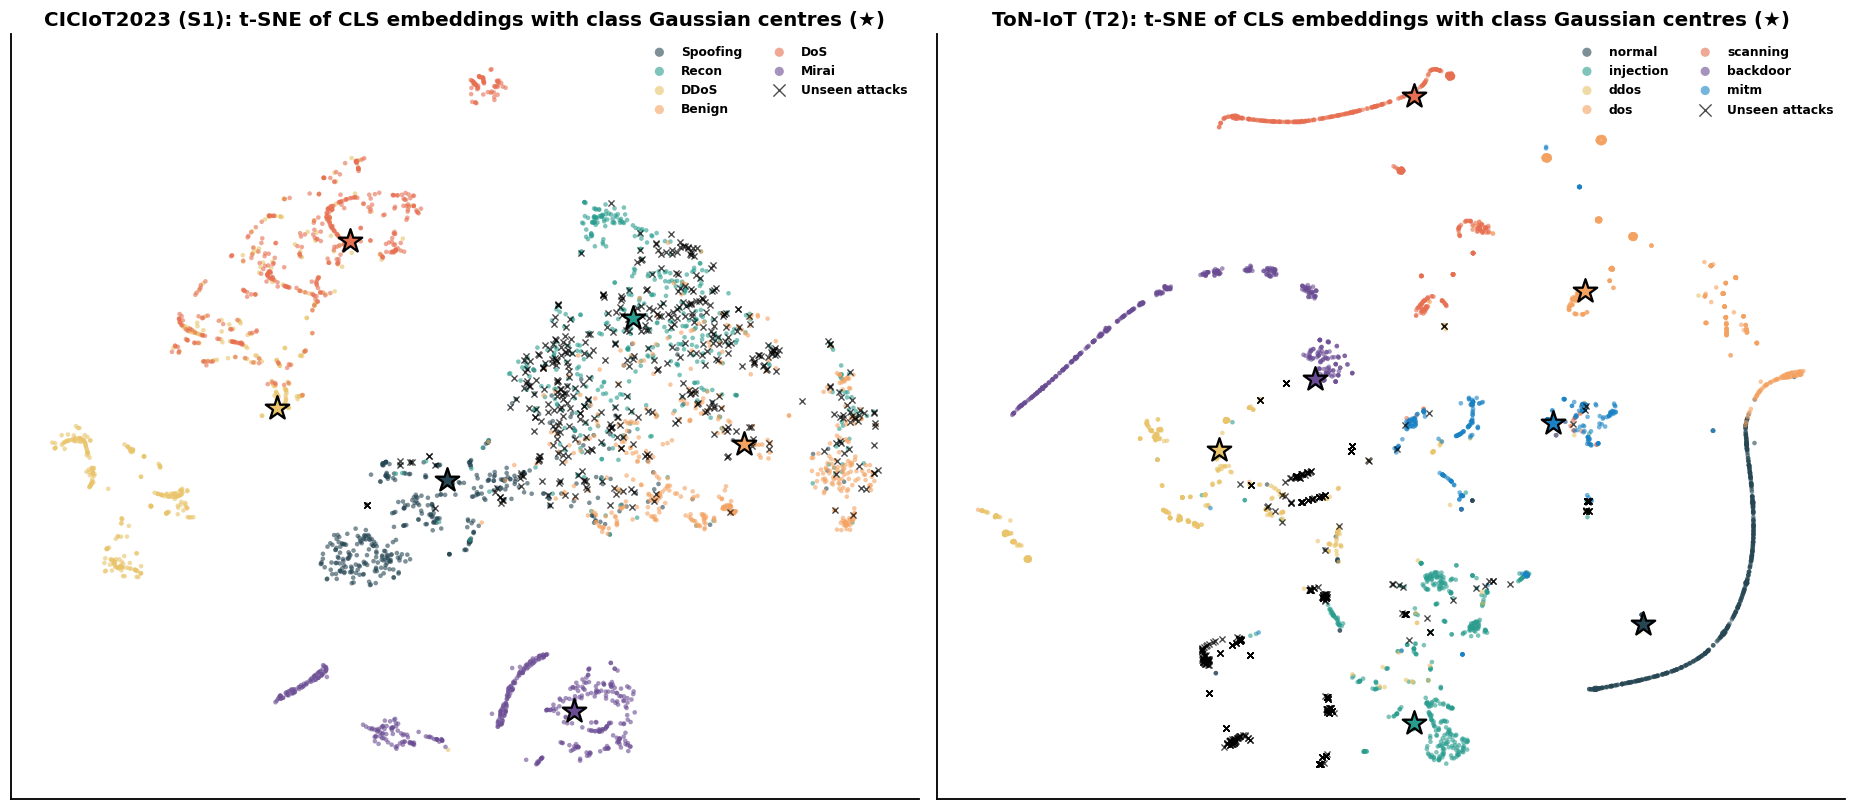

In [21]:
LAB2METHOD = {'CNN-BiLSTM-Energy': 'CNN-BiLSTM', 'CNN-BiLSTM-OpenMax': 'CNN-BiLSTM', 'FT-Transformer-Energy': 'FT-Transformer',
              'FT-Transformer-Mahalanobis': 'FT-Transformer', 'RPL': 'RPL', 'CAC': 'CAC', 'GraphSAGE-Energy': 'GraphSAGE',
              'GAT-Energy': 'GAT', TMFT: 'TMS-FT-Transformer', PROPOSED: PROP_TMS}
s0 = CFG['seeds'][0]

FPR_GRID = np.linspace(0, 1, 201)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.3))
for ax, ds in zip(axes, CFG['datasets']):
    for m in MAIN_METHODS:
        curves, aucs = [], []
        for sp in VALID_SPLITS[ds]:
            for s in CFG['seeds']:
                a = load_arr(rid(ds, sp, LAB2METHOD[m], s)); y = a['y']; C = int(y.max()); sc = a[akey(m) + '__score']
                fpr, tpr_, _ = roc_curve(y == C, sc); ti = np.interp(FPR_GRID, fpr, tpr_); ti[0] = 0.0
                curves.append(ti); aucs.append(roc_auc_score(y == C, sc) * 100)
        mu, sd = np.mean(curves, 0), np.std(curves, 0)
        ax.plot(FPR_GRID, mu, color=MCOL[m], lw=3.2 if m == PROPOSED else 1.5, label=f'{m} ({np.mean(aucs):.1f})', zorder=5 if m == PROPOSED else 2)
        if m == PROPOSED: ax.fill_between(FPR_GRID, np.clip(mu - sd, 0, 1), np.clip(mu + sd, 0, 1), color=MCOL[m], alpha=0.15, zorder=4)
    ax.plot([0, 1], [0, 1], ls='--', color='grey', lw=1)
    ax.set_xlabel('False positive rate (known flagged unseen)'); ax.set_ylabel('True positive rate (unseen detected)')
    ax.set_title(f'{ds}: mean unseen-attack ROC over {len(VALID_SPLITS[ds])} protocols × {len(CFG["seeds"])} seeds'); ax.legend(loc='lower right', fontsize=8); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F16_roc_curves')

NCOL = max(len(VALID_SPLITS[d]) for d in CFG['datasets'])
fig, axes = plt.subplots(2, NCOL, figsize=(6 * NCOL, 8.5), squeeze=False)
for ax in axes.ravel(): ax.set_visible(False)
for i, ds in enumerate(CFG['datasets']):
    for j, sp in enumerate(VALID_SPLITS[ds][:axes.shape[1]]):
        a = load_arr(rid(ds, sp, PROP_TMS, s0)); y = a['y']; C = int(y.max()); sc = a[akey(PROPOSED) + '__score']
        thr = float(a[akey('global threshold (no conformal)') + '__thr'][0]); tau = np.unique(a[akey(PROPOSED) + '__thr'])
        ax = axes[i, j]; ax.set_visible(True); lo, hi = np.quantile(sc, [0.005, 0.995]); bins = np.linspace(lo, hi, 70)
        ax.hist(sc[y < C], bins=bins, density=True, color='#2a9d8f', alpha=0.7, label='Known classes')
        ax.hist(sc[y == C], bins=bins, density=True, color='#d62828', alpha=0.6, label='Unseen attacks')
        ax.axvline(thr, color='black', ls='--', lw=2, label='Global threshold (95% known TPR)')
        for i_, t_ in enumerate(tau): ax.axvline(t_, color='#6a4c93', ls=':', lw=1.4, label='Class-conditional conformal thresholds' if i_ == 0 else None)
        ax.set_title(f'{ds} · {sp}'); ax.set_xlabel('Relative token-Gaussian open-set score'); ax.set_ylabel('Density'); ax.legend(fontsize=8); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F17_score_distributions')

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, ds in zip(axes, CFG['datasets']):
    sp = VALID_SPLITS[ds][0]; B = get_bundle(ds, sp); a = load_arr(rid(ds, sp, PROP_TMS, s0)); C = B['C']
    cm = confusion_matrix(a['y'], a[akey(PROPOSED) + '__open'], labels=np.arange(C + 1)); cmn = cm / cm.sum(1, keepdims=True).clip(1)
    labs = B['known'] + ['UNSEEN']
    sns.heatmap(cmn * 100, annot=True, fmt='.1f', cmap='rocket_r', xticklabels=labs, yticklabels=labs, ax=ax, vmin=0, vmax=100,
                linewidths=0.8, linecolor='white', cbar_kws={'label': 'Row-normalised (%)'}, annot_kws={'size': 9, 'weight': 'bold'})
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(f'{ds} ({sp}): open-set confusion matrix'); ax.tick_params(axis='x', rotation=40); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F18_open_confusion')

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
for ax, ds in zip(axes, CFG['datasets']):
    sp = VALID_SPLITS[ds][0]; B = get_bundle(ds, sp); C = B['C']
    g = Rm[(Rm['dataset'] == ds) & (Rm['split'] == sp)].groupby('label')['Open-MacroF1'].mean().drop(PROPOSED)
    best = g.idxmax(); labs = B['known'] + ['UNSEEN']; x = np.arange(C + 1)
    for off, m, col in [(-0.2, best, MCOL[best]), (0.2, PROPOSED, MCOL[PROPOSED])]:
        f1s = np.mean([precision_recall_fscore_support(load_arr(rid(ds, sp, LAB2METHOD[m], s))['y'],
                      load_arr(rid(ds, sp, LAB2METHOD[m], s))[akey(m) + '__open'], labels=np.arange(C + 1), zero_division=0)[2]
                      for s in CFG['seeds']], 0) * 100
        ax.bar(x + off, f1s, 0.4, color=col, edgecolor='black', lw=0.6, label=m)
    ax.set_xticks(x); ax.set_xticklabels(labs, rotation=35); ax.set_ylabel('F1 (%)'); ax.set_ylim(0, 105)
    ax.set_title(f'{ds} ({sp}): per-class open-set F1 vs strongest baseline'); ax.legend(); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F19_per_class_f1')

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
for ax, ds in zip(axes, CFG['datasets']):
    sp = VALID_SPLITS[ds][0]; B = get_bundle(ds, sp); a = load_arr(rid(ds, sp, PROP_TMS, s0)); C = B['C']
    y = a['y']; z = a['z'].astype(np.float32); rng = np.random.default_rng(0)
    pick = np.concatenate([rng.choice(np.where(y == c)[0], min(450, (y == c).sum()), replace=False) for c in np.unique(y)])
    mu, mcls = a['mix_mu'], a['mix_cls']
    E = TSNE(2, init='pca', perplexity=35, random_state=0).fit_transform(np.vstack([z[pick], mu]))
    Ez, Ep = E[:len(pick)], E[len(pick):]; fc = fam_colors(B['known'])
    for c in range(C):
        m = y[pick] == c; ax.scatter(Ez[m, 0], Ez[m, 1], s=9, alpha=0.6, color=fc[B['known'][c]], label=B['known'][c], edgecolors='none')
    m = y[pick] == C; ax.scatter(Ez[m, 0], Ez[m, 1], s=16, marker='x', color='black', alpha=0.7, label='Unseen attacks', lw=0.9)
    for c in range(C):
        ax.scatter(Ep[mcls == c, 0], Ep[mcls == c, 1], s=260, marker='*', color=fc[B['known'][c]], edgecolors='black', linewidths=1.5, zorder=10)
    ax.set_title(f'{ds} ({sp}): t-SNE of CLS embeddings with class Gaussian centres (★)'); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(markerscale=2, fontsize=8, ncol=2, loc='best')
plt.tight_layout(); savefig(fig, 'F20_tsne_mixture')

## Stage 12 · Conformal calibration analysis

                                         frr  unk_recall
dataset    mode                                         
CICIoT2023 Class-conditional conformal  5.27       40.90
           Global threshold             6.47       46.43
ToN-IoT    Class-conditional conformal  9.01       59.12
           Global threshold             8.71       57.05


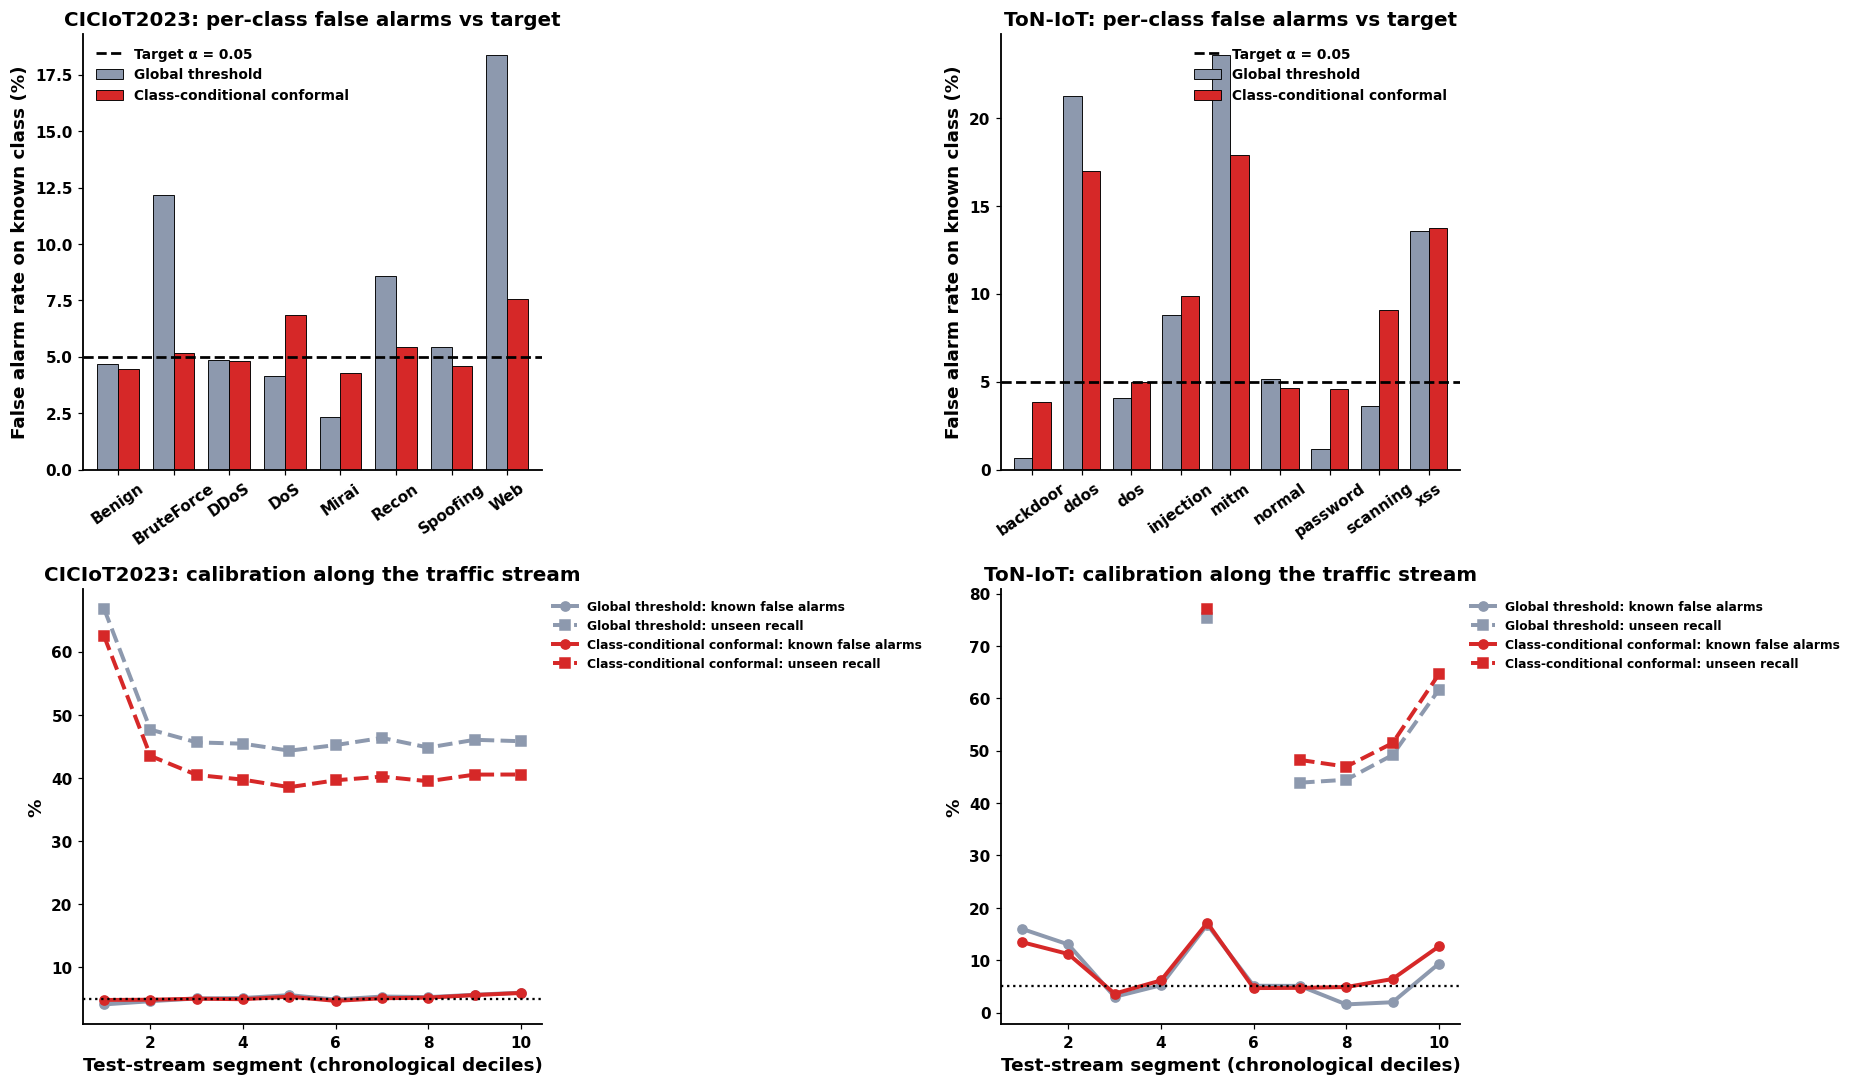

In [18]:
rows, seg = [], []
for ds in CFG['datasets']:
    for sp in VALID_SPLITS[ds]:
        B = get_bundle(ds, sp)
        for s in CFG['seeds']:
            a = load_arr(rid(ds, sp, PROP_TMS, s)); y = a['y']; C = int(y.max())
            for lab, mode in [(PROPOSED, 'Class-conditional conformal'), ('global threshold (no conformal)', 'Global threshold')]:
                po = a[akey(lab) + '__open']
                for c in range(C):
                    m = y == c
                    if m.sum(): rows.append(dict(dataset=ds, split=sp, seed=s, mode=mode, cls=B['known'][c], frr=np.mean(po[m] == C) * 100,
                                                 unk_recall=np.mean(po[y == C] == C) * 100))
                edges = np.linspace(0, len(y), 11).astype(int)
                for k_ in range(10):
                    sl = slice(edges[k_], edges[k_ + 1]); yy, pp = y[sl], po[sl]
                    seg.append(dict(dataset=ds, split=sp, seed=s, mode=mode, segment=k_ + 1,
                                    frr=np.mean(pp[yy < C] == C) * 100 if (yy < C).any() else np.nan,
                                    rec=np.mean(pp[yy == C] == C) * 100 if (yy == C).any() else np.nan))
CAL, SEG = pd.DataFrame(rows), pd.DataFrame(seg)
CAL.groupby(['dataset', 'mode'])[['frr', 'unk_recall']].mean().round(2).to_csv(os.path.join(D['tables'], 'T_conformal.csv'))
print(CAL.groupby(['dataset', 'mode'])[['frr', 'unk_recall']].mean().round(2))
fig, axes = plt.subplots(2, 2, figsize=(17, 10))
for j, ds in enumerate(CFG['datasets']):
    ax = axes[0, j]; g = CAL[CAL['dataset'] == ds].groupby(['cls', 'mode'])['frr'].mean().unstack()[['Global threshold', 'Class-conditional conformal']]
    g.plot(kind='bar', ax=ax, color=['#8d99ae', '#d62828'], edgecolor='black', lw=0.6, width=0.75)
    ax.axhline(CFG['alpha'] * 100, color='black', ls='--', lw=1.8, label=f'Target α = {CFG["alpha"]:.2f}')
    ax.set_ylabel('False alarm rate on known class (%)'); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=35)
    ax.set_title(f'{ds}: per-class false alarms vs target'); ax.legend(); bold_ticks(ax)
    ax = axes[1, j]
    for mode, col in [('Global threshold', '#8d99ae'), ('Class-conditional conformal', '#d62828')]:
        g = SEG[(SEG['dataset'] == ds) & (SEG['mode'] == mode)].groupby('segment')
        ax.plot(g['frr'].mean().index, g['frr'].mean(), color=col, lw=2.6, marker='o', label=f'{mode}: known false alarms')
        ax.plot(g['rec'].mean().index, g['rec'].mean(), color=col, lw=2.6, marker='s', ls='--', label=f'{mode}: unseen recall')
    ax.axhline(CFG['alpha'] * 100, color='black', ls=':', lw=1.5)
    ax.set_xlabel('Test-stream segment (chronological deciles)'); ax.set_ylabel('%'); ax.set_title(f'{ds}: calibration along the traffic stream')
    ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.0, 1.0)); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F21_conformal_calibration')

## Stage 12b · Explainability: feature-token attributions, attack fingerprints and faithfulness

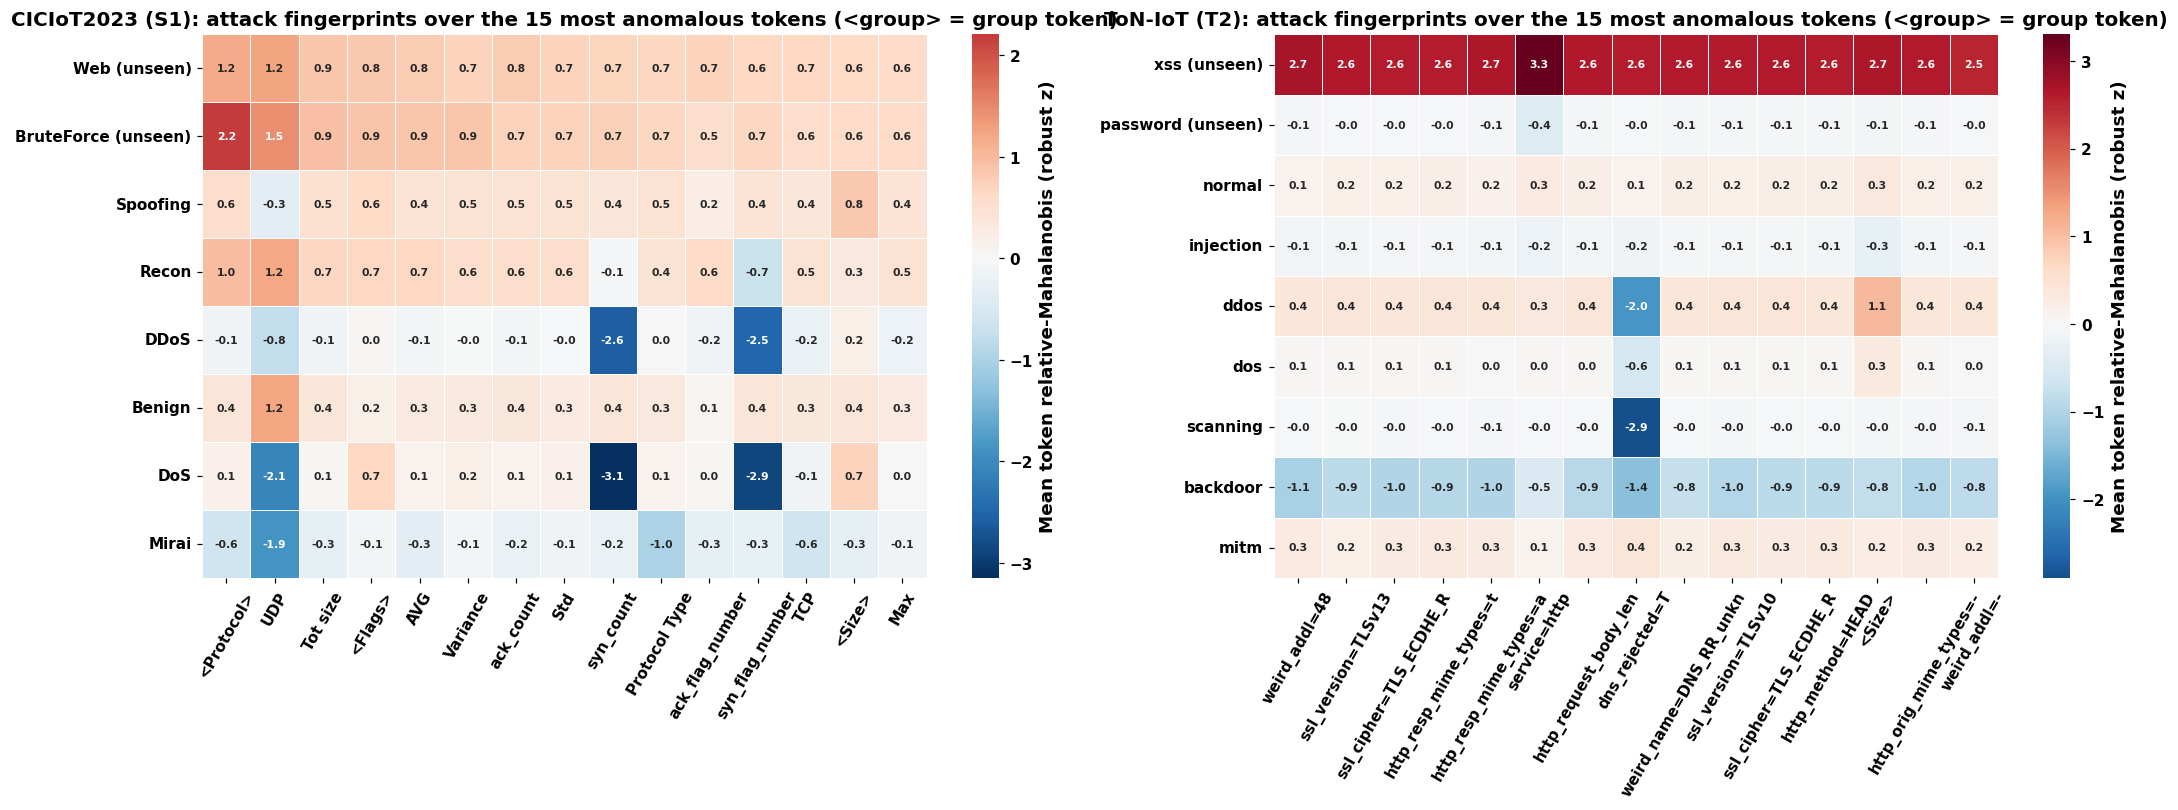

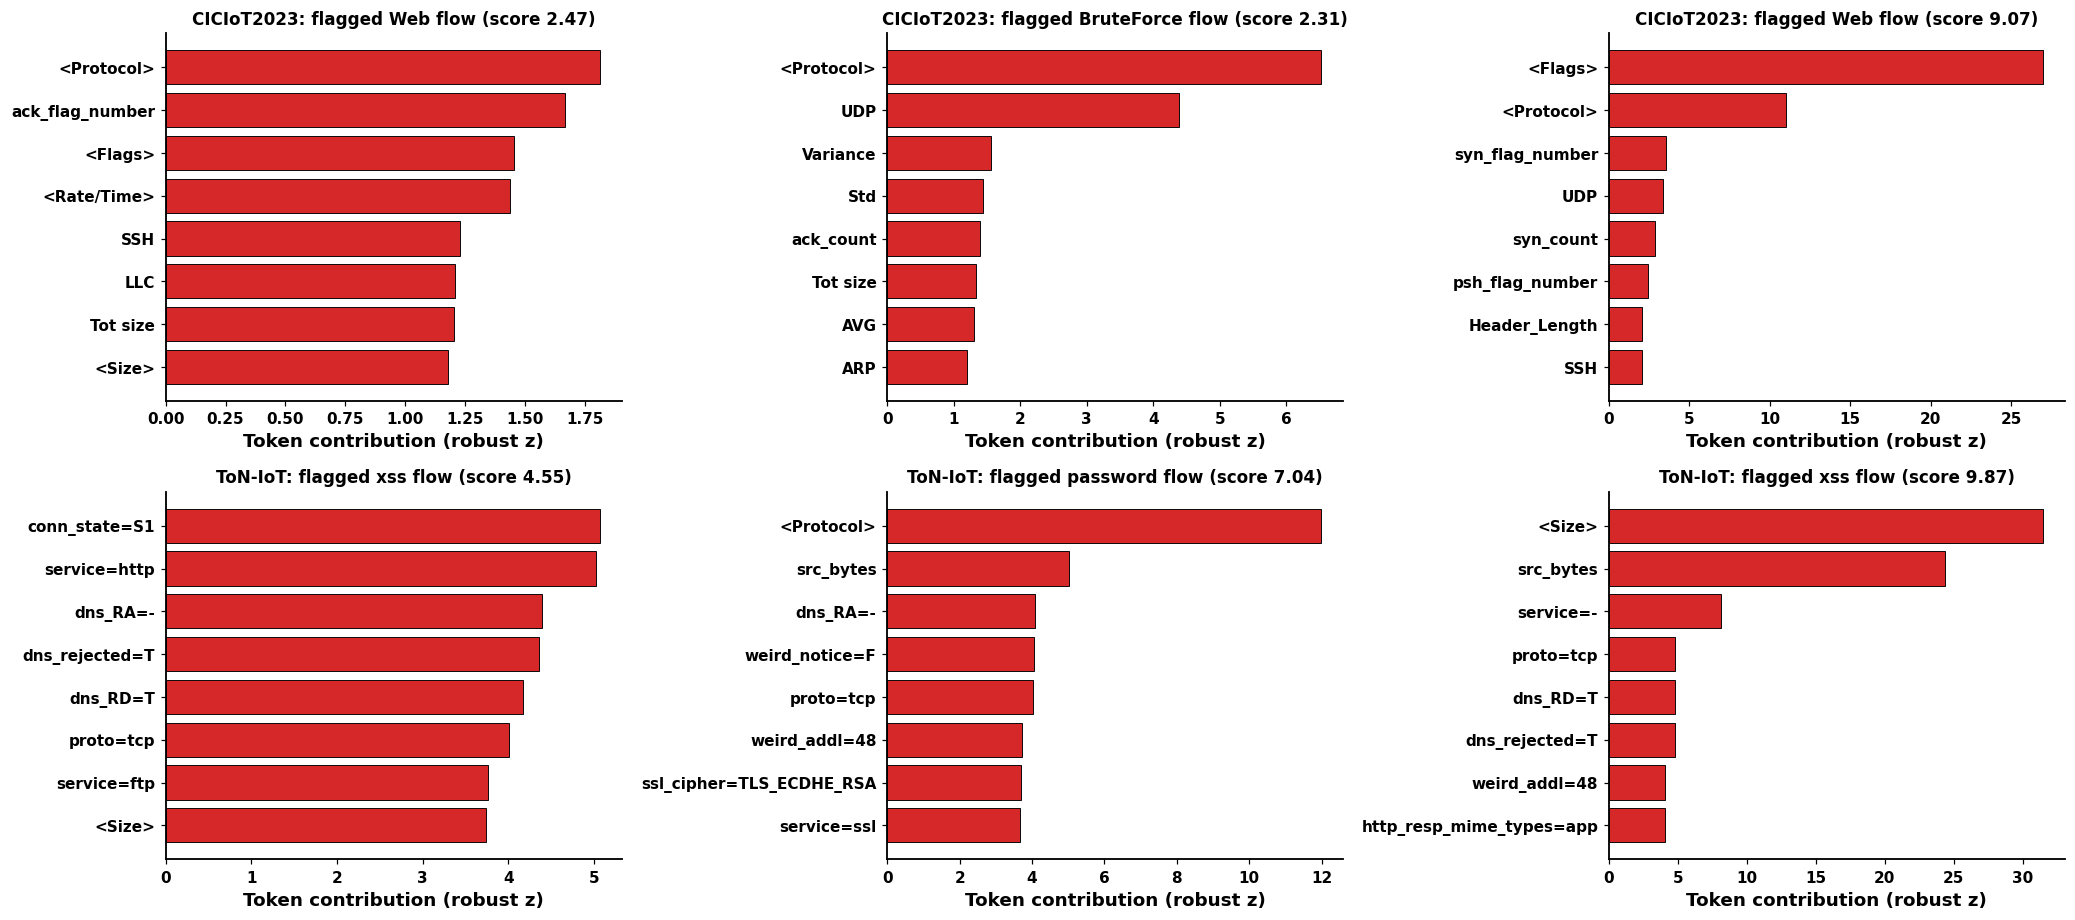

                                       mean    std
dataset    mode                    k              
CICIoT2023 Random tokens           1 -0.024  0.025
                                   2 -0.139  0.046
                                   3 -0.145  0.038
                                   5 -0.181  0.092
                                   8 -0.227  0.120
           Top-k attributed tokens 1  0.001  0.084
                                   2 -0.044  0.106
                                   3 -0.066  0.140
                                   5 -0.151  0.185
                                   8 -0.165  0.195
ToN-IoT    Random tokens           1 -0.051  0.058
                                   2 -0.090  0.129
                                   3 -0.155  0.180
                                   5 -0.226  0.299
                                   8 -0.398  0.434
           Top-k attributed tokens 1 -0.033  0.036
                                   2 -0.197  0.178
                               

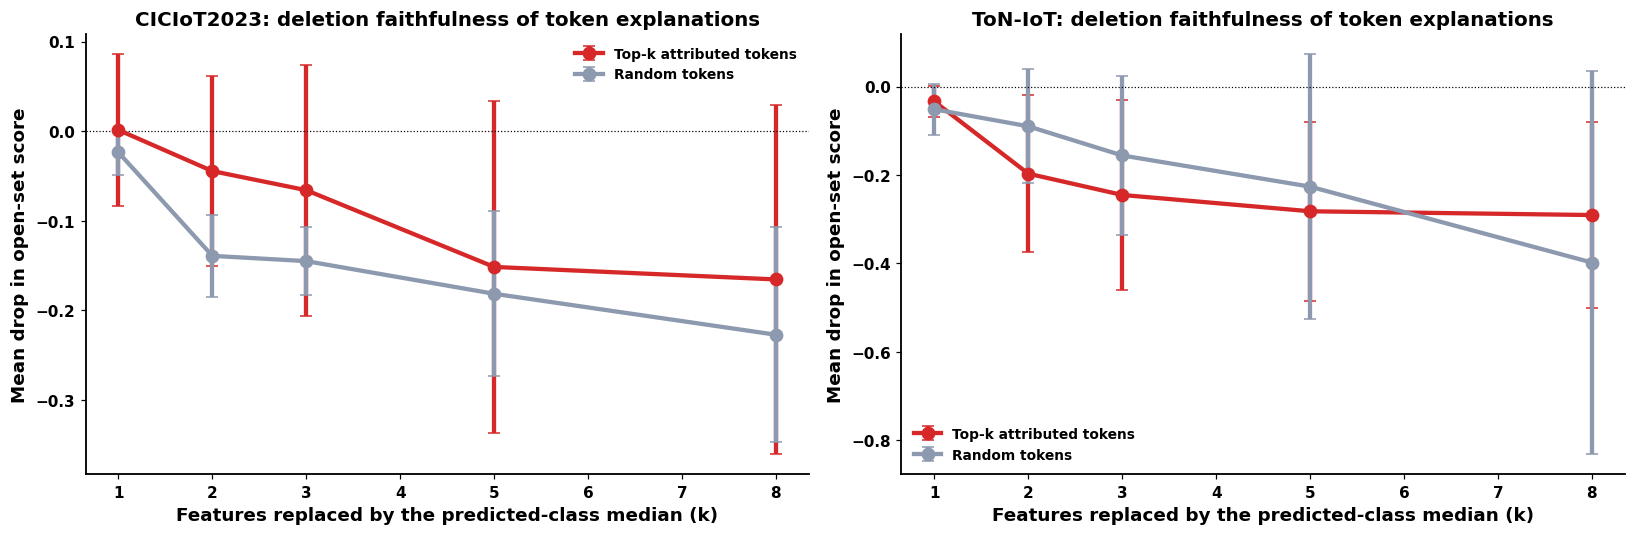

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(20, 7.5))
for ax, ds in zip(axes, CFG['datasets']):
    sp = VALID_SPLITS[ds][0]; B = get_bundle(ds, sp); a = load_arr(rid(ds, sp, PROP_TMS, s0)); C = B['C']
    A = a['expl'].astype(np.float32); y = a['y']; fam = B['fam'][B['idx']['te']]
    TN = token_names(ds); top = np.argsort(-A[y == C].mean(0))[:15]; names = [TN[j][:22] for j in top]
    rows = B['unknown'] + B['known']
    M = pd.DataFrame([A[fam == f][:, top].mean(0) for f in rows], index=[f'{f} (unseen)' if f in B['unknown'] else f for f in rows], columns=names)
    sns.heatmap(M, ax=ax, cmap='RdBu_r', center=0, linewidths=0.6, linecolor='white', cbar_kws={'label': 'Mean token relative-Mahalanobis (robust z)'},
                annot=True, fmt='.1f', annot_kws={'size': 7, 'weight': 'bold'})
    ax.set_title(f'{ds} ({sp}): attack fingerprints over the 15 most anomalous tokens (<group> = group token)'); ax.tick_params(axis='x', rotation=60); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F27_token_fingerprints')

fig, axes = plt.subplots(2, 3, figsize=(19, 8.5))
for i, ds in enumerate(CFG['datasets']):
    sp = VALID_SPLITS[ds][0]; B = get_bundle(ds, sp); a = load_arr(rid(ds, sp, PROP_TMS, s0)); C = B['C']
    A = a['expl'].astype(np.float32); y = a['y']; sc = a[akey(PROPOSED) + '__score']; po = a[akey(PROPOSED) + '__open']; fam = B['fam'][B['idx']['te']]
    cand = np.where((y == C) & (po == C))[0]
    picks = []
    for f in B['unknown']:
        cf = cand[fam[cand] == f]
        if len(cf): picks.append(cf[np.argsort(-sc[cf])[len(cf) // 2]])
    picks = (picks + list(cand[np.argsort(-sc[cand])][:3]))[:3]
    for j, p in enumerate(picks):
        ax = axes[i, j]; o = np.argsort(-A[p])[:8][::-1]
        ax.barh([token_names(ds)[k][:24] for k in o], A[p, o], color=['#d62828' if v > 0 else '#2a9d8f' for v in A[p, o]], edgecolor='black', lw=0.6)
        ax.set_title(f'{ds}: flagged {fam[p]} flow (score {sc[p]:.2f})', fontsize=11); ax.set_xlabel('Token contribution (robust z)'); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F28_flow_explanations')

def faithfulness(ds, sp, seed, n=1500, ks=(1, 2, 3, 5, 8), draws=3):
    p = os.path.join(D['runs'], f'FAITH4_{CFG["tag"]}_{ds}_{sp}_s{seed}.json')
    if os.path.exists(p): return pd.DataFrame(jload(p))
    B, model = load_backbone(ds, sp, seed); enc = model.enc; C = B['C']; a = load_arr(rid(ds, sp, PROP_TMS, seed))
    sub = strat_idx(B['y'][B['idx']['tr']], 40000); itr = B['idx']['tr'][sub]
    Xtr = B['X'][torch.tensor(itr, device=DEVICE)]; ytr = torch.tensor(B['y'][itr], device=DEVICE)
    st = tm_fit(enc, Xtr, ytr, C, TM['gamma'])
    Tv, Cv = tm_raw(enc, B['X'][torch.tensor(B['idx']['va'], device=DEVICE)], st)
    REF = torch.stack([Xtr[ytr == c].median(0).values for c in range(C)])
    flag = np.where((a['y'] == C) & (a[akey(PROPOSED) + '__open'] == C))[0]
    flag = np.random.default_rng(0).choice(flag, min(n, len(flag)), replace=False) if len(flag) else flag
    if len(flag) == 0: return pd.DataFrame()
    X0 = B['X'][torch.tensor(B['idx']['te'][flag], device=DEVICE)]; A = a['expl'][flag][:, :B['nF']].astype(np.float32)
    pc = torch.tensor(a[akey(PROPOSED) + '__pred'][flag].astype(np.int64), device=DEVICE).clamp(max=C - 1)
    R0 = REF[pc]; rr = torch.arange(len(flag), device=DEVICE)[:, None]
    def score(X):
        Tt, Ct = tm_raw(enc, X, st); return tm_aggregate(Tv, Cv, Tt, Ct)[1]
    def reset(idx):
        Xa = X0.clone(); ii = torch.tensor(idx, device=DEVICE); Xa[rr, ii] = R0[rr, ii]; return Xa
    base = score(X0); rows = []; rng = np.random.default_rng(1); nF = X0.shape[1]
    for k in ks:
        top = np.argsort(-A, 1)[:, :k]
        rows.append(dict(k=k, mode='Top-k attributed tokens', drop=float(np.mean(base - score(reset(top))))))
        dr = [np.mean(base - score(reset(np.stack([rng.choice(nF, k, replace=False) for _ in range(len(flag))])))) for _ in range(draws)]
        rows.append(dict(k=k, mode='Random tokens', drop=float(np.mean(dr))))
    jdump(rows, p); return pd.DataFrame(rows)

FA = pd.concat([faithfulness(ds, VALID_SPLITS[ds][0], s).assign(dataset=ds, seed=s) for ds in CFG['datasets'] for s in CFG['seeds']])
FA.groupby(['dataset', 'mode', 'k'])['drop'].agg(['mean', 'std']).round(3).to_csv(os.path.join(D['tables'], 'T_faithfulness.csv'))
print(FA.groupby(['dataset', 'mode', 'k'])['drop'].agg(['mean', 'std']).round(3))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, ds in zip(axes, CFG['datasets']):
    for mode, col in [('Top-k attributed tokens', '#d62828'), ('Random tokens', '#8d99ae')]:
        g = FA[(FA['dataset'] == ds) & (FA['mode'] == mode)].groupby('k')['drop']
        ax.errorbar(g.mean().index, g.mean(), yerr=g.std(), color=col, lw=2.8, marker='o', ms=8, capsize=4, label=mode)
    ax.axhline(0, color='black', lw=0.8, ls=':')
    ax.set_xlabel('Features replaced by the predicted-class median (k)'); ax.set_ylabel('Mean drop in open-set score')
    ax.set_title(f'{ds}: deletion faithfulness of token explanations'); ax.legend(); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F29_faithfulness')

## Stage 13 · Ablation study

>> v2_CICIoT2023_S1_TGF_noGroupP_k10_s42
  ep00 loss 0.9466 | val F1 0.7274 acc 0.7357 | 2.8s
  ep01 loss 0.5637 | val F1 0.7774 acc 0.7775 | 2.5s
  ep02 loss 0.4776 | val F1 0.8090 acc 0.8080 | 2.4s
  ep03 loss 0.4436 | val F1 0.8101 acc 0.8123 | 2.4s
  ep04 loss 0.4255 | val F1 0.8225 acc 0.8217 | 2.4s
  ep05 loss 0.4131 | val F1 0.8217 acc 0.8219 | 2.4s
  ep06 loss 0.4030 | val F1 0.8264 acc 0.8256 | 2.4s
  ep07 loss 0.3952 | val F1 0.8304 acc 0.8311 | 2.5s
  ep08 loss 0.3928 | val F1 0.8326 acc 0.8327 | 2.4s
  ep09 loss 0.3866 | val F1 0.8313 acc 0.8310 | 2.3s
  ep10 loss 0.3839 | val F1 0.8251 acc 0.8271 | 2.3s
  ep11 loss 0.3810 | val F1 0.8290 acc 0.8283 | 2.3s
  ep12 loss 0.3796 | val F1 0.8333 acc 0.8325 | 2.4s
  ep13 loss 0.3765 | val F1 0.8334 acc 0.8333 | 2.5s
  ep14 loss 0.3737 | val F1 0.8373 acc 0.8367 | 2.4s
  ep15 loss 0.3739 | val F1 0.8341 acc 0.8334 | 2.3s
  ep16 loss 0.3722 | val F1 0.8302 acc 0.8297 | 2.4s
  ep17 loss 0.3707 | val F1 0.8356 acc 0.8349 | 2.4s
  ep1

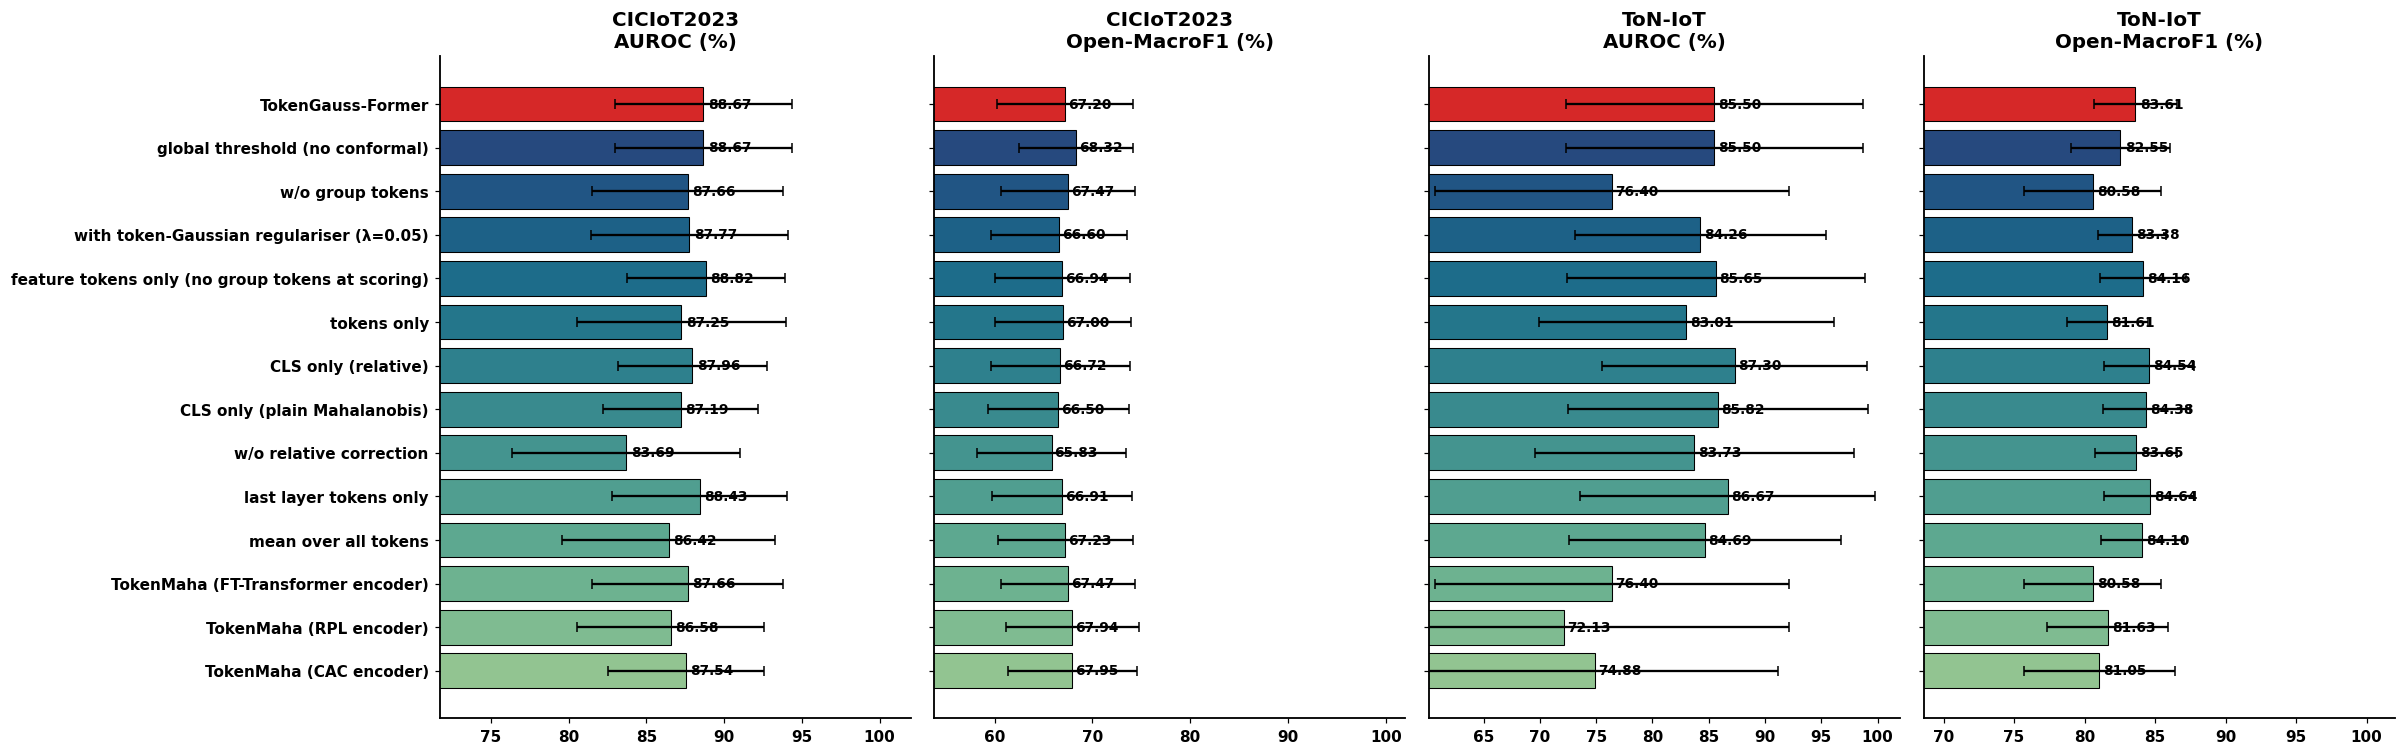

In [20]:
for ds in CFG['datasets']:
    for sp in VALID_SPLITS[ds]:
        for seed in CFG['seeds']:
            for v in ['noGroupP', 'full']:
                run_one(ds, sp, seed, 'TGF', variant=v); tokenmaha_run(ds, sp, seed, 'TGF', variant=v)
            for bb in ['RPL', 'CAC']:
                tokenmaha_run(ds, sp, seed, backbone=bb)
R = load_runs()
ABL = [PROPOSED, 'global threshold (no conformal)', 'w/o group tokens', REG_LAB, 'feature tokens only (no group tokens at scoring)',
       'tokens only', 'CLS only (relative)', 'CLS only (plain Mahalanobis)', 'w/o relative correction', 'last layer tokens only', 'mean over all tokens',
       TMFT, 'TokenMaha (RPL encoder)', 'TokenMaha (CAC encoder)']
A = R[(R['k'] == CFG['k']) & R['dataset'].isin(CFG['datasets']) & R['label'].isin(ABL) & R['method'].str.startswith('TMS-')]
TA = A.groupby(['dataset', 'label'])[['Closed-MacroF1', 'AUROC', 'FPR95', 'Open-MacroF1', 'Unknown-Recall', 'Known-FRR']].agg(['mean', 'std']).round(2)
TA.to_csv(os.path.join(D['tables'], 'T_ablation.csv')); print(TA)
TAs = A.groupby(['dataset', 'split', 'label'])[['AUROC', 'FPR95', 'Open-MacroF1']].mean().round(2)
TAs.to_csv(os.path.join(D['tables'], 'T_ablation_per_split.csv')); print(TAs)

fig, axes = plt.subplots(1, 4, figsize=(22, 7), sharey=True)
for col, (ds, met) in enumerate([(ds, m) for ds in CFG['datasets'] for m in ['AUROC', 'Open-MacroF1']]):
    ax = axes[col]; g = A[A['dataset'] == ds].groupby('label')[met]; mu = g.mean().reindex(ABL[::-1]); sd = g.std(ddof=0).reindex(ABL[::-1])
    cols = ['#d62828' if l == PROPOSED else sns.color_palette('crest', len(ABL))[i] for i, l in enumerate(ABL[::-1])]
    ax.barh(range(len(ABL)), mu, xerr=sd, color=cols, edgecolor='black', lw=0.7, capsize=3)
    for i, v in enumerate(mu): ax.text(v + 0.3, i, f'{v:.2f}', va='center', fontsize=9, fontweight='bold')
    ax.set_yticks(range(len(ABL))); ax.set_yticklabels(ABL[::-1]); ax.set_xlim(max(0, np.nanmin(mu) - 12), 102)
    ax.set_title(f'{ds}\n{met} (%)'); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F22_ablation')

## Stage 14 · Sensitivity analysis

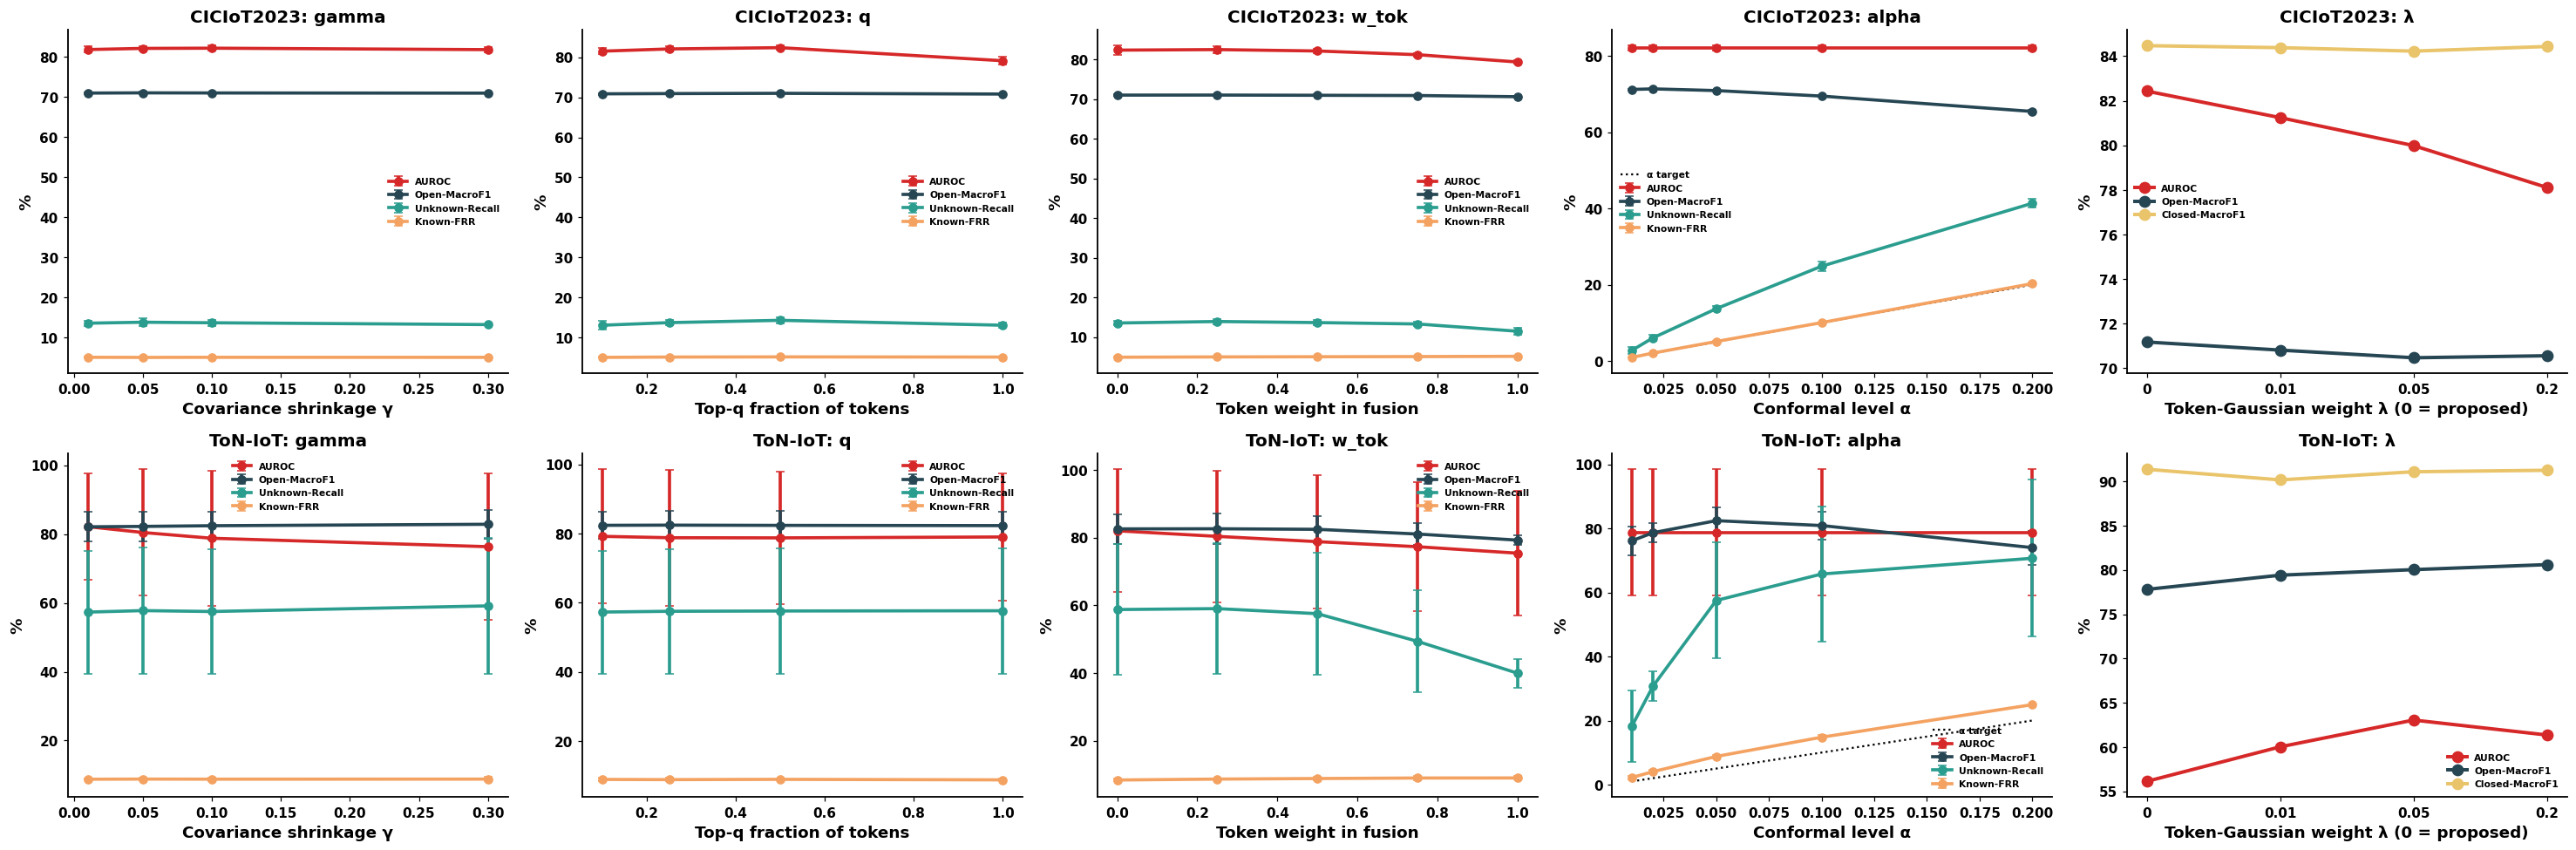

In [21]:
def tm_grid(ds, sp, seed):
    p = os.path.join(D['runs'], f'SENS_{CFG["tag"]}_TMSP_{ds}_{sp}_s{seed}.json')
    if os.path.exists(p): return pd.DataFrame(jload(p))
    B, model = load_backbone(ds, sp, seed); enc = model.enc; C = B['C']
    sub = strat_idx(B['y'][B['idx']['tr']], 40000); itr = B['idx']['tr'][sub]
    Xtr = B['X'][torch.tensor(itr, device=DEVICE)]; ytr = torch.tensor(B['y'][itr], device=DEVICE)
    Xv = B['X'][torch.tensor(B['idx']['va'], device=DEVICE)]; Xt = B['X'][torch.tensor(B['idx']['te'], device=DEVICE)]
    ov, ot = infer(model, B, None, 'va'), infer(model, B, None, 'te'); pv, pt = ov['logits'].argmax(1), ot['logits'].argmax(1)
    y = B['y'][B['idx']['te']]; rows = []
    def ev(sv, st_, al=None):
        m, _ = open_metrics(y, pt, st_, conformal_thresholds(sv, pv, C, CFG['alpha'] if al is None else al)[pt], C); return m
    for g in [0.01, 0.05, 0.1, 0.3]:
        st = tm_fit(enc, Xtr, ytr, C, g); Tv, Cv = tm_raw(enc, Xv, st); Tt, Ct = tm_raw(enc, Xt, st)
        rows.append(dict(param='gamma', value=g, **ev(*tm_aggregate(Tv, Cv, Tt, Ct)[:2])))
        if g == TM['gamma']: keep = (Tv, Cv, Tt, Ct)
    Tv, Cv, Tt, Ct = keep
    for q in [0.1, 0.25, 0.5, 1.0]: rows.append(dict(param='q', value=q, **ev(*tm_aggregate(Tv, Cv, Tt, Ct, q=q)[:2])))
    for w in [0.0, 0.25, 0.5, 0.75, 1.0]: rows.append(dict(param='w_tok', value=w, **ev(*tm_aggregate(Tv, Cv, Tt, Ct, w_tok=w)[:2])))
    sv, st_, _ = tm_aggregate(Tv, Cv, Tt, Ct)
    for al in [0.01, 0.02, 0.05, 0.1, 0.2]: rows.append(dict(param='alpha', value=al, **ev(sv, st_, al)))
    jdump(rows, p); return pd.DataFrame(rows)

for ds in CFG['datasets']:
    for v in ['lam0.01', 'lam0.2']:
        run_one(ds, VALID_SPLITS[ds][0], CFG['seeds'][0], 'TGF', variant=v); tokenmaha_run(ds, VALID_SPLITS[ds][0], CFG['seeds'][0], 'TGF', variant=v)
R_ = load_runs()
LAM = {ds: R_[(R_['dataset'] == ds) & (R_['split'] == VALID_SPLITS[ds][0]) & (R_['seed'] == CFG['seeds'][0]) &
              R_['label'].isin([PROPOSED, REG_LAB, 'lambda=0.01', 'lambda=0.2']) & R_['method'].str.startswith('TMS-TGF')].assign(
              lam=lambda d: d['label'].map({PROPOSED: 0.0, 'lambda=0.01': 0.01, REG_LAB: 0.05, 'lambda=0.2': 0.2})).sort_values('lam') for ds in CFG['datasets']}
SENS = {ds: pd.concat([tm_grid(ds, VALID_SPLITS[ds][0], s).assign(seed=s) for s in CFG['seeds']]) for ds in CFG['datasets']}
PAR = [('gamma', 'Covariance shrinkage γ'), ('q', 'Top-q fraction of tokens'), ('w_tok', 'Token weight in fusion'), ('alpha', 'Conformal level α')]
fig, axes = plt.subplots(2, 5, figsize=(27, 9))
for i, ds in enumerate(CFG['datasets']):
    for j, (par, xl) in enumerate(PAR):
        ax = axes[i, j]; S = SENS[ds][SENS[ds]['param'] == par]
        for met, col in [('AUROC', '#d62828'), ('Open-MacroF1', '#264653'), ('Unknown-Recall', '#2a9d8f'), ('Known-FRR', '#f4a261')]:
            g = S.groupby('value')[met]; ax.errorbar(g.mean().index, g.mean(), yerr=g.std(), marker='o', ms=6, lw=2.4, capsize=3, color=col, label=met)
        if par == 'alpha': ax.plot(S['value'].unique(), S['value'].unique() * 100, ls=':', color='black', lw=1.5, label='α target')
        ax.set_xlabel(xl); ax.set_ylabel('%'); ax.set_title(f'{ds}: {par}'); ax.legend(fontsize=7); bold_ticks(ax)
    ax = axes[i, 4]; L_ = LAM[ds]
    for met, col in [('AUROC', '#d62828'), ('Open-MacroF1', '#264653'), ('Closed-MacroF1', '#e9c46a')]:
        ax.plot(np.arange(len(L_)), L_[met], marker='o', ms=8, lw=2.6, color=col, label=met)
    ax.set_xticks(np.arange(len(L_))); ax.set_xticklabels([f'{v:g}' for v in L_['lam']]); ax.set_xlabel('Token-Gaussian weight λ (0 = proposed)'); ax.set_ylabel('%'); ax.set_title(f'{ds}: λ'); ax.legend(fontsize=7); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F23_sensitivity')
pd.concat([v.assign(dataset=k) for k, v in SENS.items()]).groupby(['dataset', 'param', 'value']).mean(numeric_only=True).round(2).to_csv(os.path.join(D['tables'], 'T_sensitivity.csv'))

## Stage 15 · Internal vs external (ToN-IoT) validation

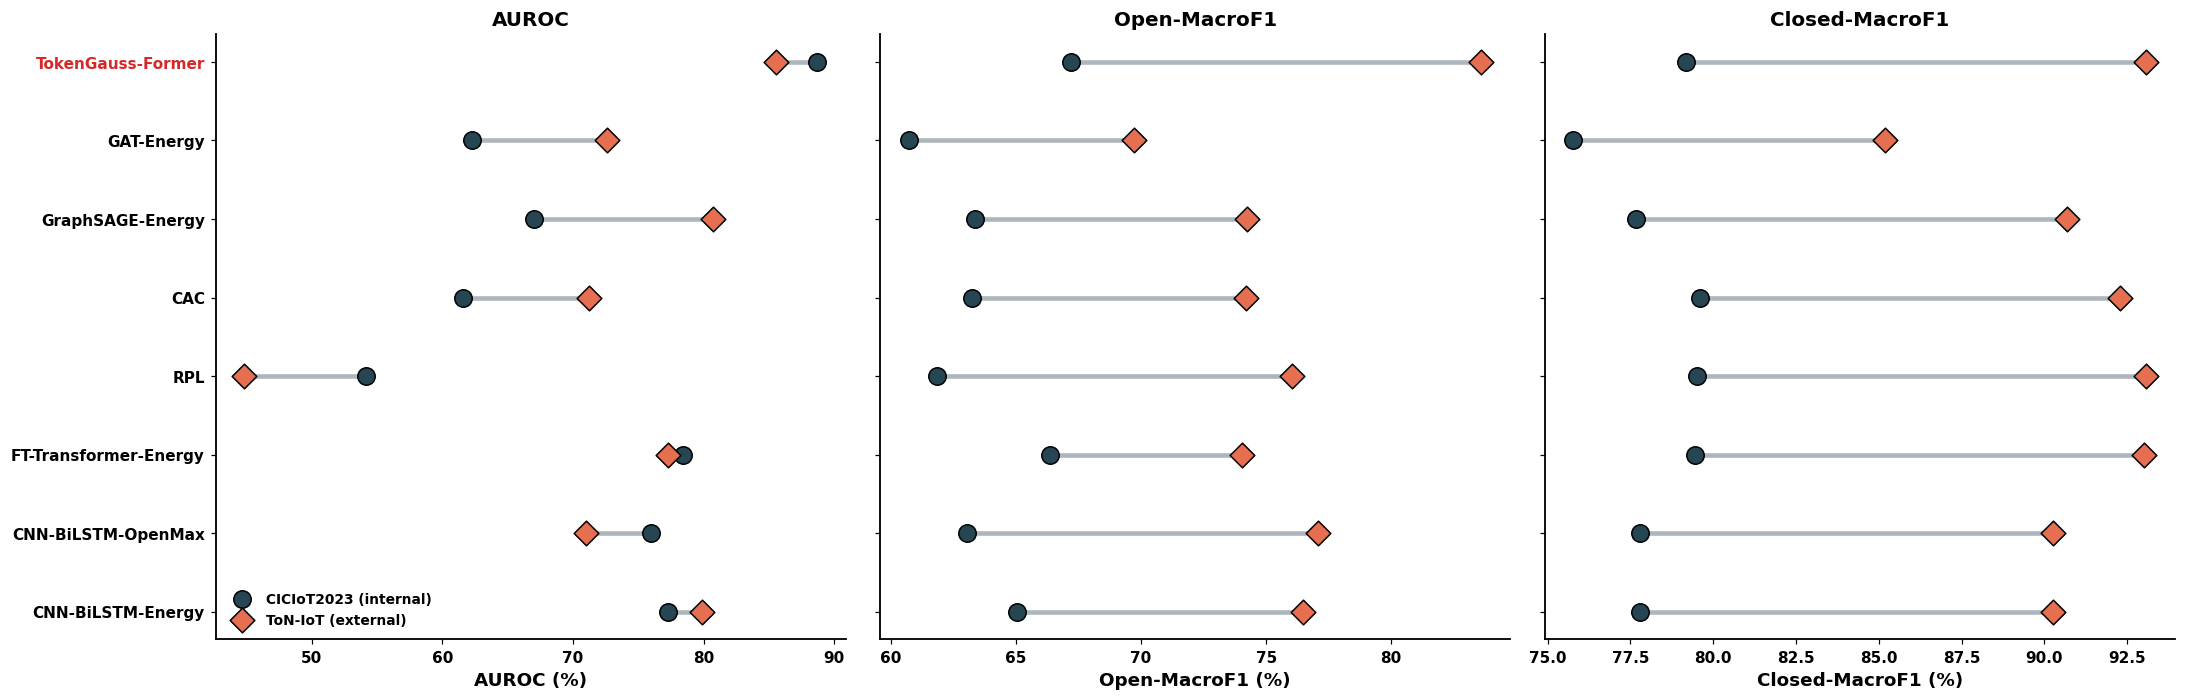

In [22]:
R = load_runs(); Rm = R[(R['variant'] == 'full') & (R['k'] == CFG['k']) & R['dataset'].isin(CFG['datasets']) & (R['label'].isin(MAIN_METHODS))]
fig, axes = plt.subplots(1, 3, figsize=(20, 6.5), sharey=True)
for ax, met in zip(axes, ['AUROC', 'Open-MacroF1', 'Closed-MacroF1']):
    g = Rm.groupby(['label', 'dataset'])[met].mean().unstack().reindex(MAIN_METHODS)
    y = np.arange(len(g))
    for i, m in enumerate(MAIN_METHODS):
        ax.plot(g.loc[m].values, [i, i], color='#adb5bd', lw=3, zorder=1)
    ax.scatter(g[CFG['datasets'][0]], y, s=130, color='#264653', edgecolors='black', zorder=3, label=f'{CFG["datasets"][0]} (internal)')
    ax.scatter(g[CFG['datasets'][1]], y, s=130, color='#e76f51', edgecolors='black', zorder=3, marker='D', label=f'{CFG["datasets"][1]} (external)')
    ax.set_yticks(y); ax.set_yticklabels(MAIN_METHODS)
    for t in ax.get_yticklabels():
        if t.get_text() == PROPOSED: t.set_color('#d62828')
    ax.set_xlabel(f'{met} (%)'); ax.set_title(met); bold_ticks(ax)
axes[0].legend(loc='lower left', fontsize=9)
plt.tight_layout(); savefig(fig, 'F24_internal_vs_external')

## Stage 16 · Statistical significance

                family       scope        metric                     baseline   n  mean_diff       p  cliffs_delta  p_holm  significant
0     Original scoring  CICIoT2023         AUROC            CNN-BiLSTM-Energy   9    11.3564  0.0645        0.6049  0.1934        False
1     Original scoring  CICIoT2023         AUROC           CNN-BiLSTM-OpenMax   9    12.6829  0.1016        0.5062  0.2031        False
2     Original scoring  CICIoT2023         AUROC        FT-Transformer-Energy   9    10.2499  0.1016        0.4074  0.2031        False
3     Original scoring  CICIoT2023         AUROC                          RPL   9    34.5426  0.0020        1.0000  0.0137         True
4     Original scoring  CICIoT2023         AUROC                          CAC   9    27.0524  0.0020        1.0000  0.0137         True
5     Original scoring  CICIoT2023         AUROC             GraphSAGE-Energy   9    21.6455  0.0195        0.5802  0.0781        False
6     Original scoring  CICIoT2023         AUROC

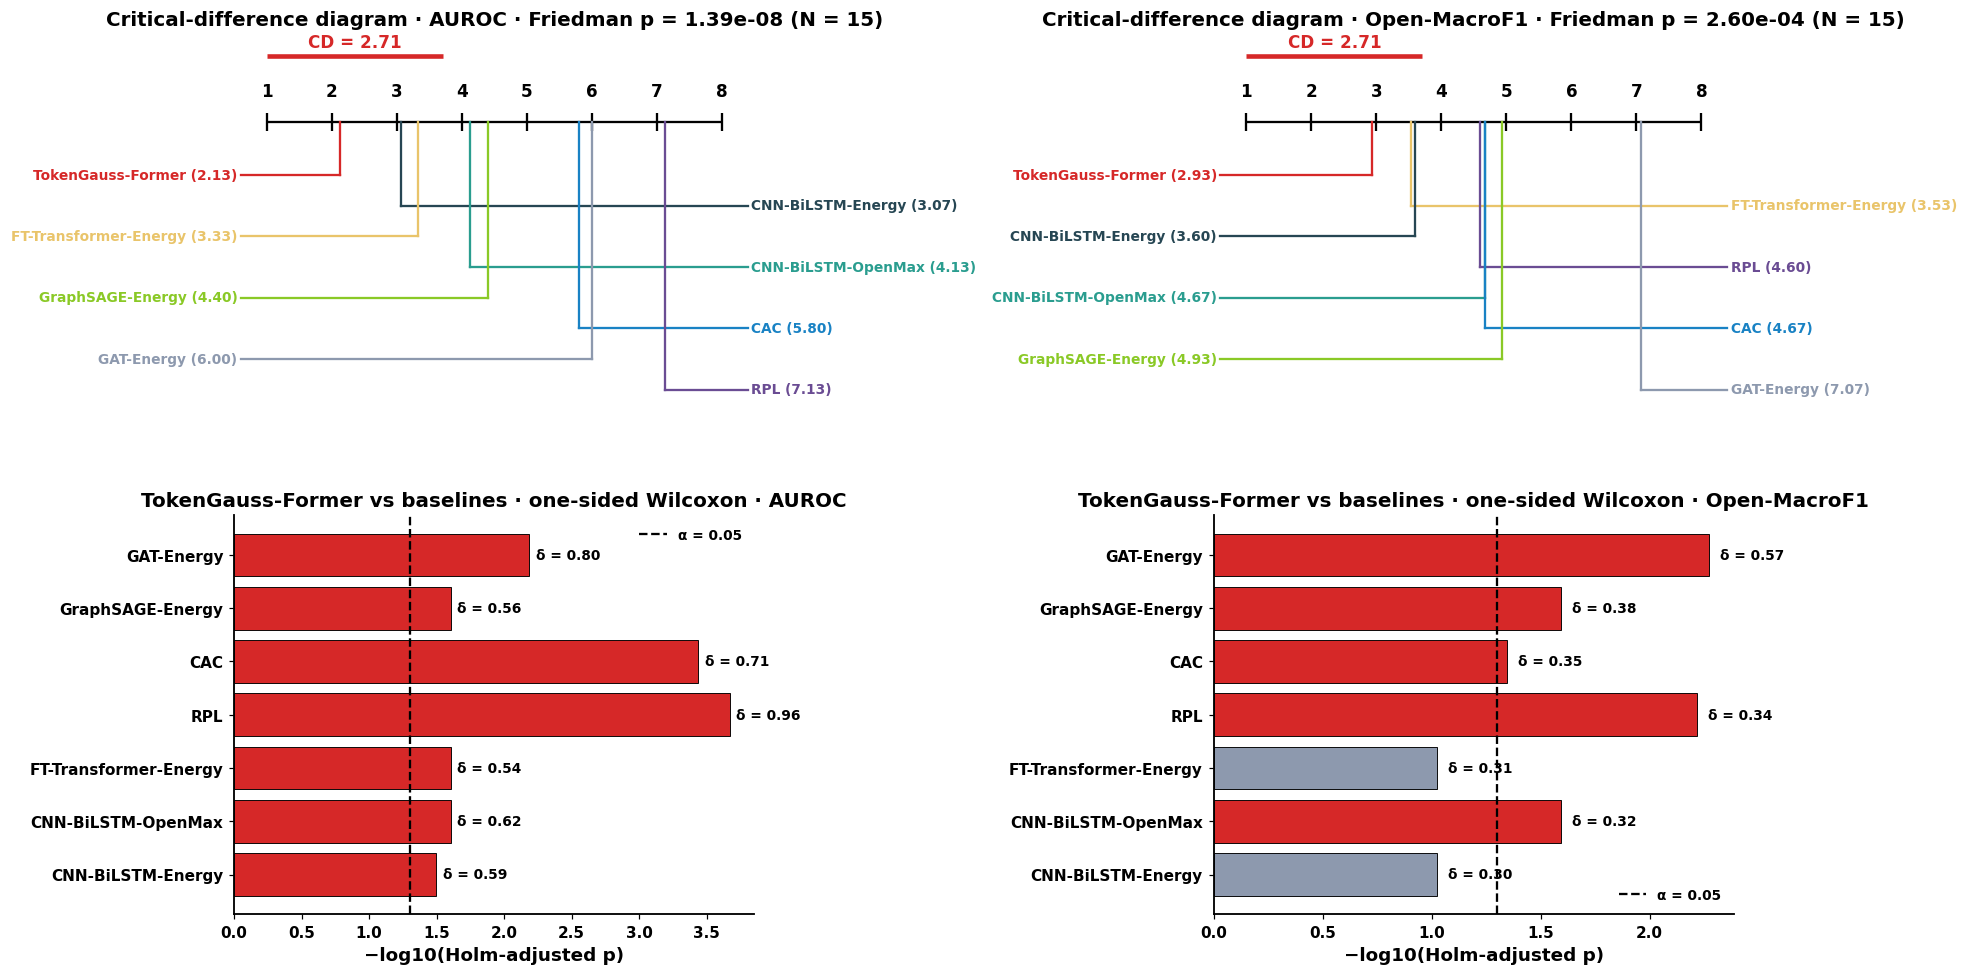

In [23]:
def holm(p):
    p = np.asarray(p); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0
    for i, j in enumerate(o): run = max(run, min(1, (m - i) * p[j])); adj[j] = run
    return adj

def cliffs(a, b):
    d = a[:, None] - b[None]; return (np.sum(d > 0) - np.sum(d < 0)) / d.size

rows = []
for fam_name, Rf, comps in [('Original scoring', Rm, MAIN_METHODS[:-1]), ('Unified MixMaha-CP', Ru, UNI[:-1])]:
  for scope in CFG['datasets'] + ['Pooled']:
    Rs = Rf if scope == 'Pooled' else Rf[Rf['dataset'] == scope]
    for met in ['AUROC', 'Open-MacroF1']:
        W = Rs.pivot_table(index=['dataset', 'split', 'seed'], columns='label', values=met).dropna()
        ps, tmp = [], []
        for m in comps:
            a, b = W[PROPOSED].values, W[m].values
            try: p = wilcoxon(a, b, alternative='greater', zero_method='zsplit').pvalue
            except ValueError: p = 1.0
            ps.append(p); tmp.append(dict(family=fam_name, scope=scope, metric=met, baseline=m, n=len(a), mean_diff=float((a - b).mean()), p=p, cliffs_delta=cliffs(a, b)))
        for t, pa in zip(tmp, holm(ps)): t['p_holm'] = pa; t['significant'] = pa < 0.05; rows.append(t)
ST = pd.DataFrame(rows); ST.to_csv(os.path.join(D['tables'], 'T_wilcoxon_holm.csv'), index=False)
print(ST.round(4).to_string())

QA = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}
fig, axes = plt.subplots(2, 2, figsize=(18, 9), gridspec_kw={'height_ratios': [1.1, 1]})
for j, met in enumerate(['AUROC', 'Open-MacroF1']):
    W = Rm.pivot_table(index=['dataset', 'split', 'seed'], columns='label', values=met).dropna()[MAIN_METHODS]
    rk = W.rank(axis=1, ascending=False).mean().sort_values(); k, N = len(rk), len(W)
    try: fp = friedmanchisquare(*[W[c].values for c in W.columns]).pvalue
    except ValueError: fp = float('nan')
    cd = QA[min(k, 10)] * math.sqrt(k * (k + 1) / (6 * N))
    ax = axes[0, j]; ax.set_xlim(0.5, k + 0.5); ax.set_ylim(0, 1); ax.axis('off')
    ax.hlines(0.8, 1, k, color='black', lw=1.5)
    for r in range(1, k + 1): ax.vlines(r, 0.78, 0.82, color='black'); ax.text(r, 0.86, str(r), ha='center', fontweight='bold')
    ax.hlines(0.95, 1, 1 + cd, color='#d62828', lw=3); ax.text(1 + cd / 2, 0.97, f'CD = {cd:.2f}', ha='center', color='#d62828', fontweight='bold')
    for i, (m, r) in enumerate(rk.items()):
        yy = 0.68 - i * 0.07
        ax.plot([r, r], [0.8, yy], color=MCOL[m], lw=1.5); ax.plot([r, 0.6 if i % 2 == 0 else k + 0.4], [yy, yy], color=MCOL[m], lw=1.5)
        ax.text(0.55 if i % 2 == 0 else k + 0.45, yy, f'{m} ({r:.2f})', ha='right' if i % 2 == 0 else 'left', va='center',
                fontsize=9, fontweight='bold', color=MCOL[m])
    ax.set_title(f'Critical-difference diagram · {met} · Friedman p = {fp:.2e} (N = {N})')
    ax = axes[1, j]; S = ST[(ST['family'] == 'Original scoring') & (ST['scope'] == 'Pooled') & (ST['metric'] == met)].set_index('baseline')
    cols = ['#d62828' if s else '#8d99ae' for s in S['significant']]
    ax.barh(S.index, -np.log10(S['p_holm'].clip(1e-12)), color=cols, edgecolor='black', lw=0.6)
    ax.axvline(-np.log10(0.05), color='black', ls='--', lw=1.5, label='α = 0.05')
    for i, (v, d) in enumerate(zip(-np.log10(S['p_holm'].clip(1e-12)), S['cliffs_delta'])): ax.text(v + 0.05, i, f'δ = {d:.2f}', va='center', fontsize=9, fontweight='bold')
    ax.set_xlabel('−log10(Holm-adjusted p)'); ax.set_title(f'{PROPOSED} vs baselines · one-sided Wilcoxon · {met}'); ax.legend(); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F25_statistics')

## Stage 17 · Computational efficiency

       dataset              method  params_M  size_MB  ms_per_1k  throughput  \
0   CICIoT2023          CNN-BiLSTM     0.113    0.452      2.128  469888.330   
1   CICIoT2023      FT-Transformer     0.158    0.631      8.596  116335.349   
2   CICIoT2023                 RPL     0.158    0.631      6.862  145725.735   
3   CICIoT2023                 CAC     0.158    0.631      6.712  148988.287   
4   CICIoT2023           GraphSAGE     0.077    0.307     23.938   41774.941   
5   CICIoT2023                 GAT     0.039    0.156     23.853   41923.368   
6      ToN-IoT          CNN-BiLSTM     0.113    0.453      2.758  362603.615   
7      ToN-IoT      FT-Transformer     0.166    0.666     16.014   62443.868   
8      ToN-IoT                 RPL     0.166    0.666     15.506   64491.468   
9      ToN-IoT                 CAC     0.166    0.666     15.448   64733.401   
10     ToN-IoT           GraphSAGE     0.088    0.353     12.794   78160.801   
11     ToN-IoT                 GAT     0

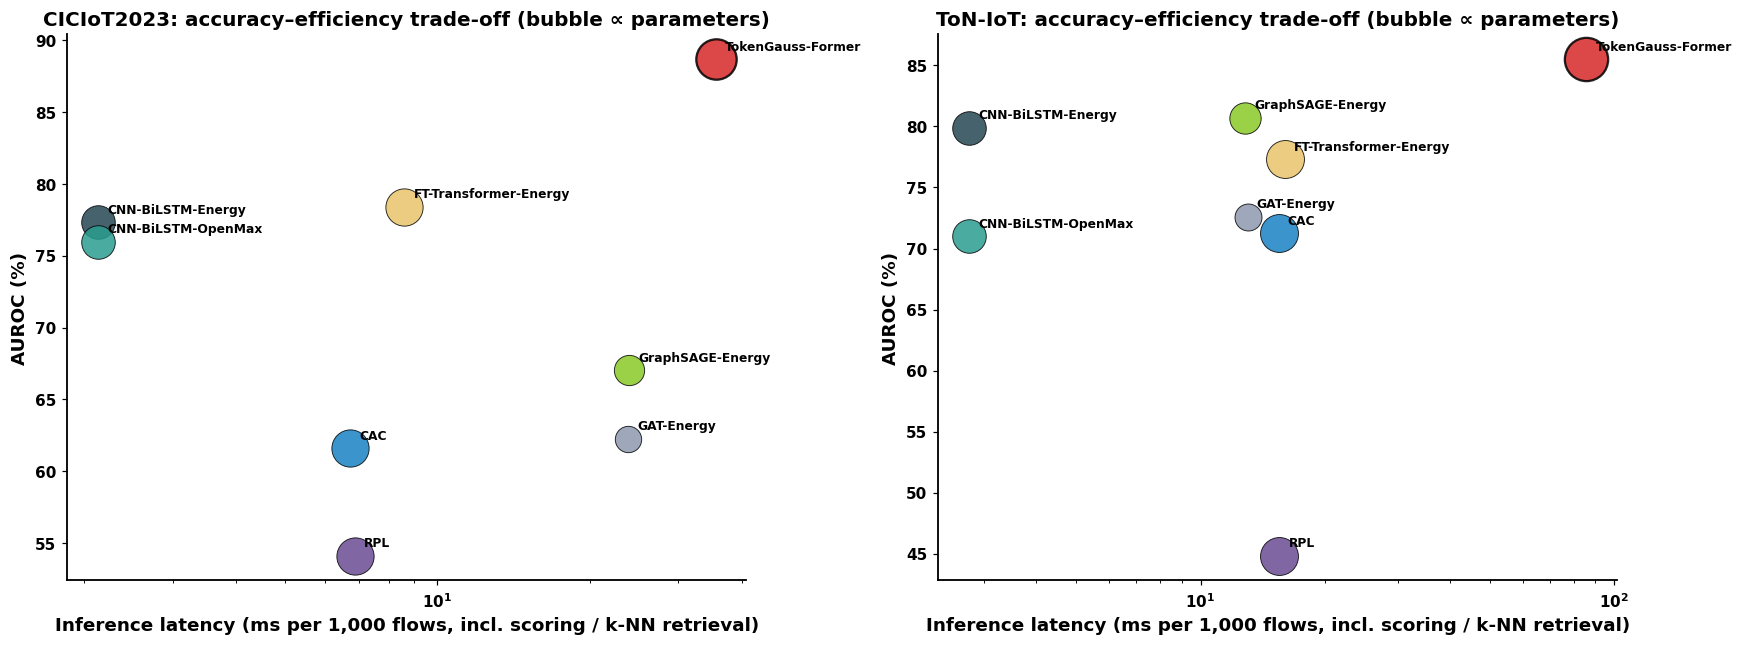

In [24]:
@torch.no_grad()
def measure(ds, method, n=4096, reps=5):
    sp = VALID_SPLITS[ds][0]; B = get_bundle(ds, sp); model = build_model(method, B['nF'], B['C'])
    if hasattr(model, 'bank_x'): model.bank_x = B['X'][torch.tensor(B['idx']['tr'], device=DEVICE)]
    model.load_state_dict(torch.load(os.path.join(D['ckpt'], rid(ds, sp, method, CFG['seeds'][0]) + '_best.pt'), map_location=DEVICE))
    if getattr(model, 'needs_bank_emb', False): model.refresh_bank()
    model.eval(); te = B['idx']['te'][:n]; x = B['X'][torch.tensor(te, device=DEVICE)]; bank = model.bank_x if hasattr(model, 'bank_x') else None
    def step():
        kw = {}
        if method in GRAPH_MODELS:
            I, Dd = knn_torch(x, bank, CFG['k'])
            kw = dict(nidx=torch.tensor(I.astype(np.int64), device=DEVICE), nd=torch.tensor(np.log1p(Dd), device=DEVICE),
                      ndt=torch.zeros(len(I), CFG['k'], device=DEVICE))
        with torch.autocast('cuda', dtype=torch.float16, enabled=AMP):
            for s in range(0, len(x), 1024):
                model(x[s:s + 1024], **{k_: v[s:s + 1024] for k_, v in kw.items()})
    step()
    if DEVICE.type == 'cuda': torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for _ in range(reps): step()
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    dt = (time.time() - t0) / reps
    mem = torch.cuda.max_memory_allocated() / 1e6 if DEVICE.type == 'cuda' else float('nan')
    p = n_params(model)
    return dict(dataset=ds, method=method, params_M=p / 1e6, size_MB=p * 4 / 1e6, ms_per_1k=dt / len(x) * 1000 * 1000,
                throughput=len(x) / dt, peak_mem_MB=mem)

EFF_P = os.path.join(D['tables'], 'T_efficiency_v8.csv')
if os.path.exists(EFF_P): EFF = pd.read_csv(EFF_P)
else:
    rows = [measure(ds, m) for ds in CFG['datasets'] for m in BASELINES]
    for ds, (mname, bb) in [(d_, x_) for d_ in CFG['datasets'] for x_ in [(PROP_TMS, 'TGF'), ('TMS-FT-Transformer', 'FT-Transformer')]]:
        sp = VALID_SPLITS[ds][0]; Bm, mdl = load_backbone(ds, sp, CFG['seeds'][0], bb); enc = mdl.enc
        sub = strat_idx(Bm['y'][Bm['idx']['tr']], 40000); itr = Bm['idx']['tr'][sub]
        st = tm_fit(enc, Bm['X'][torch.tensor(itr, device=DEVICE)], torch.tensor(Bm['y'][itr], device=DEVICE), Bm['C'], TM['gamma'])
        x = Bm['X'][torch.tensor(Bm['idx']['te'][:4096], device=DEVICE)]; tm_raw(enc, x, st)
        if DEVICE.type == 'cuda': torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
        t0 = time.time()
        for _ in range(5):
            with torch.no_grad(): mdl(x[:1024]); tm_raw(enc, x, st)
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        dt = (time.time() - t0) / 5; p = n_params(mdl)
        rows.append(dict(dataset=ds, method=mname, params_M=p / 1e6, size_MB=p * 4 / 1e6 + sum(v.numel() * 4 for v in st.values() if torch.is_tensor(v)) / 1e6,
                         ms_per_1k=dt / len(x) * 1e6, throughput=len(x) / dt, peak_mem_MB=torch.cuda.max_memory_allocated() / 1e6 if DEVICE.type == 'cuda' else float('nan')))
    EFF = pd.DataFrame(rows); EFF.to_csv(EFF_P, index=False)
print(EFF.round(3))
R = load_runs(); Rm = R[(R['variant'] == 'full') & (R['k'] == CFG['k']) & R['dataset'].isin(CFG['datasets']) & (R['label'].isin(MAIN_METHODS))]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, ds in zip(axes, CFG['datasets']):
    au = Rm[Rm['dataset'] == ds].groupby('label')['AUROC'].mean(); E = EFF[EFF['dataset'] == ds].set_index('method')
    for lab in MAIN_METHODS:
        m = LAB2METHOD[lab]; e = E.loc[m]
        ax.scatter(e['ms_per_1k'], au[lab], s=200 + 2500 * e['params_M'], color=MCOL[lab], edgecolors='black', lw=1.5 if lab == PROPOSED else 0.6, alpha=0.85)
        ax.annotate(lab, (e['ms_per_1k'], au[lab]), xytext=(6, 6), textcoords='offset points', fontsize=8, fontweight='bold')
    ax.set_xscale('log'); ax.set_xlabel('Inference latency (ms per 1,000 flows, incl. scoring / k-NN retrieval)'); ax.set_ylabel('AUROC (%)')
    ax.set_title(f'{ds}: accuracy–efficiency trade-off (bubble ∝ parameters)'); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F26_efficiency')

## Stage 18 · Export tables

In [25]:
R = load_runs(); Rm = R[(R['variant'] == 'full') & (R['k'] == CFG['k']) & R['dataset'].isin(CFG['datasets']) & (R['label'].isin(MAIN_METHODS))]
R.to_csv(os.path.join(D['tables'], 'ALL_RUNS_long.csv'), index=False)
ds_rows = []
for ds in CFG['datasets']:
    X, meta = PROC[ds]
    ds_rows.append(dict(Dataset=ds, Role='Internal' if ds == CFG['datasets'][0] else 'External', Flows=len(meta), Features=X.shape[1],
                        Classes=len(FAMS[ds]), Train=int((meta['split'] == 0).sum()), Val=int((meta['split'] == 1).sum()),
                        Test=int((meta['split'] == 2).sum()), Duplicates_removed=META[ds]['duplicates_removed']))
pd.DataFrame(ds_rows).to_csv(os.path.join(D['tables'], 'T_datasets.csv'), index=False)
HP = {k: (str(v) if isinstance(v, (list, dict)) else v) for k, v in CFG.items() if k not in ['cic_files', 'open_splits']}
pd.Series(HP).rename('value').to_csv(os.path.join(D['tables'], 'T_hyperparameters.csv'))

def to_latex(df, name, caption):
    df = df.copy(); esc = lambda v: str(v).replace('_', '\\_').replace('%', '\\%')
    df.columns = [esc(c) for c in df.columns]; df.index = df.index.map(lambda v: esc(v) if not isinstance(v, tuple) else tuple(esc(u) for u in v))
    df = df.map(esc) if hasattr(df, 'map') else df.applymap(esc)
    s = df.to_latex(escape=False, caption=caption, label=f'tab:{name}', column_format='|' + '|'.join(['l'] * df.index.nlevels + ['c'] * len(df.columns)) + '|')
    s = s.replace('\\toprule', '\\hline').replace('\\midrule', '\\hline').replace('\\bottomrule', '\\hline')
    open(os.path.join(D['tables'], name + '.tex'), 'w').write(s)

for ds in CFG['datasets']:
    gm = Rm[Rm['dataset'] == ds].groupby('label')[METRICS].mean(); gs = Rm[Rm['dataset'] == ds].groupby('label')[METRICS].std(ddof=0).fillna(0)
    T = pd.DataFrame({m: gm[m].map('{:.2f}'.format) + ' $\\pm$ ' + gs[m].map('{:.2f}'.format) for m in METRICS}).reindex(MAIN_METHODS)
    to_latex(T, f'main_{ds}', f'Open-set intrusion detection on {ds} (mean $\\pm$ std over protocols and seeds).')
to_latex(pd.DataFrame(ds_rows).set_index('Dataset'), 'datasets', 'Dataset summary after cleaning, deduplication and temporal splitting.')
to_latex(EFF.round(3).set_index(['dataset', 'method']), 'efficiency', 'Computational efficiency.')
to_latex(ST.round(4).set_index(['family', 'scope', 'metric', 'baseline']), 'wilcoxon', 'One-sided Wilcoxon signed-rank tests with Holm correction.')
print(sorted(os.listdir(D['tables']))); print(len(os.listdir(D['figs'])), 'figures in', D['figs'])

['ALL_RUNS_long.csv', 'T_ablation.csv', 'T_ablation_per_split.csv', 'T_confirmation.csv', 'T_confirmation_wilcoxon.csv', 'T_conformal.csv', 'T_datasets.csv', 'T_diad_all_files.csv', 'T_diad_selected_files.csv', 'T_drift.csv', 'T_efficiency_v4.csv', 'T_efficiency_v6.csv', 'T_efficiency_v8.csv', 'T_faithfulness.csv', 'T_hyperparameters.csv', 'T_main_CICIoT2023.csv', 'T_main_ToN-IoT.csv', 'T_per_split_CICIoT2023.csv', 'T_per_split_ToN-IoT.csv', 'T_sensitivity.csv', 'T_unified_CICIoT2023.csv', 'T_unified_ToN-IoT.csv', 'T_wilcoxon_holm.csv', 'datasets.tex', 'efficiency.tex', 'main_CICIoT2023.tex', 'main_ToN-IoT.tex', 'wilcoxon.tex']
38 figures in /content/drive/MyDrive/TempoShield_NIDS/figs


## Stage 19 · Confirmation on never-used CICIoT2023 partitions (Merged13–24)

CICIoT2023-B (157089, 41) {'Spoofing': 25000, 'Recon': 25000, 'Benign': 25000, 'DDoS': 25000, 'DoS': 25000, 'Mirai': 25000, 'Web': 4651, 'BruteForce': 2438} ['S1', 'S2', 'S3']
>> v2_CICIoT2023-B_S1_TGF_noTG_k10_s42
  ep00 loss 0.9853 | val F1 0.7419 acc 0.7466 | 2.9s
  ep01 loss 0.5534 | val F1 0.7850 acc 0.7848 | 2.8s
  ep02 loss 0.4626 | val F1 0.8174 acc 0.8183 | 2.8s
  ep03 loss 0.4225 | val F1 0.8246 acc 0.8240 | 2.8s
  ep04 loss 0.4055 | val F1 0.8160 acc 0.8163 | 2.9s
  ep05 loss 0.3945 | val F1 0.8300 acc 0.8320 | 2.8s
  ep06 loss 0.3877 | val F1 0.8352 acc 0.8349 | 2.8s
  ep07 loss 0.3835 | val F1 0.8316 acc 0.8324 | 2.8s
  ep08 loss 0.3788 | val F1 0.8335 acc 0.8341 | 2.9s
  ep09 loss 0.3773 | val F1 0.8348 acc 0.8337 | 2.9s
  ep10 loss 0.3707 | val F1 0.8313 acc 0.8313 | 2.8s
  ep11 loss 0.3687 | val F1 0.8349 acc 0.8358 | 2.8s
  ep12 loss 0.3668 | val F1 0.8339 acc 0.8349 | 2.8s
  ep13 loss 0.3643 | val F1 0.8404 acc 0.8393 | 2.9s
  ep14 loss 0.3635 | val F1 0.8381 acc 0.83

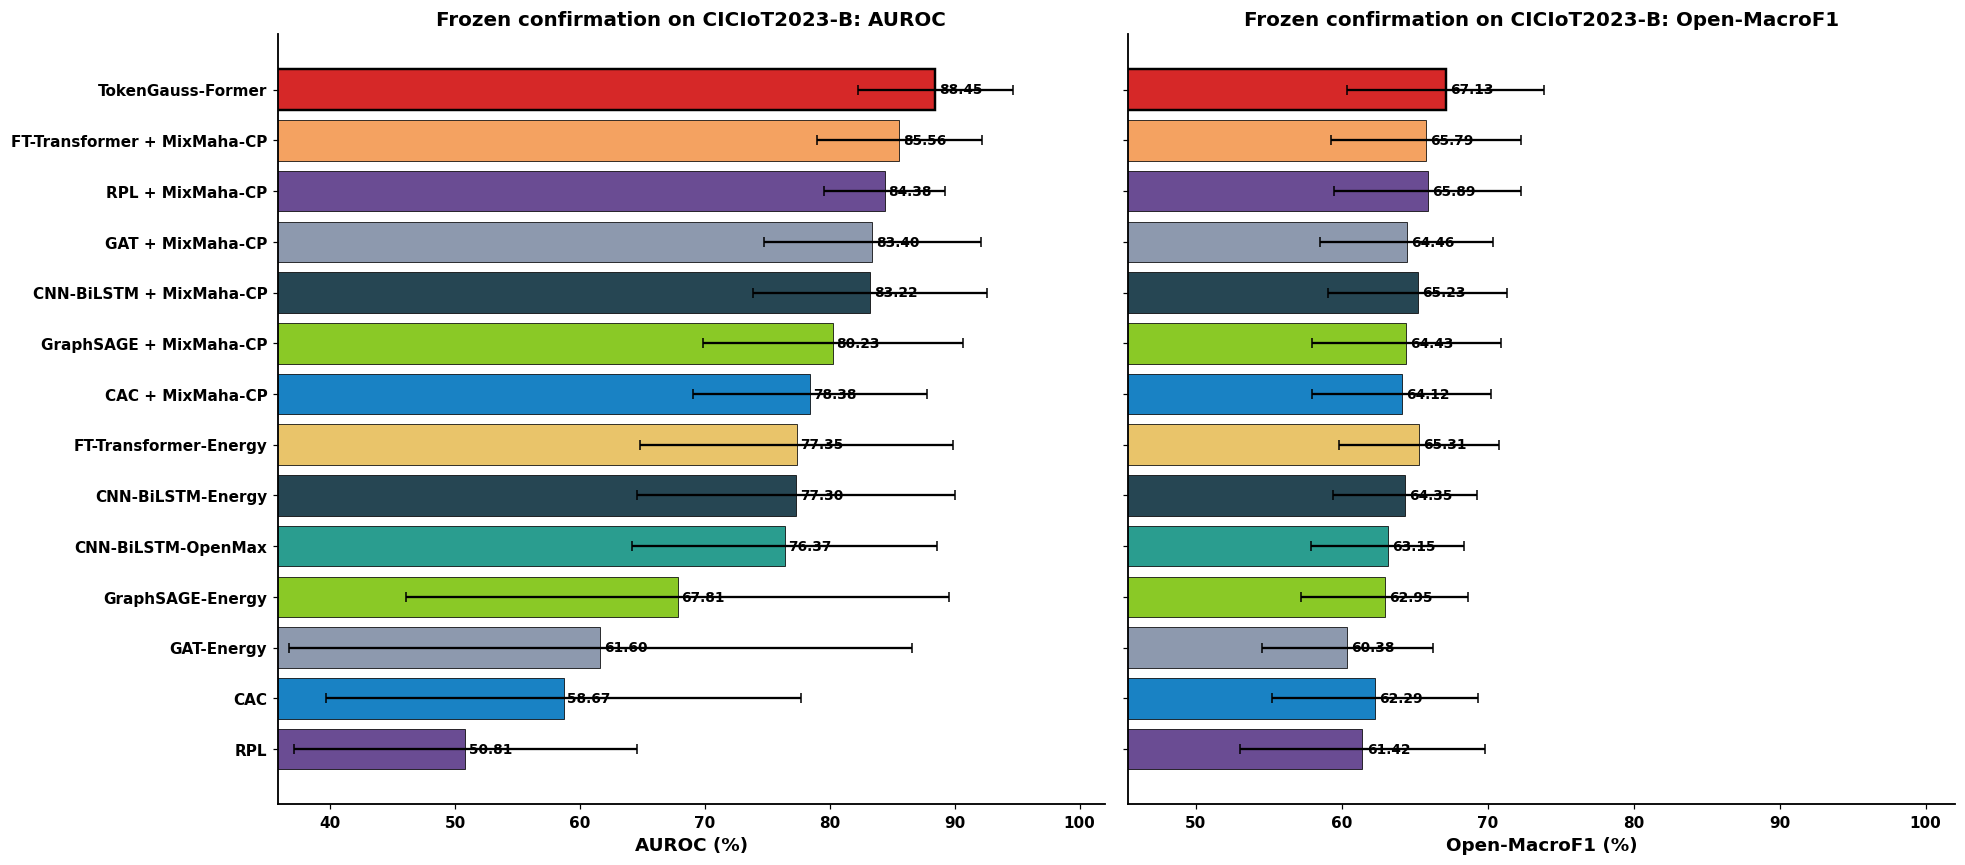

In [26]:
CONF = 'CICIoT2023-B'
RAW[CONF] = fetch(CFG['cic_repo'], CFG['cic_files_confirm'], CONF)
DATA[CONF] = load_cic(RAW[CONF], name=CONF)
META[CONF] = jload(os.path.join(D['interim'], CONF + '_meta.json')); FEATS[CONF] = META[CONF]['features']
FAMS[CONF] = list(DATA[CONF]['family'].value_counts().index); PROC[CONF] = build_proc(CONF)
VALID_SPLITS[CONF] = [sp for sp, unk in CFG['open_splits'][CONF].items() if all(u in FAMS[CONF] for u in unk)]
print(CONF, DATA[CONF].shape, DATA[CONF]['family'].value_counts().to_dict(), VALID_SPLITS[CONF])
for sp in VALID_SPLITS[CONF]:
    build_graph(CONF, sp); GRAPHS[(CONF, sp)] = os.path.join(D['graph'], f'{CONF}_{sp}.npz')
for sp in VALID_SPLITS[CONF]:
    for seed in CFG['seeds']:
        for m in BASELINES:
            run_one(CONF, sp, seed, m); posthoc_unified(CONF, sp, seed, m)
        run_one(CONF, sp, seed, 'TGF', variant=PROP_VAR); tokenmaha_run(CONF, sp, seed, 'TGF', PROP_VAR)

R = load_runs(); RC = R[(R['dataset'] == CONF) & (R['k'] == CFG['k'])]
LABS = MAIN_METHODS[:-1] + [l for l in UNI if l not in MAIN_METHODS] + [PROPOSED]
UCOL = {**UCOL, **MCOL}
RC = RC[RC['label'].isin(LABS) & ((RC['variant'] == 'posthoc') | (RC['variant'] == 'full'))]
CM = ['Closed-Acc', 'AUROC', 'AUPR-Out', 'FPR95', 'Open-MacroF1', 'Unknown-Recall', 'Known-FRR']
gm, gs = RC.groupby('label')[CM].mean(), RC.groupby('label')[CM].std(ddof=0).fillna(0)
TC = pd.DataFrame({m: gm[m].map('{:.2f}'.format) + ' ± ' + gs[m].map('{:.2f}'.format) for m in CM}).reindex(LABS)
TC.to_csv(os.path.join(D['tables'], 'T_confirmation.csv')); print(TC.to_string())
W = RC.pivot_table(index=['split', 'seed'], columns='label', values='AUROC').dropna(axis=1)
rows = []
for m in [l for l in LABS if l != PROPOSED and l in W.columns]:
    try: p = wilcoxon(W[PROPOSED], W[m], alternative='greater', zero_method='zsplit').pvalue
    except ValueError: p = 1.0
    rows.append(dict(baseline=m, mean_diff=float((W[PROPOSED] - W[m]).mean()), p=p, cliffs_delta=cliffs(W[PROPOSED].values, W[m].values)))
SC = pd.DataFrame(rows); SC['p_holm'] = holm(SC['p'].values); SC['significant'] = SC['p_holm'] < 0.05
SC.to_csv(os.path.join(D['tables'], 'T_confirmation_wilcoxon.csv'), index=False); print(SC.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharey=True)
order = gm['AUROC'].reindex(LABS).sort_values().index
for ax, met in zip(axes, ['AUROC', 'Open-MacroF1']):
    col = [MCOL.get(l, UCOL.get(l, '#8d99ae')) for l in order]
    ax.barh(range(len(order)), gm.loc[order, met], xerr=gs.loc[order, met], color=col, edgecolor='black',
            lw=[1.6 if l == PROPOSED else 0.5 for l in order], capsize=3)
    for i, v in enumerate(gm.loc[order, met]): ax.text(v + 0.3, i, f'{v:.2f}', va='center', fontsize=9, fontweight='bold')
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.set_xlim(max(0, gm[met].min() - 15), 102)
    ax.set_xlabel(f'{met} (%)'); ax.set_title(f'Frozen confirmation on {CONF}: {met}'); bold_ticks(ax)
plt.tight_layout(); savefig(fig, 'F30_frozen_confirmation')